# Potato Illness Forecasting Benchmark

This Colab-ready notebook builds recall-oriented forecasting models for potato illness classification.

Key rules implemented here:
- `1` means ill and recall for class `1` is the primary objective.
- Forecast horizons are `2` and `3` days ahead.
- Splits are blocked by year to avoid leakage.
- Thresholds are selected on validation to maximize recall under a precision floor of `0.60` when possible.
- All experiments save plots, reports, best parameters, and a global summary table under `illness_forecasting_outputs/`.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Environment and Dependencies


In [ ]:
%pip install -q pandas numpy scikit-learn imbalanced-learn optuna xgboost lightgbm catboost openpyxl matplotlib seaborn joblib


## Configuration

Update `EXCEL_FILE_PATH` only if the workbook lives somewhere else in your Colab runtime or Google Drive.


In [ ]:
import calendar
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from catboost import CatBoostClassifier
from imblearn.under_sampling import TomekLinks
from lightgbm import LGBMClassifier, early_stopping
from optuna.samplers import TPESampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

EXCEL_FILE_PATH = "/content/Golitcino72-17d2_CLEAN.xlsx"
RANDOM_STATE = 42
MIN_PRECISION = 0.60
OPTUNA_TRIALS = 20
HORIZONS = [2, 3]

OUTPUT_DIR = Path("illness_forecasting_outputs")
PLOTS_DIR = OUTPUT_DIR / "plots"
REPORTS_DIR = OUTPUT_DIR / "reports"
PARAMS_DIR = OUTPUT_DIR / "best_params"
for directory in [OUTPUT_DIR, PLOTS_DIR, REPORTS_DIR, PARAMS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

TRAIN_YEARS = [1972, 1973, 1977, 1982, 1983, 1984, 1987, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 2002, 2004, 2005]
VAL_YEARS = [2006, 2007, 2008, 2009, 2010, 2011]
TEST_YEARS = [2012, 2013, 2014, 2015, 2016, 2017]

MODELS = ["LightGBM", "XGBoost", "Random Forest", "CatBoost", "Logistic Regression"]
VARIANTS = [
    "baseline",
    "interaction_fe",
    "temporal_fe",
    "tomek_only",
    "tomek_interaction_fe",
    "tomek_temporal_fe",
    "tomek_interaction_temporal_fe",
]

VARIANT_DESCRIPTIONS = {
    "baseline": "Base predictors only.",
    "interaction_fe": "Base predictors plus the two manual interaction features.",
    "temporal_fe": "Base predictors plus lag, rolling, and trend features computed within each year only.",
    "tomek_only": "Base predictors with Tomek Links applied on the training split only.",
    "tomek_interaction_fe": "Interaction features plus Tomek Links on the training split only.",
    "tomek_temporal_fe": "Temporal features plus Tomek Links on the training split only.",
    "tomek_interaction_temporal_fe": "Interaction features, temporal features, and Tomek Links on the training split only.",
}

EXPECTED_BASELINE_ROWS = {
    2: {"train": 1512, "val": 504, "test": 504},
    3: {"train": 1494, "val": 498, "test": 498},
}
EXPECTED_TEMPORAL_ROWS = {
    2: {"train": 1386, "val": 462, "test": 462},
    3: {"train": 1368, "val": 456, "test": 456},
}

YEAR_SHEET_PATTERN = re.compile(r"^G?\d{4}$")

STANDARD_COLUMNS = [
    "Year",
    "day",
    "T_min",
    "T_max",
    "Is_rain",
    "Target_Favorable",
    "Y1",
    "Y2",
    "Y2-Y1",
    "Precipitation",
    "T_avg",
    "Cloudiness",
    "Y3",
    "Y4",
    "Precipitation_T_gt_10",
    "T_gt_10",
]

RAW_POSITIONAL_COLUMNS = [
    "Year",
    "day",
    "T_min",
    "T_max",
    "Is_rain",
    "Target_Favorable",
    "Y2",
    "Y1",
    "Y2-Y1",
    "Precipitation",
    "T_avg",
    "Cloudiness",
    "Y3",
    "Y4",
    "Precipitation_T_gt_10",
    "T_gt_10",
]

BASE_FEATURES = [
    "day",
    "T_min",
    "T_max",
    "Is_rain",
    "Y1",
    "Y2",
    "Y2-Y1",
    "Precipitation",
    "T_avg",
    "Cloudiness",
    "Y3",
    "Y4",
    "Precipitation_T_gt_10",
    "T_gt_10",
]

INTERACTION_FEATURES = [
    "FE_Y4_Cloud_Interaction",
    "FE_Cold_Rain_Index",
]

TEMPORAL_SOURCE_COLUMNS = [
    "T_min",
    "T_max",
    "Is_rain",
    "Y1",
    "Y2",
    "Y2-Y1",
    "Precipitation",
    "T_avg",
    "Cloudiness",
    "Y3",
    "Y4",
    "Precipitation_T_gt_10",
    "T_gt_10",
]

LAG_STEPS = [1, 2, 3, 7]
ROLLING_WINDOWS = [3, 7]
ROLLING_STATS = ["mean", "std", "min", "max"]

DATA_CACHE = {}
EXPERIMENT_RESULTS = {}


## Data Loading and Workbook Cleaning

The workbook contains several anomalies relative to the stated schema. The loader below handles them explicitly:
- keeps only valid year sheets matching `G?\d{4}`
- reads only the first 92 seasonal rows per year
- normalizes column order and names
- adds missing columns as `NaN` when a sheet is truncated
- repairs invalid `day` sequences using the canonical seasonal day-of-year range
- preserves `day_raw` for audit


In [ ]:
def canonical_day_sequence(year: int) -> np.ndarray:
    start_day = 153 if calendar.isleap(year) else 152
    return np.arange(start_day, start_day + 92, dtype=int)


def clean_numeric_series(series: pd.Series) -> pd.Series:
    # Ensure we are working with string representations to use .str accessor safely
    text = series.astype(str)
    text = text.str.replace("\xa0", " ", regex=False)
    text = text.str.strip()
    # Replace common string null indicators with actual NaNs
    text = text.replace({"": np.nan, " ": np.nan, "nan": np.nan, "None": np.nan, "<NA>": np.nan})
    # Re-verify string type for subsequent .str calls after .replace
    text = text.astype(str).str.replace("б", "6", regex=False)
    text = text.str.replace(",", ".", regex=False)
    return pd.to_numeric(text, errors="coerce")

def get_temporal_feature_names(source_cols: list[str]) -> list[str]:
    names = []
    for col in source_cols:
        for lag in LAG_STEPS:
            names.append(f"{col}_lag_{lag}")
        for window in ROLLING_WINDOWS:
            for stat in ROLLING_STATS:
                names.append(f"{col}_roll_{window}_{stat}")
        names.append(f"{col}_trend_3_vs_prev3")
    return names

TEMPORAL_FEATURE_NAMES = get_temporal_feature_names(TEMPORAL_SOURCE_COLUMNS)

# ... (rest of the functions remain the same)
def is_valid_day_sequence(year: int, day_values: pd.Series) -> bool:
    if day_values.isna().any():
        return False
    try:
        observed = day_values.astype(int).to_numpy()
    except ValueError:
        return False
    if len(observed) != 92:
        return False
    if not np.all(np.diff(observed) == 1):
        return False
    if observed[0] not in {152, 153}:
        return False
    if observed[-1] != observed[0] + 91:
        return False
    return observed[0] >= 152 and observed[-1] <= 244

def load_excel_dataset(excel_path: str) -> pd.DataFrame:
    excel_file = pd.ExcelFile(excel_path, engine="openpyxl")
    included_sheets = [sheet for sheet in excel_file.sheet_names if YEAR_SHEET_PATTERN.fullmatch(sheet)]
    excluded_sheets = [sheet for sheet in excel_file.sheet_names if sheet not in included_sheets]
    frames = []
    load_audit = []

    for sheet_name in included_sheets:
        year = int(re.search(r"(\d{4})", sheet_name).group(1))
        raw_df = pd.read_excel(excel_path, sheet_name=sheet_name, engine="openpyxl", nrows=92)
        raw_df = raw_df.copy()
        renamed_columns = {}
        for idx, original_col in enumerate(raw_df.columns[: len(RAW_POSITIONAL_COLUMNS)]):
            renamed_columns[original_col] = RAW_POSITIONAL_COLUMNS[idx]
        raw_df = raw_df.rename(columns=renamed_columns)

        for col in RAW_POSITIONAL_COLUMNS:
            if col not in raw_df.columns:
                raw_df[col] = np.nan

        raw_df = raw_df[RAW_POSITIONAL_COLUMNS].copy()
        raw_df["sheet_name"] = sheet_name
        raw_df["Year"] = year
        raw_df["day_raw"] = raw_df["day"]

        for col in [col for col in RAW_POSITIONAL_COLUMNS if col != "Year"]:
            raw_df[col] = clean_numeric_series(raw_df[col])

        valid_day_sequence = is_valid_day_sequence(year, raw_df["day"])
        if valid_day_sequence:
            raw_df["day"] = raw_df["day"].astype(int)
        else:
            raw_df["day"] = canonical_day_sequence(year)

        raw_df["Year"] = year
        raw_df["season_index"] = np.arange(len(raw_df), dtype=int)
        raw_df["day_repaired"] = not valid_day_sequence

        ordered_columns = [
            "sheet_name",
            "Year",
            "day_raw",
            "day",
            "season_index",
            "day_repaired",
            "T_min",
            "T_max",
            "Is_rain",
            "Target_Favorable",
            "Y1",
            "Y2",
            "Y2-Y1",
            "Precipitation",
            "T_avg",
            "Cloudiness",
            "Y3",
            "Y4",
            "Precipitation_T_gt_10",
            "T_gt_10",
        ]
        raw_df = raw_df[ordered_columns]
        frames.append(raw_df)

        load_audit.append(
            {
                "sheet_name": sheet_name,
                "year": year,
                "rows_loaded": len(raw_df),
                "day_repaired": bool(not valid_day_sequence),
                "missing_schema_columns": [
                    col for col in STANDARD_COLUMNS if col not in raw_df.columns or raw_df[col].isna().all()
                ],
            }
        )

    full_df = pd.concat(frames, ignore_index=True)
    full_df = full_df.sort_values(["Year", "day"]).reset_index(drop=True)

    numeric_columns = [col for col in full_df.columns if col not in {"sheet_name"}]
    for col in numeric_columns:
        if col in {"Year", "day", "season_index"}:
            full_df[col] = full_df[col].astype(int)
        elif col == "day_repaired":
            full_df[col] = full_df[col].astype(bool)
        else:
            full_df[col] = pd.to_numeric(full_df[col], errors="coerce")

    full_df.attrs["included_sheets"] = included_sheets
    full_df.attrs["excluded_sheets"] = excluded_sheets
    full_df.attrs["load_audit"] = load_audit
    return full_df

# ... remaining helper functions (add_interaction_features, etc.) remain unchanged

In [ ]:
FULL_DATASET = load_excel_dataset(EXCEL_FILE_PATH)
run_acceptance_checks(FULL_DATASET)

included_sheets = FULL_DATASET.attrs["included_sheets"]
excluded_sheets = FULL_DATASET.attrs["excluded_sheets"]
load_audit_df = pd.DataFrame(FULL_DATASET.attrs["load_audit"]).sort_values("year").reset_index(drop=True)

print(f"Loaded rows: {len(FULL_DATASET)}")
print(f"Included sheets: {included_sheets}")
print(f"Excluded sheets: {excluded_sheets}")
display(load_audit_df[["sheet_name", "year", "rows_loaded", "day_repaired"]])

dataset_overview = (
    FULL_DATASET.groupby("Year")
    .agg(
        rows=("Year", "size"),
        positives=("Target_Favorable", lambda s: int(np.nansum(s))),
        target_missing=("Target_Favorable", lambda s: int(s.isna().sum())),
        repaired_day=("day_repaired", "max"),
    )
    .reset_index()
)
display(dataset_overview.head())

Loaded rows: 2760
Included sheets: ['G1972', 'G1973', '1977', '1982', '1983', '1984', 'G1987', 'G1991', 'G1992', 'G1993', 'G1994', 'G1995', 'G1996', 'G1997', 'G1998', 'G2002', 'G2004', 'G2005', 'G2006', 'G2007', 'G2008', 'G2009', 'G2010', 'G2011', 'G2012', 'G2013', 'G2014', 'G2015', 'G2016', 'G2017']
Excluded sheets: ['Summ3', 'Summ5', 'Y-y', 'корреляция', 'Лист1', 'Лист2', 'Лист3', 'Лист4', 'Лист5']


,sheet_name,year,rows_loaded,day_repaired
0,G1972,1972,92,False
1,G1973,1973,92,False
2,1977,1977,92,False
3,1982,1982,92,False
4,1983,1983,92,False
5,1984,1984,92,False
6,G1987,1987,92,False
7,G1991,1991,92,False
8,G1992,1992,92,False
9,G1993,1993,92,False


,Year,rows,positives,target_missing,repaired_day
0,1972,92,10,6,False
1,1973,92,3,6,False
2,1977,92,17,6,False
3,1982,92,40,6,False
4,1983,92,30,6,False


## LightGBM | Horizon 2 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

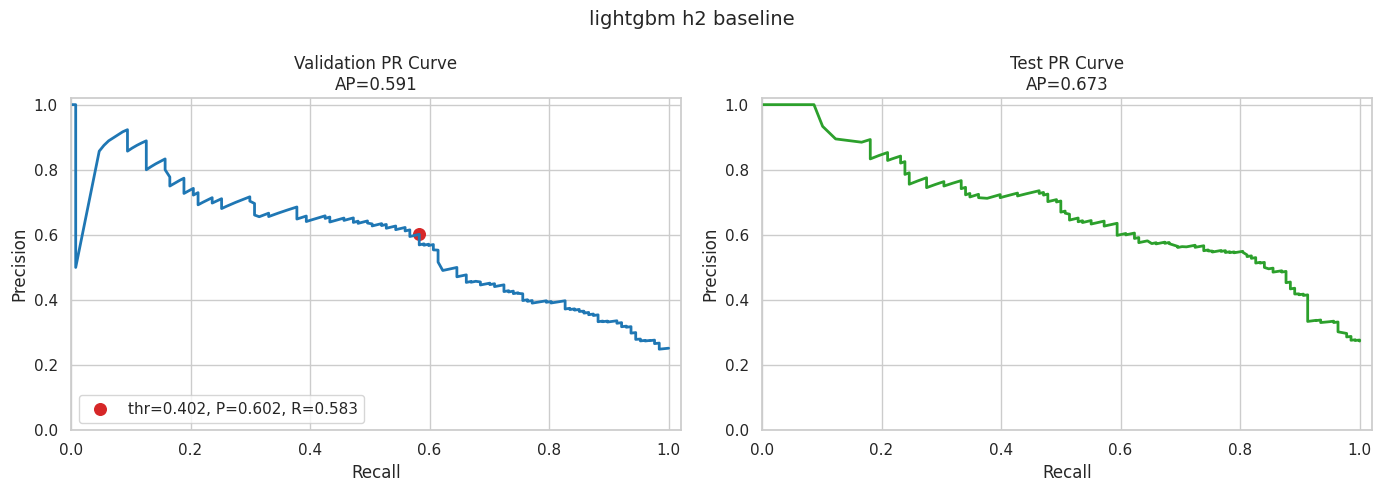

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_baseline,LightGBM,2,baseline,14,1512,504,504,0,0.401745,0.601626,0.582677,0.592,0.590653,0.780739,0.605634,0.623188,0.614286,0.672735,0.824513,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.401745,0.601626,0.582677,0.592,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,474,0.12014,53,5,34,0.729812,0.948872,5.289671,8.909456e-07,2.115457


#### Classification report on test

,precision,recall,f1-score,support
0,0.856354,0.846995,0.851648,366.000000
1,0.605634,0.623188,0.614286,138.000000
accuracy,0.785714,0.785714,0.785714,0.785714
macro avg,0.730994,0.735091,0.732967,504.000000
weighted avg,0.787704,0.785714,0.786656,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,310,56
Actual 1,52,86


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_baseline,LightGBM,2,baseline,14,1512,504,504,0,0.401745,0.601626,0.582677,0.592,0.590653,0.780739,0.605634,0.623188,0.614286,0.672735,0.824513,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=2,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 2 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

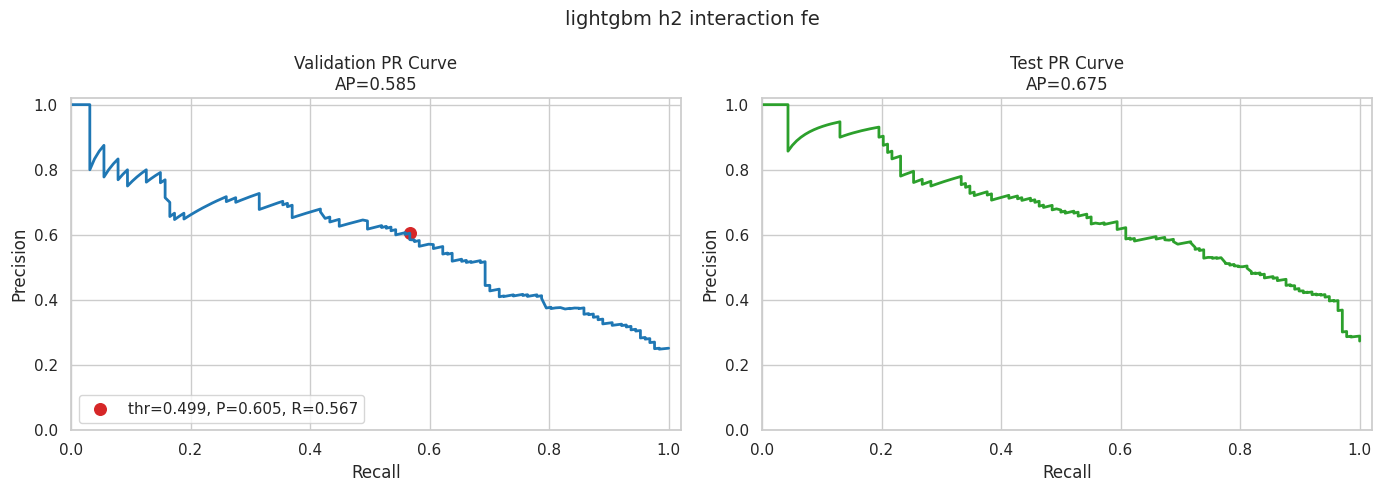

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_interaction_fe,LightGBM,2,interaction_fe,16,1512,504,504,0,0.499191,0.605042,0.566929,0.585366,0.585453,0.782671,0.637097,0.572464,0.603053,0.674583,0.833195,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.499191,0.605042,0.566929,0.585366,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,625,0.064704,52,3,16,0.730073,0.891842,0.00547,0.965861,2.273752


#### Classification report on test

,precision,recall,f1-score,support
0,0.844737,0.877049,0.860590,366.000000
1,0.637097,0.572464,0.603053,138.000000
accuracy,0.793651,0.793651,0.793651,0.793651
macro avg,0.740917,0.724756,0.731822,504.000000
weighted avg,0.787883,0.793651,0.790074,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,321,45
Actual 1,59,79


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_interaction_fe,LightGBM,2,interaction_fe,16,1512,504,504,0,0.499191,0.605042,0.566929,0.585366,0.585453,0.782671,0.637097,0.572464,0.603053,0.674583,0.833195,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=2,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 2 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

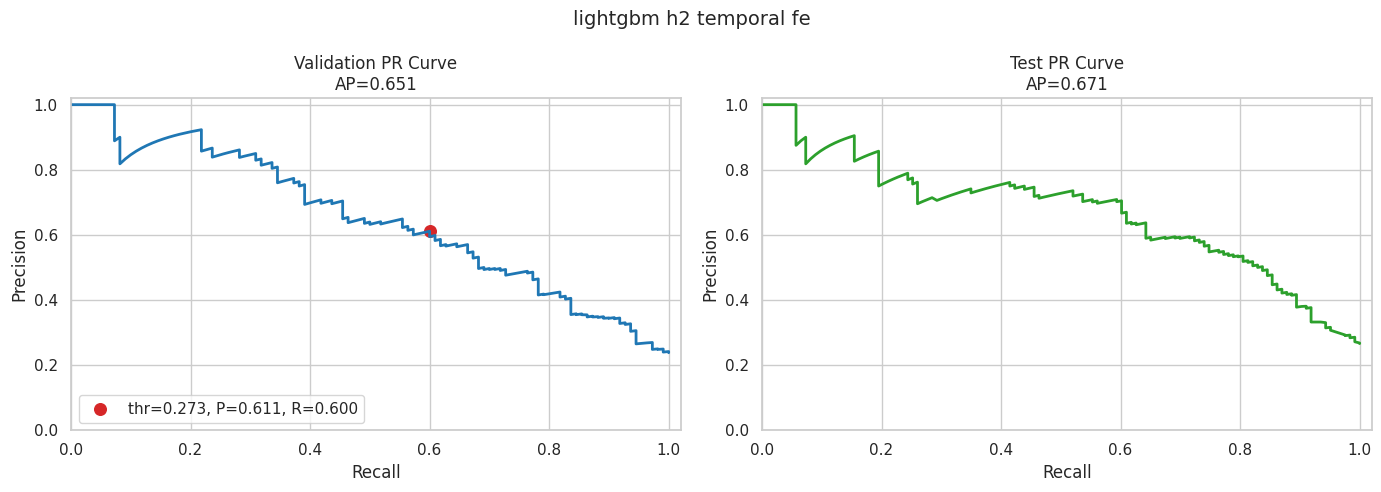

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_temporal_fe,LightGBM,2,temporal_fe,183,1386,462,462,0,0.272692,0.611111,0.6,0.605505,0.650888,0.814799,0.631148,0.626016,0.628571,0.670627,0.829616,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.272692,0.611111,0.6,0.605505,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,487,0.015187,48,6,21,0.91407,0.67987,0.000425,0.002147,1.083826


#### Classification report on test

,precision,recall,f1-score,support
0,0.864706,0.867257,0.865979,339.00000
1,0.631148,0.626016,0.628571,123.00000
accuracy,0.803030,0.803030,0.803030,0.80303
macro avg,0.747927,0.746636,0.747275,462.00000
weighted avg,0.802525,0.803030,0.802773,462.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,294,45
Actual 1,46,77


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_temporal_fe,LightGBM,2,temporal_fe,183,1386,462,462,0,0.272692,0.611111,0.6,0.605505,0.650888,0.814799,0.631148,0.626016,0.628571,0.670627,0.829616,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=2,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 2 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

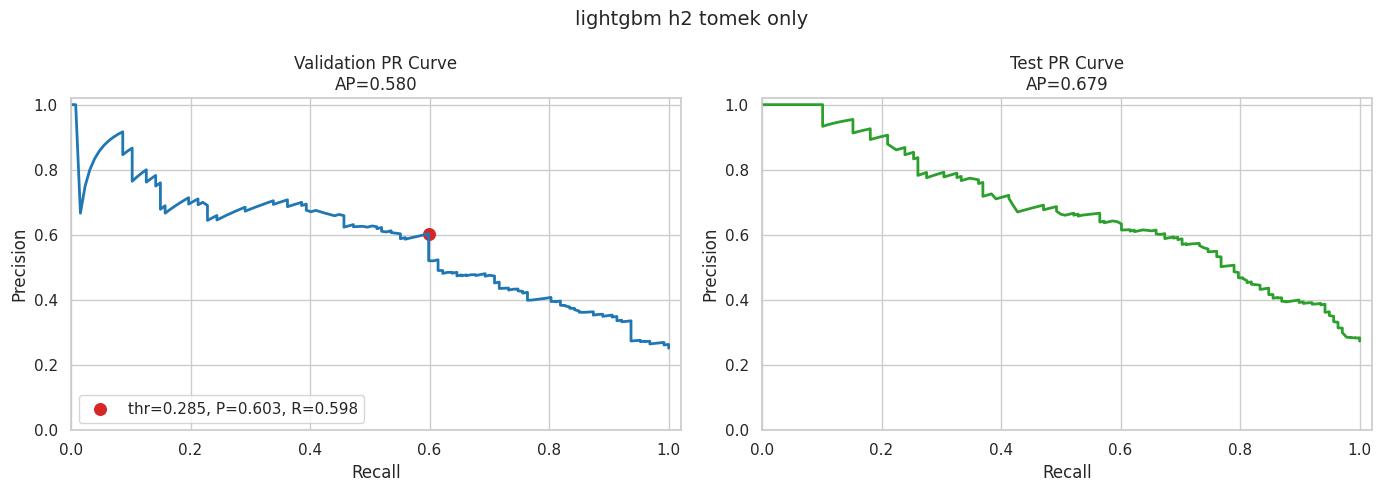

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_only,LightGBM,2,tomek_only,14,1512,504,504,88,0.285189,0.603175,0.598425,0.600791,0.580468,0.784008,0.615942,0.615942,0.615942,0.678594,0.820286,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.285189,0.603175,0.598425,0.600791,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,325,0.010074,59,5,22,0.741798,0.814765,0.026531,8.448386e-07,1.007932


#### Classification report on test

,precision,recall,f1-score,support
0,0.855191,0.855191,0.855191,366.000000
1,0.615942,0.615942,0.615942,138.000000
accuracy,0.789683,0.789683,0.789683,0.789683
macro avg,0.735567,0.735567,0.735567,504.000000
weighted avg,0.789683,0.789683,0.789683,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,313,53
Actual 1,53,85


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_only,LightGBM,2,tomek_only,14,1512,504,504,88,0.285189,0.603175,0.598425,0.600791,0.580468,0.784008,0.615942,0.615942,0.615942,0.678594,0.820286,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=2,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 2 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

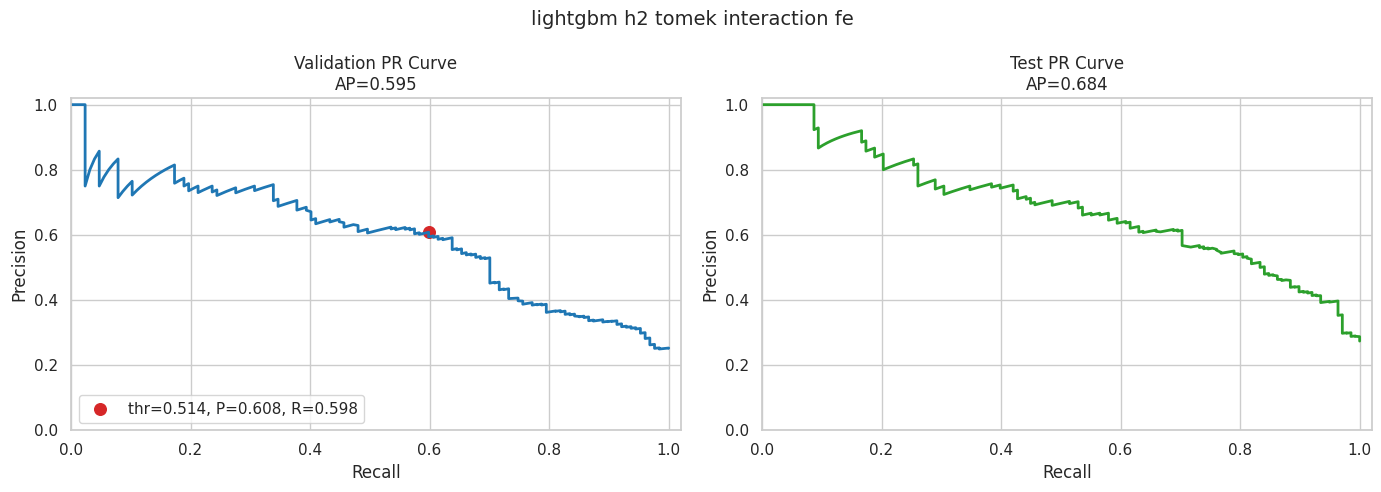

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_interaction_fe,LightGBM,2,tomek_interaction_fe,16,1512,504,504,82,0.513651,0.608,0.598425,0.603175,0.594508,0.784206,0.636364,0.608696,0.622222,0.684215,0.8396,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.513651,0.608,0.598425,0.603175,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,625,0.064704,52,3,16,0.730073,0.891842,0.00547,0.965861,2.19349


#### Classification report on test

,precision,recall,f1-score,support
0,0.854839,0.868852,0.861789,366.000000
1,0.636364,0.608696,0.622222,138.000000
accuracy,0.797619,0.797619,0.797619,0.797619
macro avg,0.745601,0.738774,0.742005,504.000000
weighted avg,0.795018,0.797619,0.796193,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,318,48
Actual 1,54,84


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_interaction_fe,LightGBM,2,tomek_interaction_fe,16,1512,504,504,82,0.513651,0.608,0.598425,0.603175,0.594508,0.784206,0.636364,0.608696,0.622222,0.684215,0.8396,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=2,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 2 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

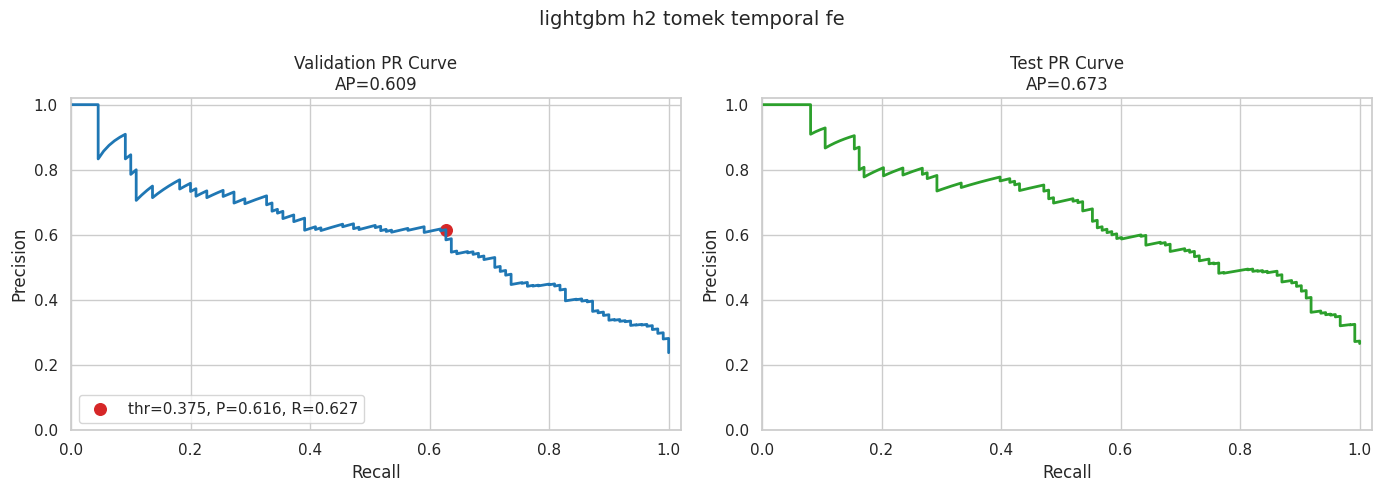

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_temporal_fe,LightGBM,2,tomek_temporal_fe,183,1386,462,462,77,0.374642,0.616071,0.627273,0.621622,0.608789,0.824044,0.6,0.585366,0.592593,0.672635,0.834712,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.374642,0.616071,0.627273,0.621622,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,178,0.022702,31,7,5,0.658985,0.845558,1.272297e-08,0.011195,1.880172


#### Classification report on test

,precision,recall,f1-score,support
0,0.850877,0.858407,0.854626,339.000000
1,0.600000,0.585366,0.592593,123.000000
accuracy,0.785714,0.785714,0.785714,0.785714
macro avg,0.725439,0.721886,0.723609,462.000000
weighted avg,0.784085,0.785714,0.784864,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,291,48
Actual 1,51,72


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_temporal_fe,LightGBM,2,tomek_temporal_fe,183,1386,462,462,77,0.374642,0.616071,0.627273,0.621622,0.608789,0.824044,0.6,0.585366,0.592593,0.672635,0.834712,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=2,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 2 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

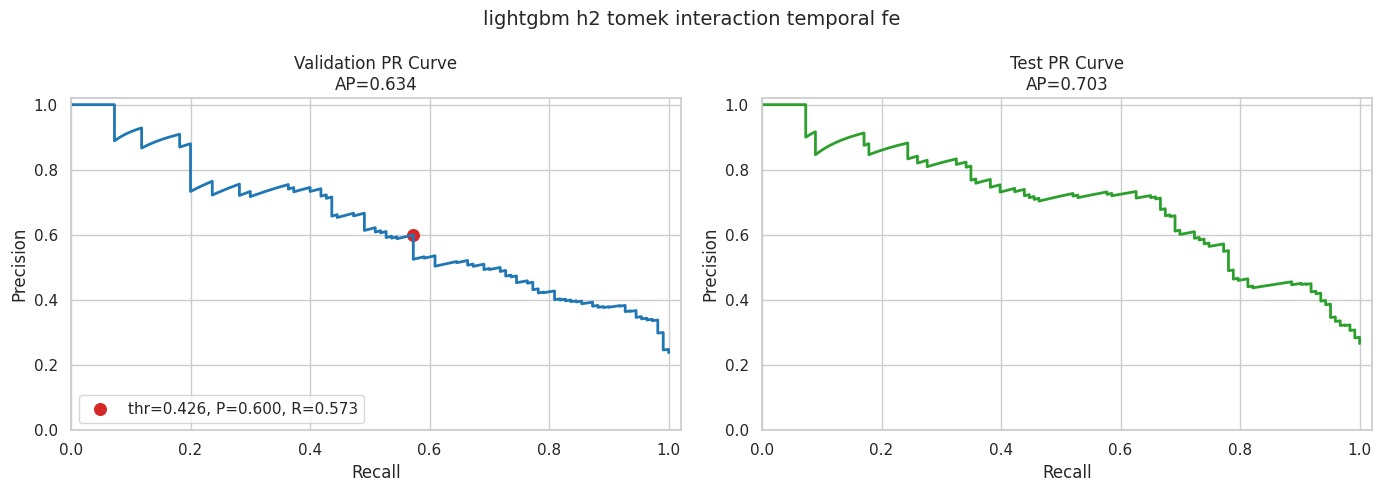

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_interaction_temporal_fe,LightGBM,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.4261,0.6,0.572727,0.586047,0.634154,0.827454,0.713043,0.666667,0.689076,0.702977,0.849366,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.4261,0.6,0.572727,0.586047,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,684,0.10197,121,11,26,0.96875,0.635397,5.805582e-07,2.552969e-08,1.714367


#### Classification report on test

,precision,recall,f1-score,support
0,0.881844,0.902655,0.892128,339.000000
1,0.713043,0.666667,0.689076,123.000000
accuracy,0.839827,0.839827,0.839827,0.839827
macro avg,0.797444,0.784661,0.790602,462.000000
weighted avg,0.836904,0.839827,0.838069,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,306,33
Actual 1,41,82


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h2_tomek_interaction_temporal_fe,LightGBM,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.4261,0.6,0.572727,0.586047,0.634154,0.827454,0.713043,0.666667,0.689076,0.702977,0.849366,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=2,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 3 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

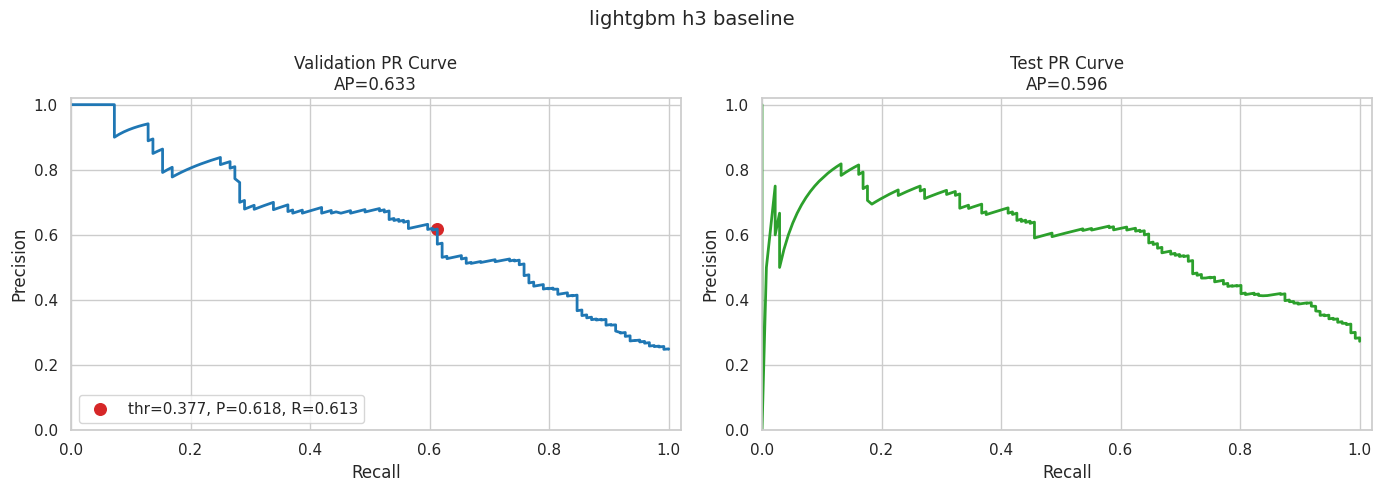

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_baseline,LightGBM,3,baseline,14,1494,498,498,0,0.37651,0.617886,0.612903,0.615385,0.63321,0.800026,0.622047,0.580882,0.60076,0.595571,0.801755,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.37651,0.617886,0.612903,0.615385,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,304,0.035429,17,12,40,0.85935,0.762328,1.578047e-08,0.103789,1.702594


#### Classification report on test

,precision,recall,f1-score,support
0,0.846361,0.867403,0.856753,362.000000
1,0.622047,0.580882,0.600760,136.000000
accuracy,0.789157,0.789157,0.789157,0.789157
macro avg,0.734204,0.724143,0.728757,498.000000
weighted avg,0.785103,0.789157,0.786843,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,314,48
Actual 1,57,79


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_baseline,LightGBM,3,baseline,14,1494,498,498,0,0.37651,0.617886,0.612903,0.615385,0.63321,0.800026,0.622047,0.580882,0.60076,0.595571,0.801755,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=3,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 3 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

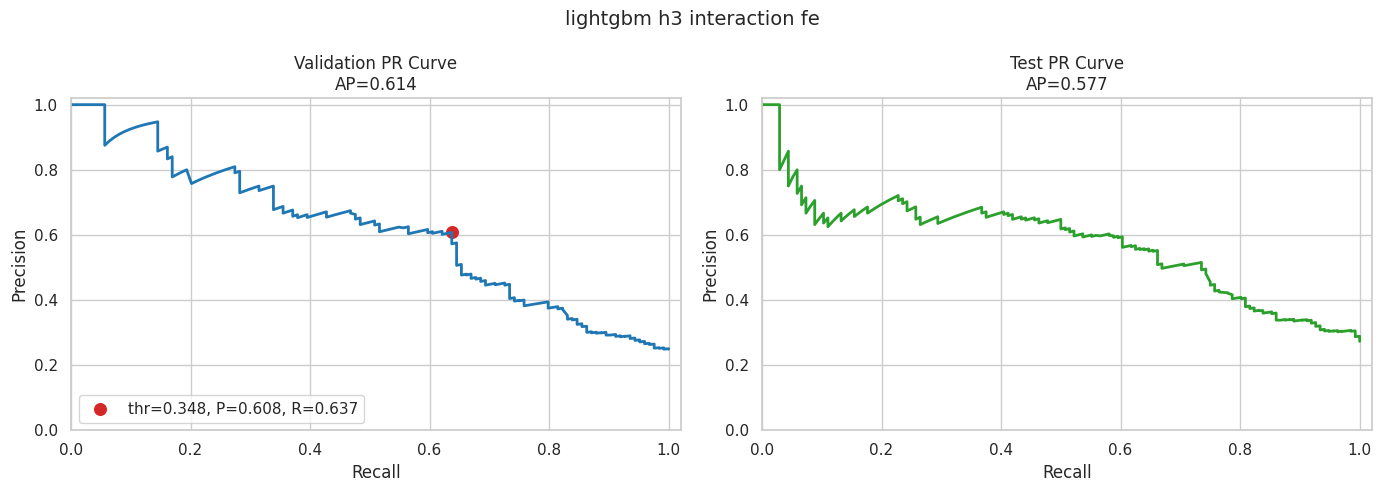

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_interaction_fe,LightGBM,3,interaction_fe,16,1494,498,498,0,0.347807,0.607692,0.637097,0.622047,0.61448,0.774787,0.567568,0.617647,0.591549,0.576884,0.771592,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.347807,0.607692,0.637097,0.622047,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,684,0.10197,121,11,26,0.96875,0.635397,5.805582e-07,2.552969e-08,1.757731


#### Classification report on test

,precision,recall,f1-score,support
0,0.851429,0.823204,0.837079,362.000000
1,0.567568,0.617647,0.591549,136.000000
accuracy,0.767068,0.767068,0.767068,0.767068
macro avg,0.709498,0.720426,0.714314,498.000000
weighted avg,0.773908,0.767068,0.770026,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,298,64
Actual 1,52,84


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_interaction_fe,LightGBM,3,interaction_fe,16,1494,498,498,0,0.347807,0.607692,0.637097,0.622047,0.61448,0.774787,0.567568,0.617647,0.591549,0.576884,0.771592,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=3,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 3 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

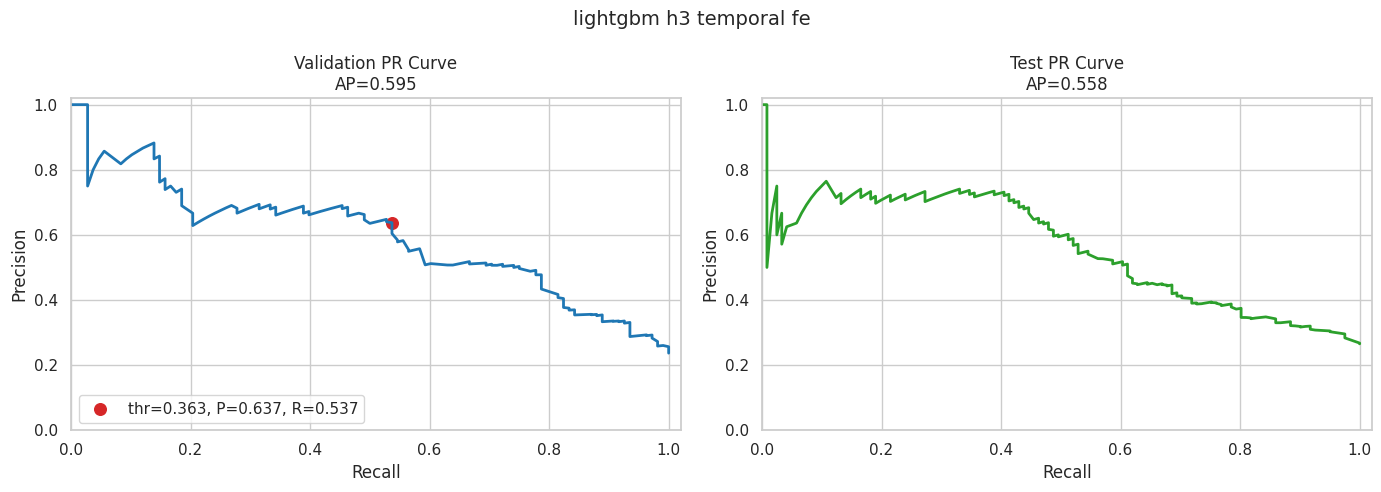

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_temporal_fe,LightGBM,3,temporal_fe,183,1368,456,456,0,0.362803,0.637363,0.537037,0.582915,0.59468,0.810611,0.601942,0.512397,0.553571,0.557891,0.751622,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.362803,0.637363,0.537037,0.582915,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,623,0.037358,41,3,40,0.749422,0.829316,0.025405,0.947818,2.405016


#### Classification report on test

,precision,recall,f1-score,support
0,0.832861,0.877612,0.854651,335.000000
1,0.601942,0.512397,0.553571,121.000000
accuracy,0.780702,0.780702,0.780702,0.780702
macro avg,0.717401,0.695004,0.704111,456.000000
weighted avg,0.771587,0.780702,0.774759,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,294,41
Actual 1,59,62


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_temporal_fe,LightGBM,3,temporal_fe,183,1368,456,456,0,0.362803,0.637363,0.537037,0.582915,0.59468,0.810611,0.601942,0.512397,0.553571,0.557891,0.751622,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=3,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 3 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

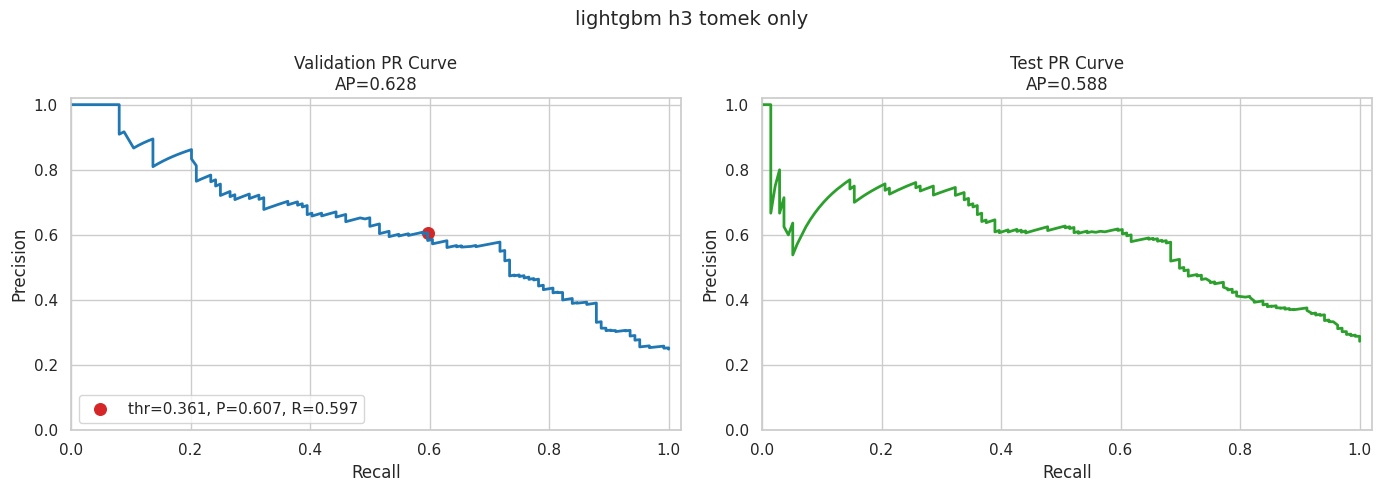

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_only,LightGBM,3,tomek_only,14,1494,498,498,101,0.361309,0.606557,0.596774,0.601626,0.628424,0.800306,0.608,0.558824,0.582375,0.587685,0.78838,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.361309,0.606557,0.596774,0.601626,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,575,0.018136,15,11,30,0.891603,0.908508,4.638760e-08,0.000017,1.208965


#### Classification report on test

,precision,recall,f1-score,support
0,0.839142,0.864641,0.851701,362.000000
1,0.608000,0.558824,0.582375,136.000000
accuracy,0.781124,0.781124,0.781124,0.781124
macro avg,0.723571,0.711732,0.717038,498.000000
weighted avg,0.776019,0.781124,0.778150,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,313,49
Actual 1,60,76


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_only,LightGBM,3,tomek_only,14,1494,498,498,101,0.361309,0.606557,0.596774,0.601626,0.628424,0.800306,0.608,0.558824,0.582375,0.587685,0.78838,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=3,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 3 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

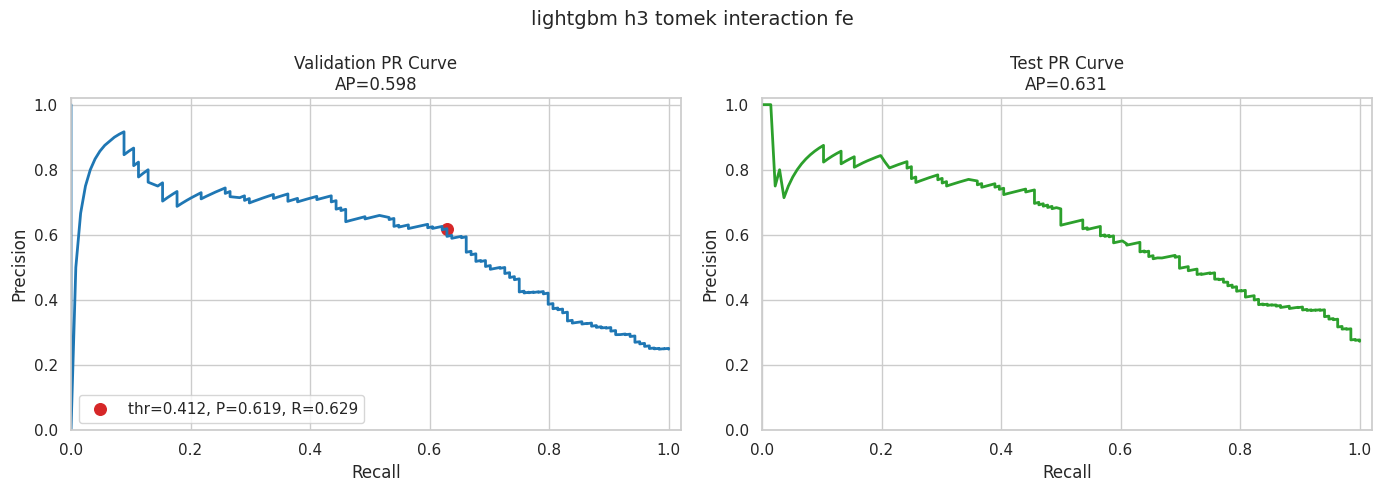

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_interaction_fe,LightGBM,3,tomek_interaction_fe,16,1494,498,498,95,0.411589,0.619048,0.629032,0.624,0.597967,0.786474,0.646018,0.536765,0.586345,0.631299,0.798789,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.411589,0.619048,0.629032,0.624,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,359,0.027205,53,11,36,0.939016,0.812239,0.00001,0.000192,2.927565


#### Classification report on test

,precision,recall,f1-score,support
0,0.836364,0.889503,0.862115,362.000000
1,0.646018,0.536765,0.586345,136.000000
accuracy,0.793173,0.793173,0.793173,0.793173
macro avg,0.741191,0.713134,0.724230,498.000000
weighted avg,0.784382,0.793173,0.786805,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,322,40
Actual 1,63,73


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_interaction_fe,LightGBM,3,tomek_interaction_fe,16,1494,498,498,95,0.411589,0.619048,0.629032,0.624,0.597967,0.786474,0.646018,0.536765,0.586345,0.631299,0.798789,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=3,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 3 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

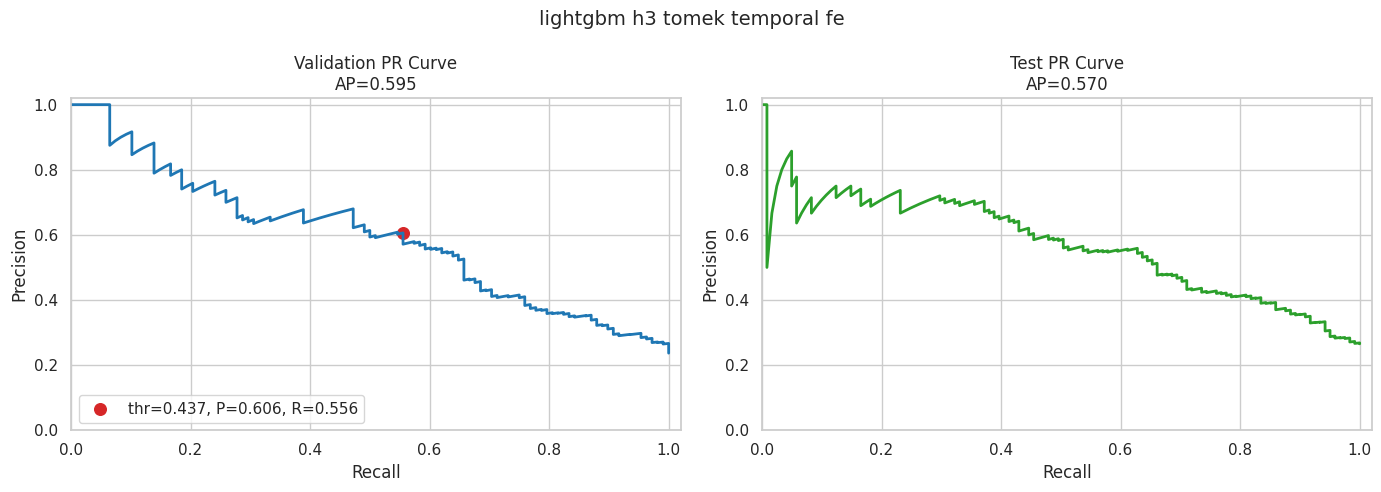

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_temporal_fe,LightGBM,3,tomek_temporal_fe,183,1368,456,456,74,0.436824,0.606061,0.555556,0.57971,0.594675,0.790443,0.558559,0.512397,0.534483,0.570077,0.774689,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.436824,0.606061,0.555556,0.57971,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,556,0.030696,71,10,40,0.99773,0.791098,1.227216e-08,0.419725,2.277978


#### Classification report on test

,precision,recall,f1-score,support
0,0.828986,0.853731,0.841176,335.000000
1,0.558559,0.512397,0.534483,121.000000
accuracy,0.763158,0.763158,0.763158,0.763158
macro avg,0.693772,0.683064,0.687830,456.000000
weighted avg,0.757227,0.763158,0.759795,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,286,49
Actual 1,59,62


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_temporal_fe,LightGBM,3,tomek_temporal_fe,183,1368,456,456,74,0.436824,0.606061,0.555556,0.57971,0.594675,0.790443,0.558559,0.512397,0.534483,0.570077,0.774689,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=3,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## LightGBM | Horizon 3 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

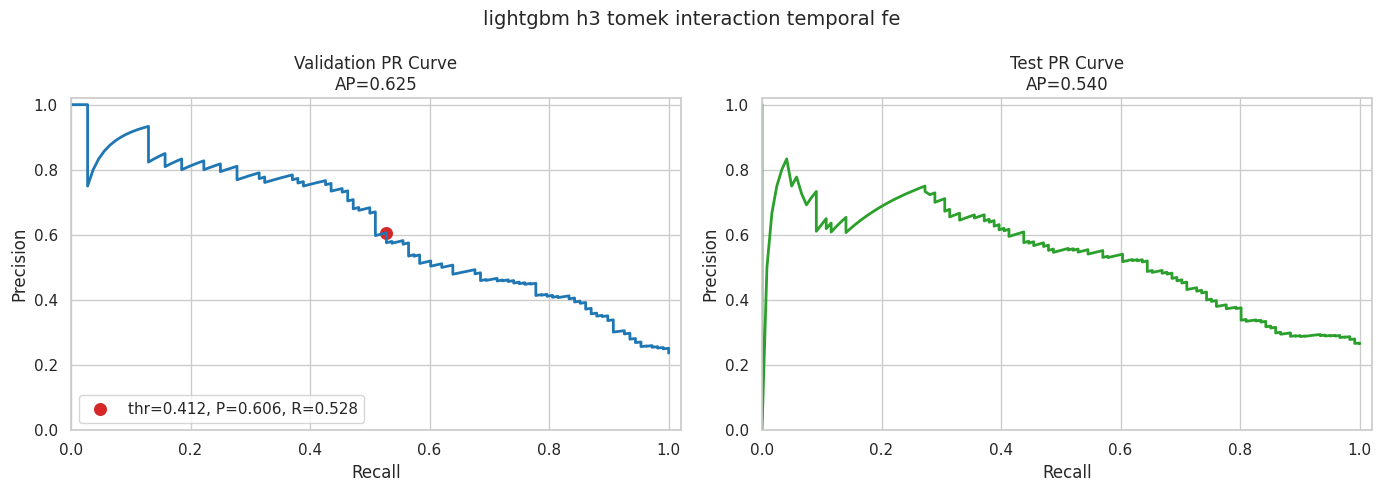

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_interaction_temporal_fe,LightGBM,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.41164,0.606383,0.527778,0.564356,0.625498,0.805316,0.564356,0.471074,0.513514,0.539513,0.741964,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.41164,0.606383,0.527778,0.564356,True,False


#### Best hyperparameters

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,543,0.136102,117,7,19,0.718155,0.670642,6.789187,0.028214,1.879762


#### Classification report on test

,precision,recall,f1-score,support
0,0.819718,0.868657,0.843478,335.000000
1,0.564356,0.471074,0.513514,121.000000
accuracy,0.763158,0.763158,0.763158,0.763158
macro avg,0.692037,0.669866,0.678496,456.000000
weighted avg,0.751958,0.763158,0.755922,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,291,44
Actual 1,64,57


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,lightgbm_h3_tomek_interaction_temporal_fe,LightGBM,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.41164,0.606383,0.527778,0.564356,0.625498,0.805316,0.564356,0.471074,0.513514,0.539513,0.741964,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="LightGBM",
    horizon=3,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 2 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

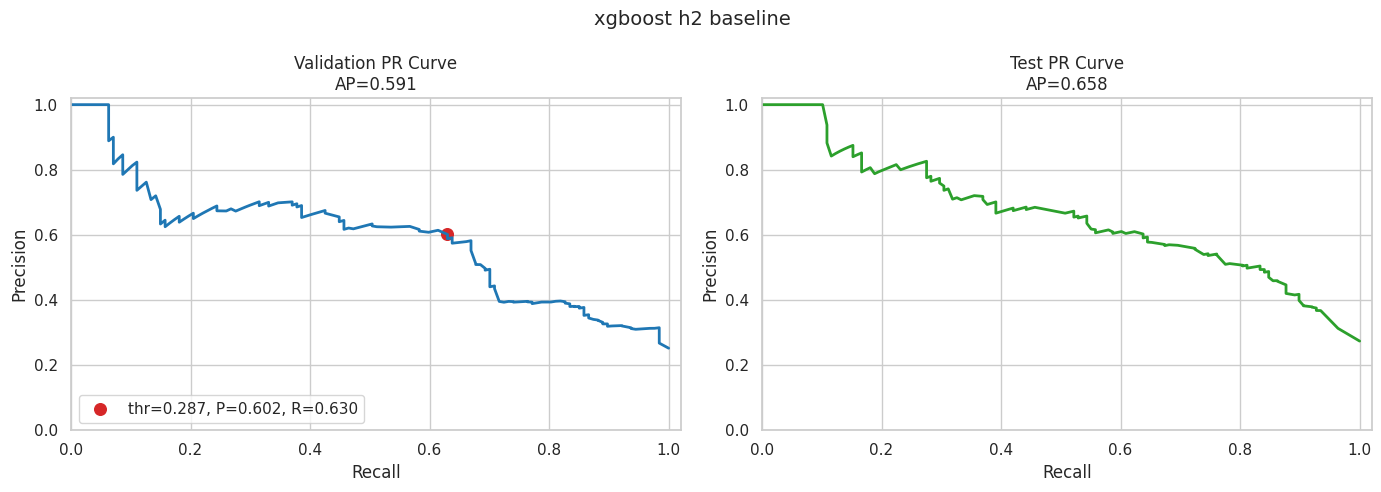

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_baseline,XGBoost,2,baseline,14,1512,504,504,0,0.287152,0.601504,0.629921,0.615385,0.59137,0.790232,0.60274,0.637681,0.619718,0.657646,0.819365,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.287152,0.601504,0.629921,0.615385,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,699,0.019422,4,3,0.95181,0.862577,4.661948,0.000011,0.000031,1.014269


#### Classification report on test

,precision,recall,f1-score,support
0,0.860335,0.841530,0.850829,366.000000
1,0.602740,0.637681,0.619718,138.000000
accuracy,0.785714,0.785714,0.785714,0.785714
macro avg,0.731537,0.739606,0.735274,504.000000
weighted avg,0.789803,0.785714,0.787548,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,308,58
Actual 1,50,88


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_baseline,XGBoost,2,baseline,14,1512,504,504,0,0.287152,0.601504,0.629921,0.615385,0.59137,0.790232,0.60274,0.637681,0.619718,0.657646,0.819365,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=2,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 2 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

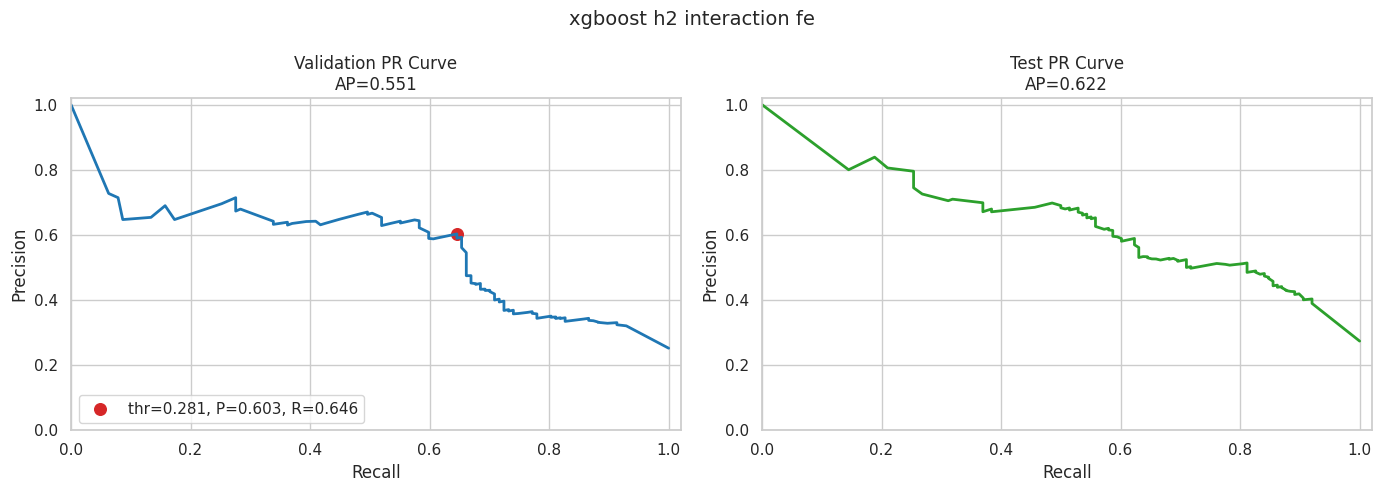

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_interaction_fe,XGBoost,2,interaction_fe,16,1512,504,504,0,0.280997,0.602941,0.645669,0.623574,0.551254,0.770578,0.584507,0.601449,0.592857,0.621732,0.812238,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.280997,0.602941,0.645669,0.623574,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,498,0.010275,6,5,0.789086,0.984238,4.954752,0.000007,3.447349,1.006253


#### Classification report on test

,precision,recall,f1-score,support
0,0.848066,0.838798,0.843407,366.00000
1,0.584507,0.601449,0.592857,138.00000
accuracy,0.773810,0.773810,0.773810,0.77381
macro avg,0.716287,0.720124,0.718132,504.00000
weighted avg,0.775901,0.773810,0.774804,504.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,307,59
Actual 1,55,83


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_interaction_fe,XGBoost,2,interaction_fe,16,1512,504,504,0,0.280997,0.602941,0.645669,0.623574,0.551254,0.770578,0.584507,0.601449,0.592857,0.621732,0.812238,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=2,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 2 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

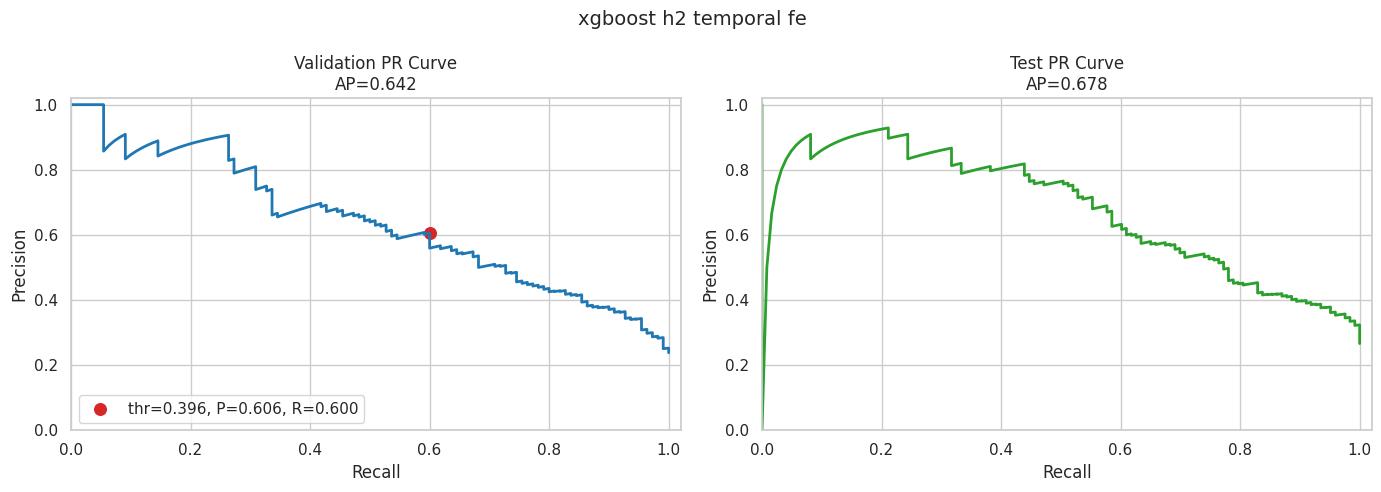

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_temporal_fe,XGBoost,2,temporal_fe,183,1386,462,462,0,0.395982,0.605505,0.6,0.60274,0.641654,0.827815,0.631579,0.585366,0.607595,0.67804,0.836247,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.395982,0.605505,0.6,0.60274,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,486,0.023234,8,3,0.639378,0.742641,0.935497,0.121504,0.000009,2.966262


#### Classification report on test

,precision,recall,f1-score,support
0,0.853448,0.876106,0.864629,339.000000
1,0.631579,0.585366,0.607595,123.000000
accuracy,0.798701,0.798701,0.798701,0.798701
macro avg,0.742514,0.730736,0.736112,462.000000
weighted avg,0.794379,0.798701,0.796198,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,297,42
Actual 1,51,72


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_temporal_fe,XGBoost,2,temporal_fe,183,1386,462,462,0,0.395982,0.605505,0.6,0.60274,0.641654,0.827815,0.631579,0.585366,0.607595,0.67804,0.836247,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=2,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 2 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

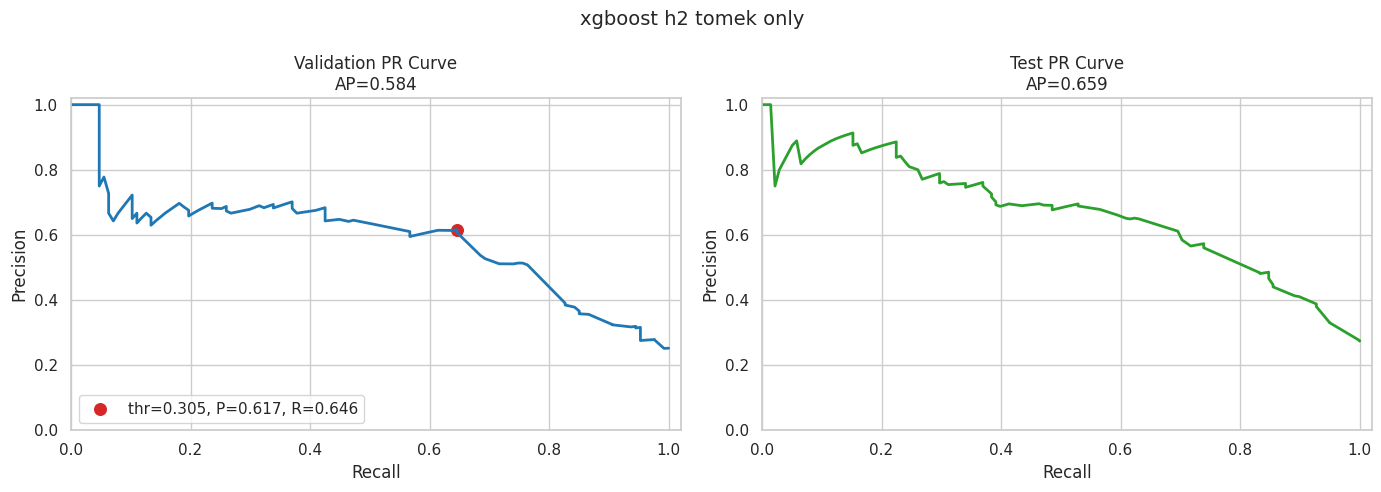

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_only,XGBoost,2,tomek_only,14,1512,504,504,88,0.304509,0.616541,0.645669,0.630769,0.583961,0.799296,0.649254,0.630435,0.639706,0.659064,0.826641,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.304509,0.616541,0.645669,0.630769,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,487,0.015187,5,5,0.782428,0.91407,0.998369,0.000425,0.002147,1.080039


#### Classification report on test

,precision,recall,f1-score,support
0,0.862162,0.871585,0.866848,366.000000
1,0.649254,0.630435,0.639706,138.000000
accuracy,0.805556,0.805556,0.805556,0.805556
macro avg,0.755708,0.751010,0.753277,504.000000
weighted avg,0.803866,0.805556,0.804654,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,319,47
Actual 1,51,87


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_only,XGBoost,2,tomek_only,14,1512,504,504,88,0.304509,0.616541,0.645669,0.630769,0.583961,0.799296,0.649254,0.630435,0.639706,0.659064,0.826641,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=2,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 2 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

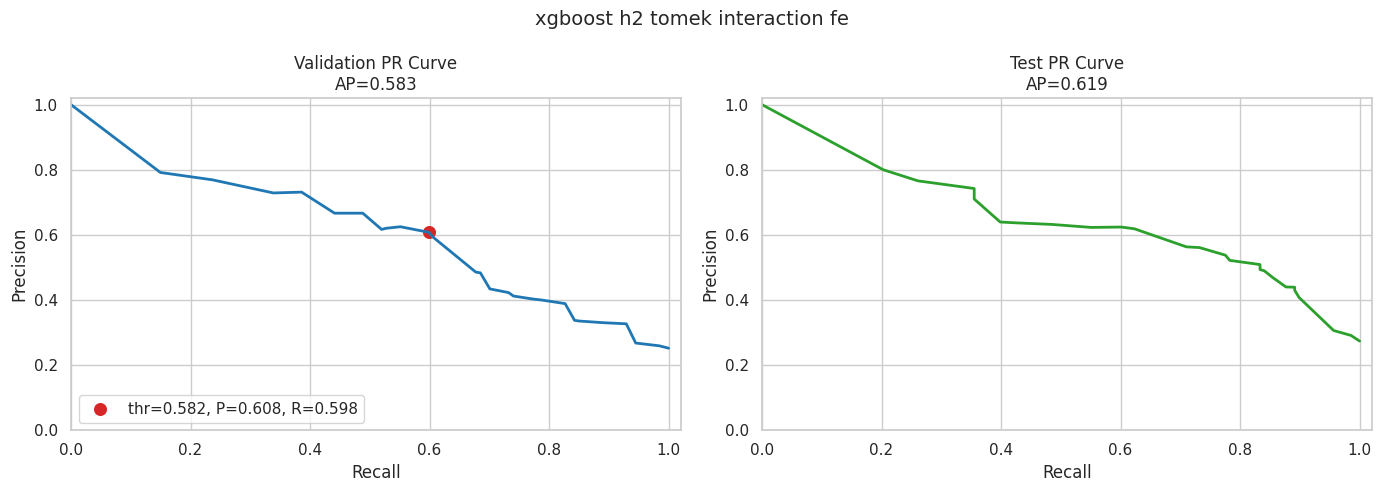

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_interaction_fe,XGBoost,2,tomek_interaction_fe,16,1512,504,504,82,0.58155,0.608,0.598425,0.603175,0.583103,0.781564,0.62406,0.601449,0.612546,0.618805,0.815673,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.58155,0.608,0.598425,0.603175,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,356,0.172547,8,8,0.662407,0.662398,0.290418,0.624576,0.002571,3.247305


#### Classification report on test

,precision,recall,f1-score,support
0,0.851752,0.863388,0.857531,366.000000
1,0.624060,0.601449,0.612546,138.000000
accuracy,0.791667,0.791667,0.791667,0.791667
macro avg,0.737906,0.732419,0.735038,504.000000
weighted avg,0.789408,0.791667,0.790451,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,316,50
Actual 1,55,83


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_interaction_fe,XGBoost,2,tomek_interaction_fe,16,1512,504,504,82,0.58155,0.608,0.598425,0.603175,0.583103,0.781564,0.62406,0.601449,0.612546,0.618805,0.815673,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=2,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 2 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

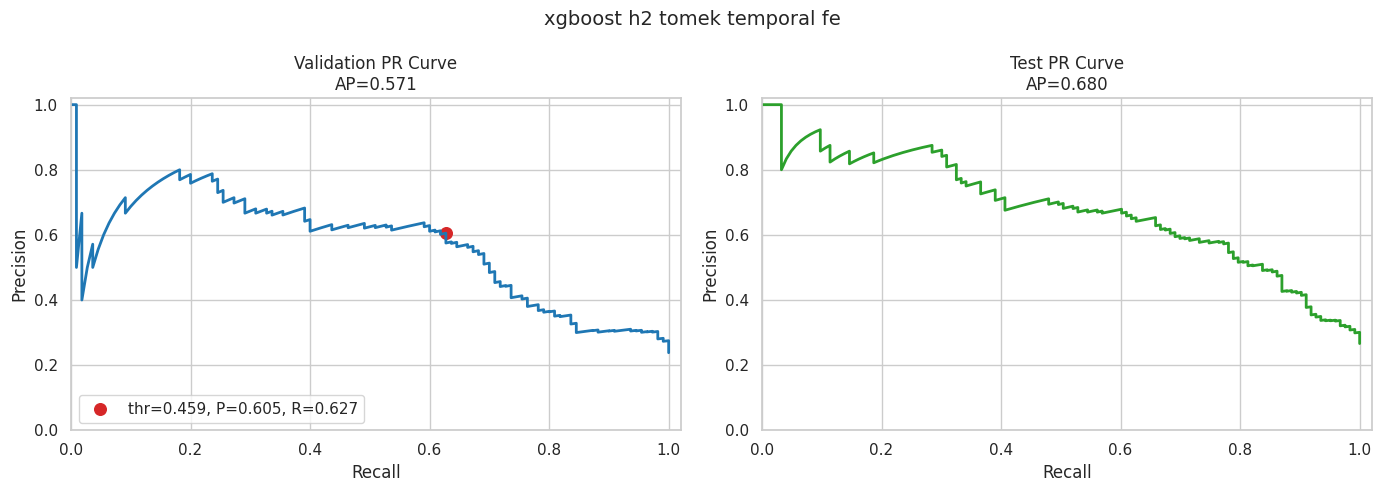

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_temporal_fe,XGBoost,2,tomek_temporal_fe,183,1386,462,462,77,0.459193,0.605263,0.627273,0.616071,0.570516,0.795919,0.630769,0.666667,0.648221,0.680239,0.84114,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.459193,0.605263,0.627273,0.616071,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,691,0.046892,4,12,0.601896,0.855787,1.808568,0.000024,0.07477,1.94398


#### Classification report on test

,precision,recall,f1-score,support
0,0.876506,0.858407,0.867362,339.000000
1,0.630769,0.666667,0.648221,123.000000
accuracy,0.807359,0.807359,0.807359,0.807359
macro avg,0.753638,0.762537,0.757792,462.000000
weighted avg,0.811083,0.807359,0.809019,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,291,48
Actual 1,41,82


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_temporal_fe,XGBoost,2,tomek_temporal_fe,183,1386,462,462,77,0.459193,0.605263,0.627273,0.616071,0.570516,0.795919,0.630769,0.666667,0.648221,0.680239,0.84114,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=2,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 2 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

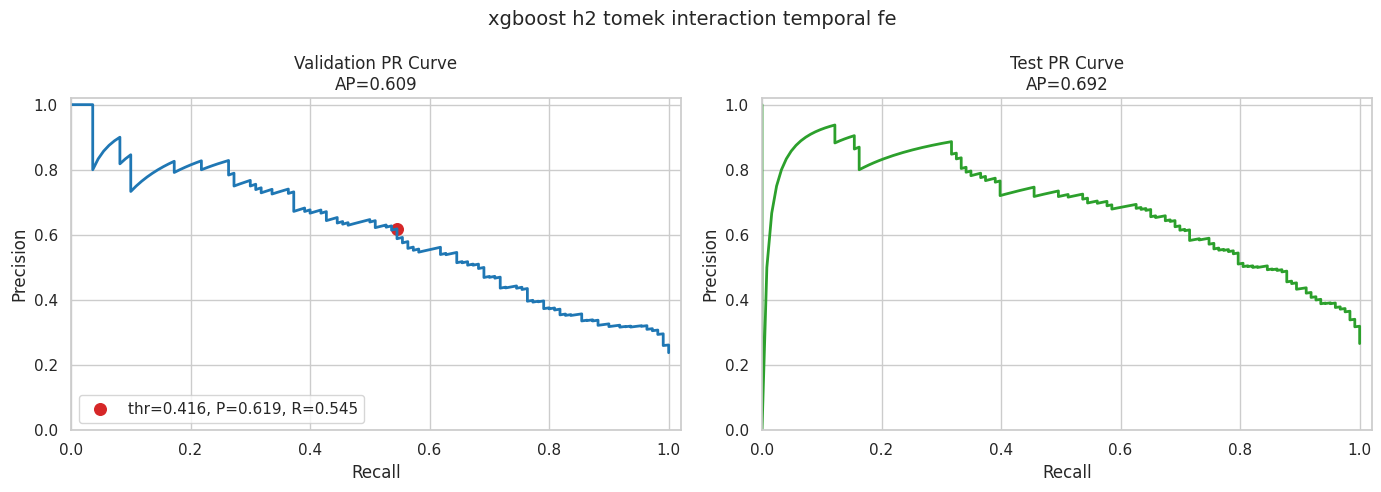

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_interaction_temporal_fe,XGBoost,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.416002,0.618557,0.545455,0.57971,0.609196,0.805372,0.693694,0.626016,0.65812,0.692198,0.859055,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.416002,0.618557,0.545455,0.57971,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,217,0.04408,3,11,0.703512,0.865009,1.558555,0.000479,0.000833,1.358373


#### Classification report on test

,precision,recall,f1-score,support
0,0.868946,0.899705,0.884058,339.00000
1,0.693694,0.626016,0.658120,123.00000
accuracy,0.826840,0.826840,0.826840,0.82684
macro avg,0.781320,0.762861,0.771089,462.00000
weighted avg,0.822288,0.826840,0.823906,462.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,305,34
Actual 1,46,77


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h2_tomek_interaction_temporal_fe,XGBoost,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.416002,0.618557,0.545455,0.57971,0.609196,0.805372,0.693694,0.626016,0.65812,0.692198,0.859055,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=2,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 3 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

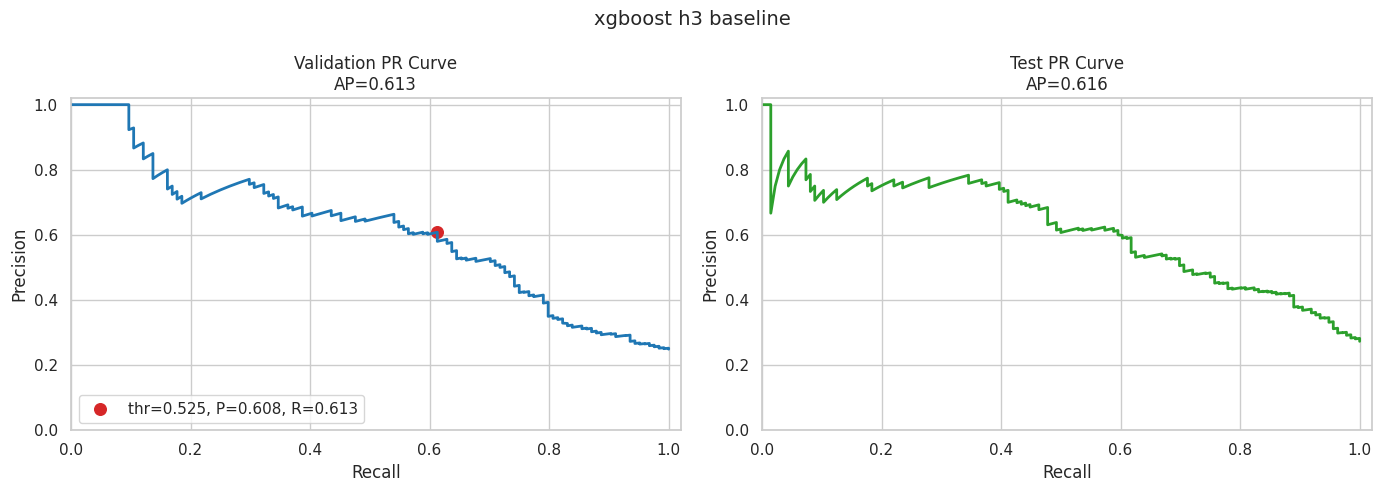

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_baseline,XGBoost,3,baseline,14,1494,498,498,0,0.524517,0.608,0.612903,0.610442,0.613134,0.777935,0.614173,0.573529,0.593156,0.616099,0.798312,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.524517,0.608,0.612903,0.610442,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,620,0.027133,10,11,0.928189,0.838176,3.308851,1.078609e-08,1.255749e-08,2.827573


#### Classification report on test

,precision,recall,f1-score,support
0,0.843666,0.864641,0.854025,362.000000
1,0.614173,0.573529,0.593156,136.000000
accuracy,0.785141,0.785141,0.785141,0.785141
macro avg,0.728919,0.719085,0.723590,498.000000
weighted avg,0.780993,0.785141,0.782783,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,313,49
Actual 1,58,78


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_baseline,XGBoost,3,baseline,14,1494,498,498,0,0.524517,0.608,0.612903,0.610442,0.613134,0.777935,0.614173,0.573529,0.593156,0.616099,0.798312,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=3,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 3 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

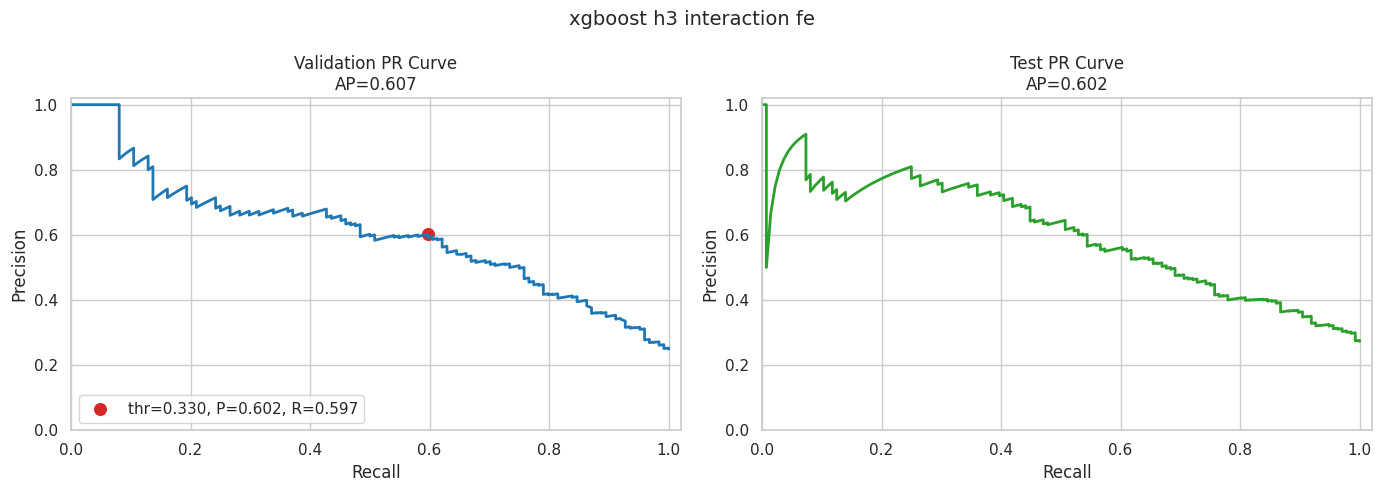

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_interaction_fe,XGBoost,3,interaction_fe,16,1494,498,498,0,0.329784,0.601626,0.596774,0.59919,0.606907,0.8045,0.6,0.529412,0.5625,0.601844,0.780092,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.329784,0.601626,0.596774,0.59919,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,575,0.018136,3,10,0.882743,0.891603,3.856352,4.638760e-08,0.000017,1.22248


#### Classification report on test

,precision,recall,f1-score,support
0,0.830688,0.867403,0.848649,362.0000
1,0.600000,0.529412,0.562500,136.0000
accuracy,0.775100,0.775100,0.775100,0.7751
macro avg,0.715344,0.698408,0.705574,498.0000
weighted avg,0.767689,0.775100,0.770504,498.0000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,314,48
Actual 1,64,72


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_interaction_fe,XGBoost,3,interaction_fe,16,1494,498,498,0,0.329784,0.601626,0.596774,0.59919,0.606907,0.8045,0.6,0.529412,0.5625,0.601844,0.780092,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=3,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 3 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

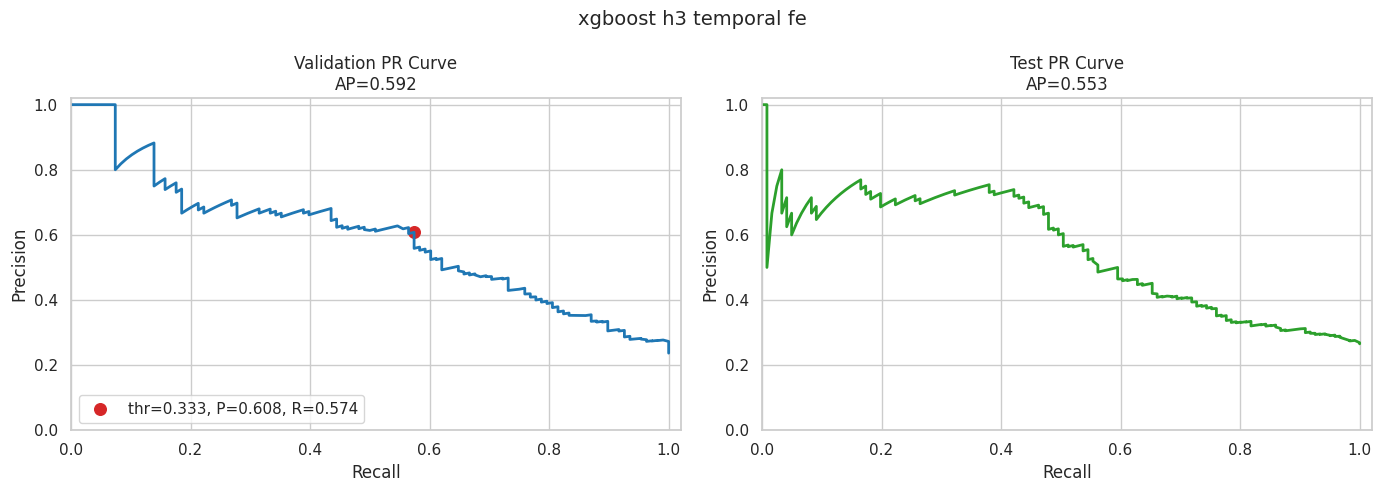

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_temporal_fe,XGBoost,3,temporal_fe,183,1368,456,456,0,0.332983,0.607843,0.574074,0.590476,0.591855,0.795684,0.5625,0.520661,0.540773,0.553459,0.735883,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.332983,0.607843,0.574074,0.590476,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,575,0.018136,3,10,0.882743,0.891603,3.856352,4.638760e-08,0.000017,1.222002


#### Classification report on test

,precision,recall,f1-score,support
0,0.831395,0.853731,0.842415,335.000000
1,0.562500,0.520661,0.540773,121.000000
accuracy,0.765351,0.765351,0.765351,0.765351
macro avg,0.696948,0.687196,0.691594,456.000000
weighted avg,0.760044,0.765351,0.762374,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,286,49
Actual 1,58,63


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_temporal_fe,XGBoost,3,temporal_fe,183,1368,456,456,0,0.332983,0.607843,0.574074,0.590476,0.591855,0.795684,0.5625,0.520661,0.540773,0.553459,0.735883,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=3,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 3 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

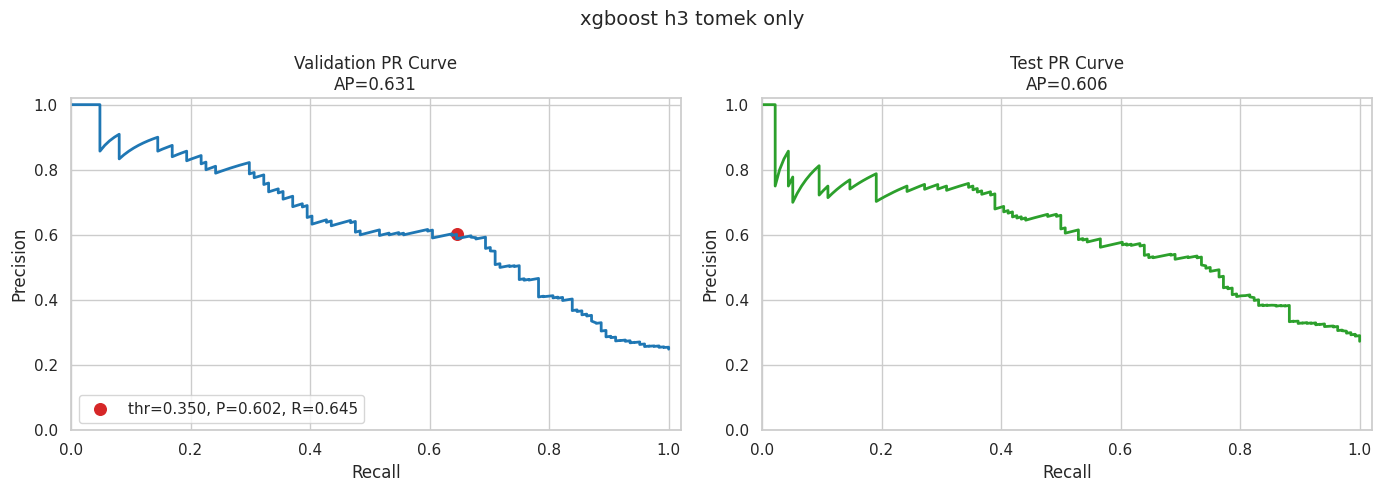

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_only,XGBoost,3,tomek_only,14,1494,498,498,101,0.349937,0.601504,0.645161,0.622568,0.630606,0.792953,0.574627,0.566176,0.57037,0.605777,0.785658,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.349937,0.601504,0.645161,0.622568,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,215,0.084714,9,7,0.908387,0.797518,2.613664,0.00007,1.693449e-08,1.193272


#### Classification report on test

,precision,recall,f1-score,support
0,0.837912,0.842541,0.840220,362.000000
1,0.574627,0.566176,0.570370,136.000000
accuracy,0.767068,0.767068,0.767068,0.767068
macro avg,0.706269,0.704359,0.705295,498.000000
weighted avg,0.766011,0.767068,0.766526,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,305,57
Actual 1,59,77


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_only,XGBoost,3,tomek_only,14,1494,498,498,101,0.349937,0.601504,0.645161,0.622568,0.630606,0.792953,0.574627,0.566176,0.57037,0.605777,0.785658,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=3,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 3 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

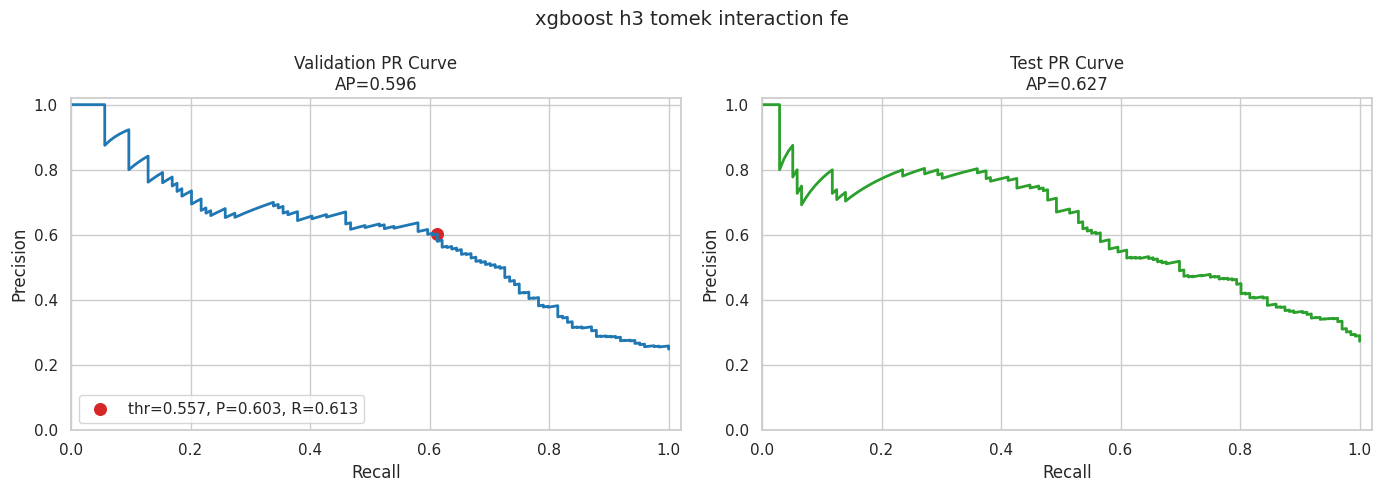

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_interaction_fe,XGBoost,3,tomek_interaction_fe,16,1494,498,498,95,0.557443,0.603175,0.612903,0.608,0.596034,0.774215,0.621849,0.544118,0.580392,0.626666,0.796311,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.557443,0.603175,0.612903,0.608,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,605,0.033224,10,12,0.797778,0.838941,0.104104,0.000004,0.053493,2.703085


#### Classification report on test

,precision,recall,f1-score,support
0,0.836412,0.875691,0.855601,362.000000
1,0.621849,0.544118,0.580392,136.000000
accuracy,0.785141,0.785141,0.785141,0.785141
macro avg,0.729130,0.709904,0.717996,498.000000
weighted avg,0.777816,0.785141,0.780443,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,317,45
Actual 1,62,74


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_interaction_fe,XGBoost,3,tomek_interaction_fe,16,1494,498,498,95,0.557443,0.603175,0.612903,0.608,0.596034,0.774215,0.621849,0.544118,0.580392,0.626666,0.796311,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=3,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 3 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

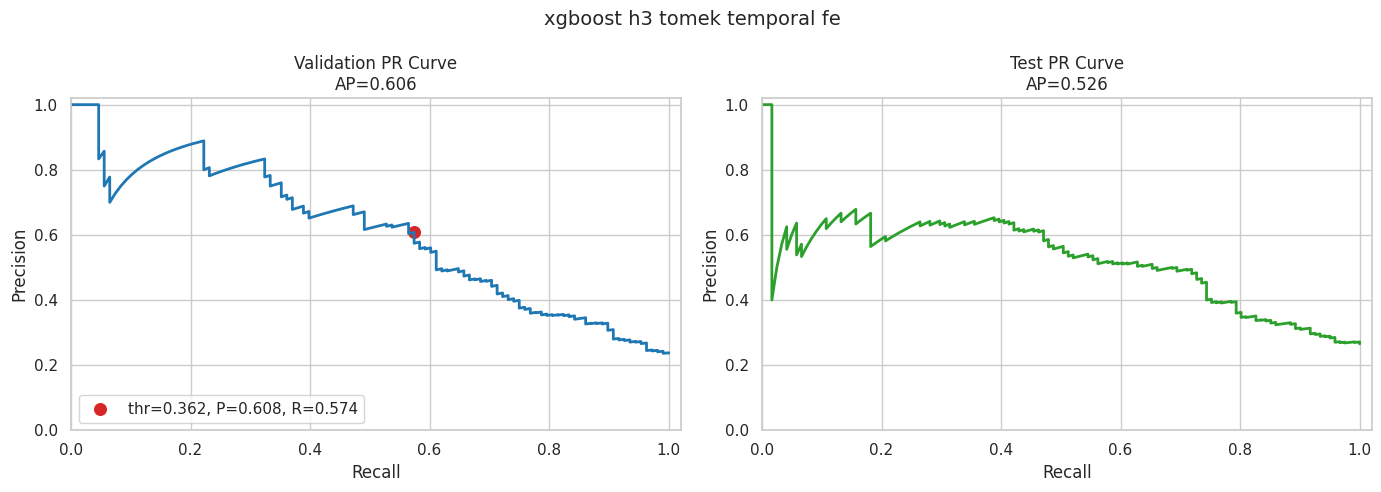

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_temporal_fe,XGBoost,3,tomek_temporal_fe,183,1368,456,456,74,0.361831,0.607843,0.574074,0.590476,0.606432,0.783073,0.54386,0.512397,0.52766,0.526101,0.746713,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.361831,0.607843,0.574074,0.590476,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,215,0.084714,9,7,0.908387,0.797518,2.613664,0.00007,1.693449e-08,1.195396


#### Classification report on test

,precision,recall,f1-score,support
0,0.827485,0.844776,0.836041,335.000000
1,0.543860,0.512397,0.527660,121.000000
accuracy,0.756579,0.756579,0.756579,0.756579
macro avg,0.685673,0.678586,0.681850,456.000000
weighted avg,0.752225,0.756579,0.754212,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,283,52
Actual 1,59,62


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_temporal_fe,XGBoost,3,tomek_temporal_fe,183,1368,456,456,74,0.361831,0.607843,0.574074,0.590476,0.606432,0.783073,0.54386,0.512397,0.52766,0.526101,0.746713,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=3,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## XGBoost | Horizon 3 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

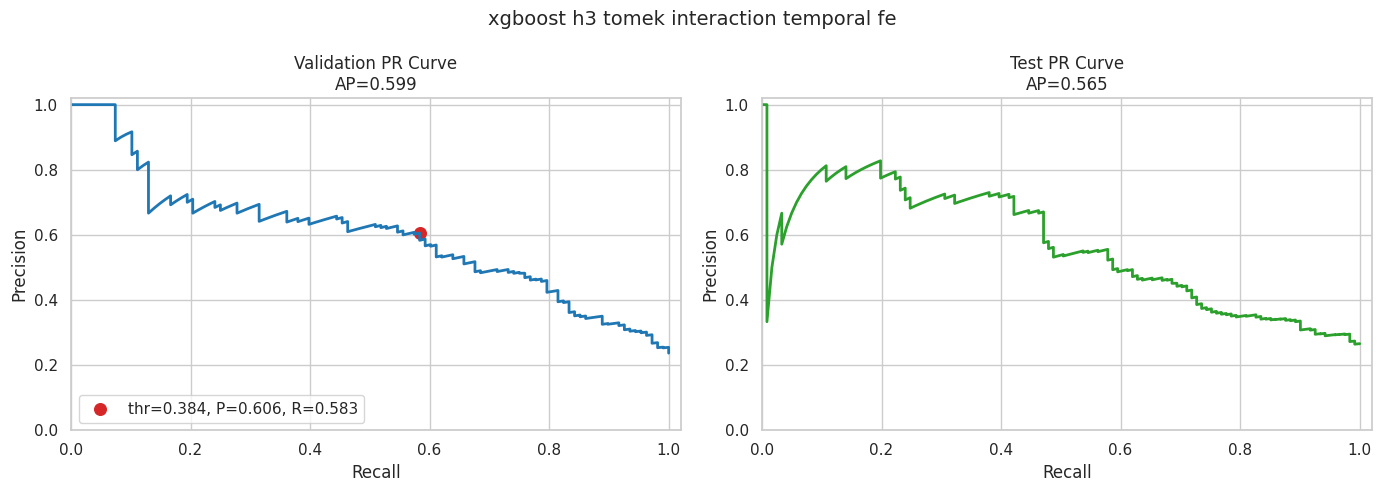

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_interaction_temporal_fe,XGBoost,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.384376,0.605769,0.583333,0.59434,0.598926,0.808442,0.543103,0.520661,0.531646,0.5653,0.750228,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.384376,0.605769,0.583333,0.59434,True,False


#### Best hyperparameters

,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,504,0.028202,3,10,0.875292,0.874202,4.31728,0.000005,0.000002,1.466003


#### Classification report on test

,precision,recall,f1-score,support
0,0.829412,0.841791,0.835556,335.000000
1,0.543103,0.520661,0.531646,121.000000
accuracy,0.756579,0.756579,0.756579,0.756579
macro avg,0.686258,0.681226,0.683601,456.000000
weighted avg,0.753440,0.756579,0.754913,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,282,53
Actual 1,58,63


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,xgboost_h3_tomek_interaction_temporal_fe,XGBoost,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.384376,0.605769,0.583333,0.59434,0.598926,0.808442,0.543103,0.520661,0.531646,0.5653,0.750228,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="XGBoost",
    horizon=3,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 2 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

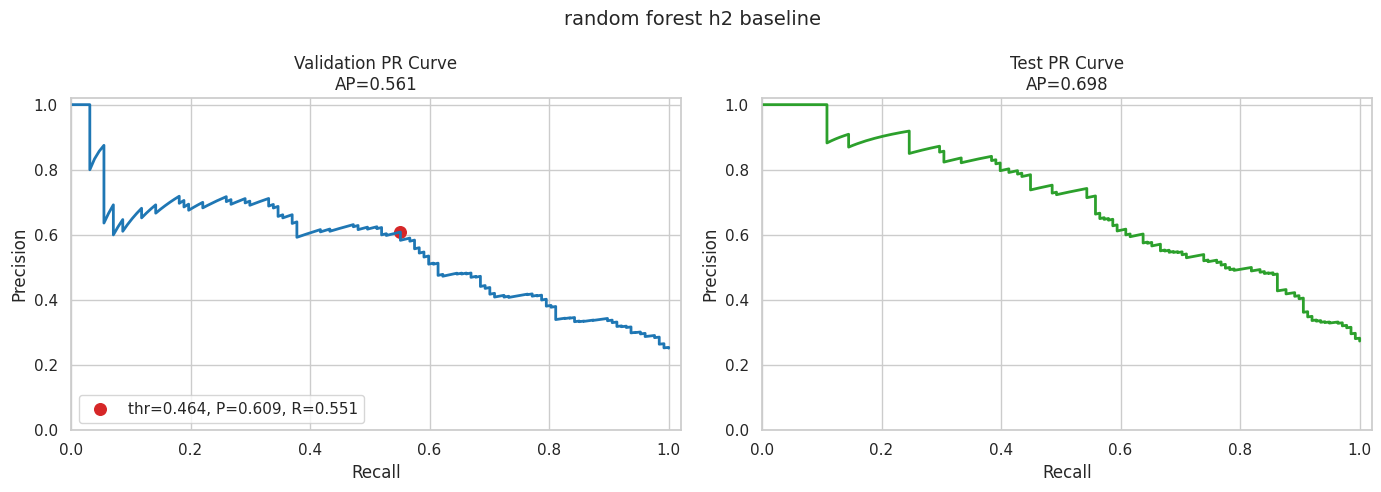

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_baseline,Random Forest,2,baseline,14,1512,504,504,0,0.46407,0.608696,0.551181,0.578512,0.561183,0.773721,0.6875,0.557971,0.616,0.697863,0.825711,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.46407,0.608696,0.551181,0.578512,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,799,10,8,4,0.8,balanced_subsample


#### Classification report on test

,precision,recall,f1-score,support
0,0.844388,0.904372,0.873351,366.000000
1,0.687500,0.557971,0.616000,138.000000
accuracy,0.809524,0.809524,0.809524,0.809524
macro avg,0.765944,0.731171,0.744675,504.000000
weighted avg,0.801430,0.809524,0.802886,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,331,35
Actual 1,61,77


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_baseline,Random Forest,2,baseline,14,1512,504,504,0,0.46407,0.608696,0.551181,0.578512,0.561183,0.773721,0.6875,0.557971,0.616,0.697863,0.825711,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=2,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 2 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

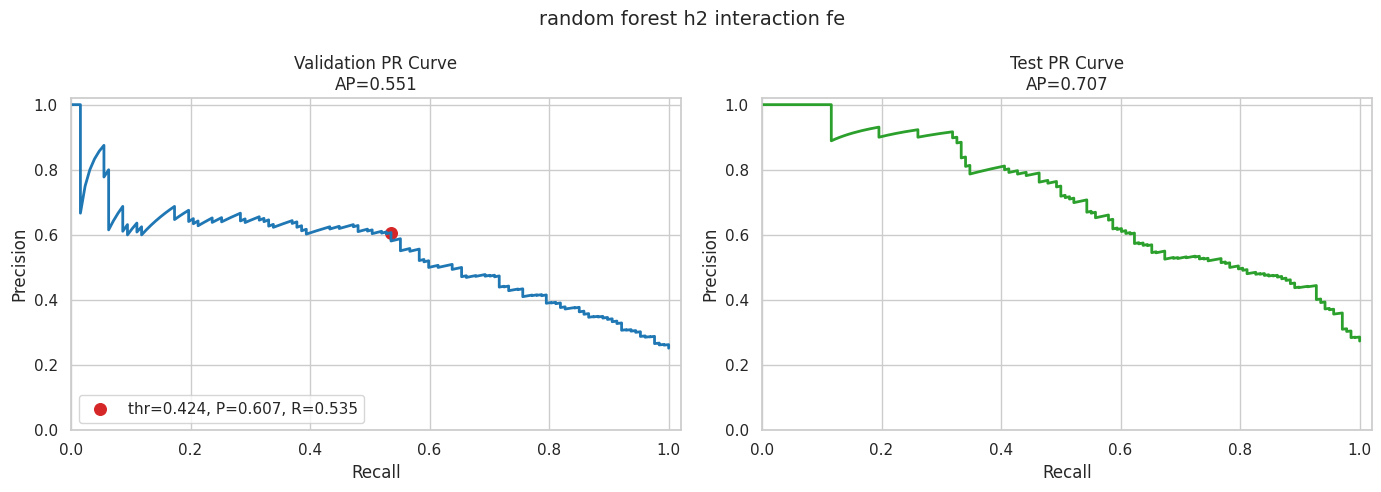

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_interaction_fe,Random Forest,2,interaction_fe,16,1512,504,504,0,0.424163,0.607143,0.535433,0.569038,0.550857,0.778922,0.71875,0.5,0.589744,0.707154,0.836363,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.424163,0.607143,0.535433,0.569038,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,896,14,10,5,0.8,None


#### Classification report on test

,precision,recall,f1-score,support
0,0.830882,0.926230,0.875969,366.000000
1,0.718750,0.500000,0.589744,138.000000
accuracy,0.809524,0.809524,0.809524,0.809524
macro avg,0.774816,0.713115,0.732856,504.000000
weighted avg,0.800179,0.809524,0.797598,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,339,27
Actual 1,69,69


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_interaction_fe,Random Forest,2,interaction_fe,16,1512,504,504,0,0.424163,0.607143,0.535433,0.569038,0.550857,0.778922,0.71875,0.5,0.589744,0.707154,0.836363,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=2,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 2 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

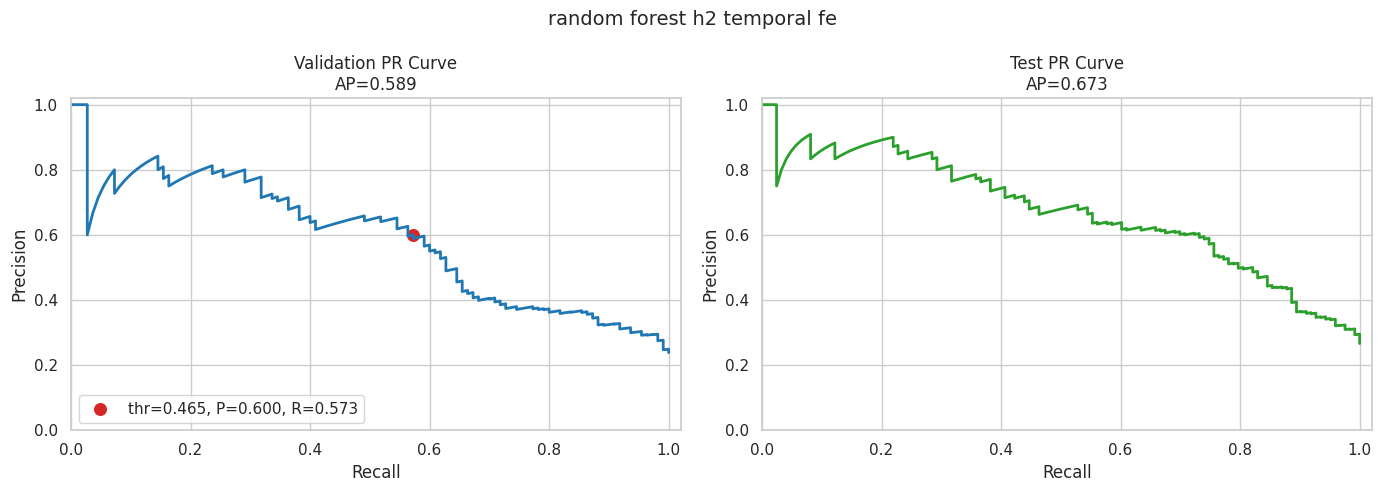

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_temporal_fe,Random Forest,2,temporal_fe,183,1386,462,462,0,0.465037,0.6,0.572727,0.586047,0.58941,0.791503,0.653846,0.552846,0.599119,0.672851,0.832794,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.465037,0.6,0.572727,0.586047,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,396,18,10,10,0.5,balanced


#### Classification report on test

,precision,recall,f1-score,support
0,0.846369,0.893805,0.869440,339.00000
1,0.653846,0.552846,0.599119,123.00000
accuracy,0.803030,0.803030,0.803030,0.80303
macro avg,0.750107,0.723325,0.734280,462.00000
weighted avg,0.795113,0.803030,0.797472,462.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,303,36
Actual 1,55,68


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_temporal_fe,Random Forest,2,temporal_fe,183,1386,462,462,0,0.465037,0.6,0.572727,0.586047,0.58941,0.791503,0.653846,0.552846,0.599119,0.672851,0.832794,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=2,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 2 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

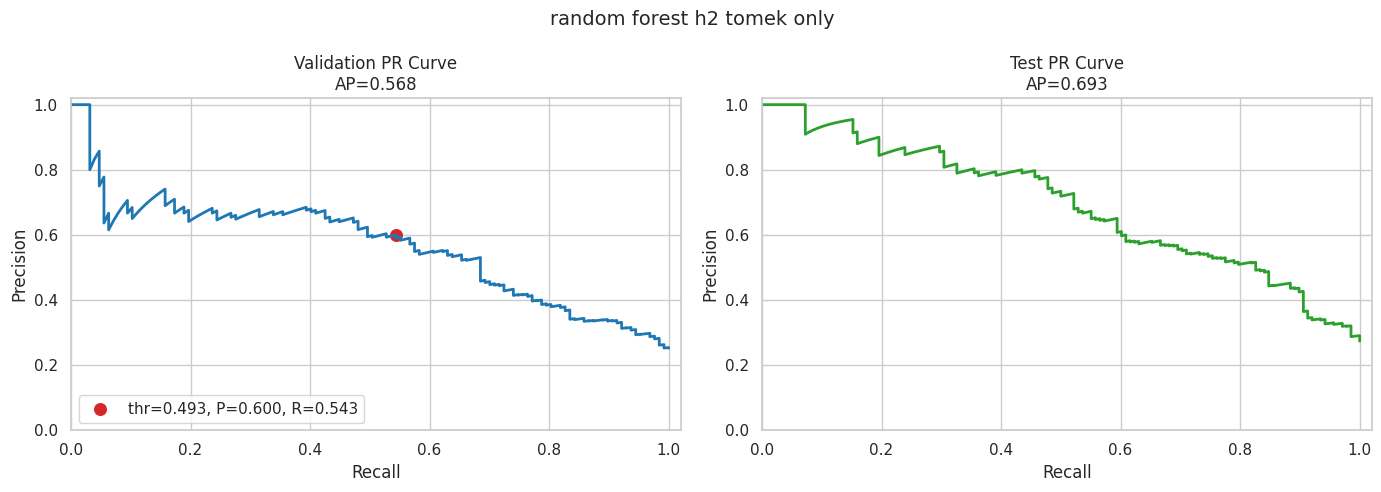

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_only,Random Forest,2,tomek_only,14,1512,504,504,88,0.492881,0.6,0.543307,0.570248,0.567848,0.781115,0.66087,0.550725,0.600791,0.692957,0.827314,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.492881,0.6,0.543307,0.570248,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,978,14,3,4,0.8,balanced


#### Classification report on test

,precision,recall,f1-score,support
0,0.840617,0.893443,0.866225,366.000000
1,0.660870,0.550725,0.600791,138.000000
accuracy,0.799603,0.799603,0.799603,0.799603
macro avg,0.750743,0.722084,0.733508,504.000000
weighted avg,0.791400,0.799603,0.793547,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,327,39
Actual 1,62,76


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_only,Random Forest,2,tomek_only,14,1512,504,504,88,0.492881,0.6,0.543307,0.570248,0.567848,0.781115,0.66087,0.550725,0.600791,0.692957,0.827314,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=2,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 2 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

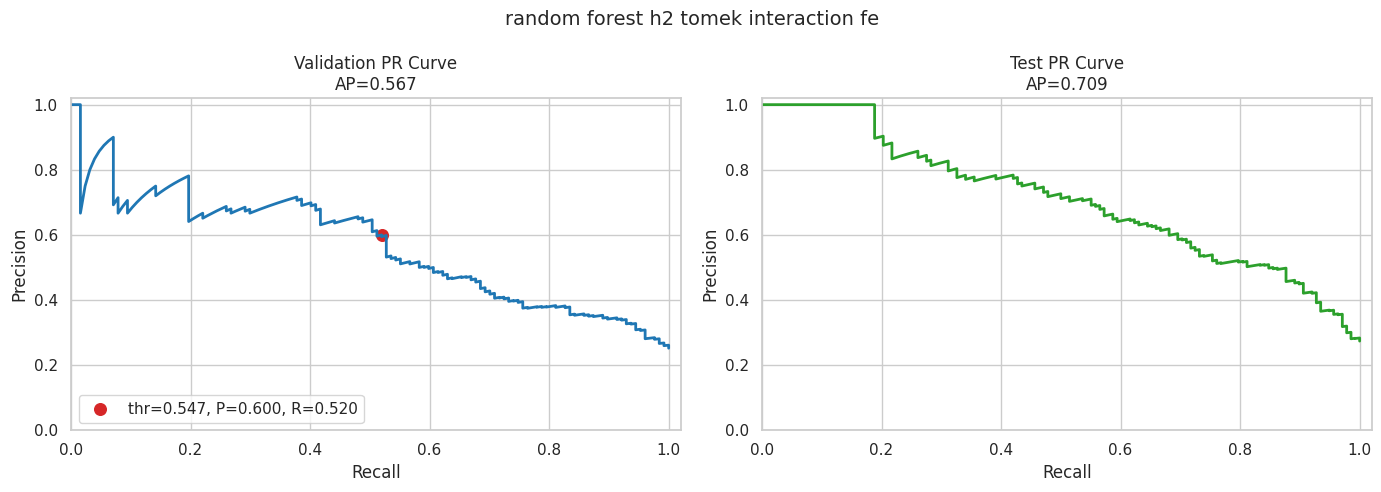

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_interaction_fe,Random Forest,2,tomek_interaction_fe,16,1512,504,504,82,0.547018,0.6,0.519685,0.556962,0.566561,0.775768,0.704762,0.536232,0.609053,0.709033,0.841827,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.547018,0.6,0.519685,0.556962,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,592,None,14,7,0.5,balanced_subsample


#### Classification report on test

,precision,recall,f1-score,support
0,0.839599,0.915301,0.875817,366.000000
1,0.704762,0.536232,0.609053,138.000000
accuracy,0.811508,0.811508,0.811508,0.811508
macro avg,0.772180,0.725766,0.742435,504.000000
weighted avg,0.802679,0.811508,0.802775,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,335,31
Actual 1,64,74


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_interaction_fe,Random Forest,2,tomek_interaction_fe,16,1512,504,504,82,0.547018,0.6,0.519685,0.556962,0.566561,0.775768,0.704762,0.536232,0.609053,0.709033,0.841827,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=2,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 2 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

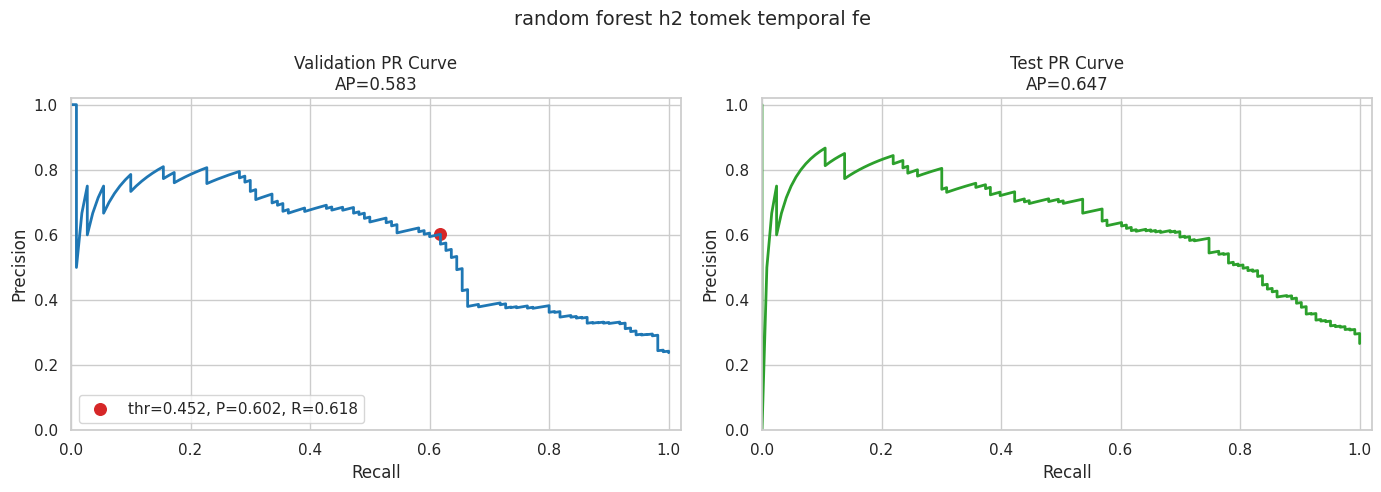

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_temporal_fe,Random Forest,2,tomek_temporal_fe,183,1386,462,462,77,0.451982,0.60177,0.618182,0.609865,0.583352,0.789799,0.628319,0.577236,0.601695,0.647005,0.829628,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.451982,0.60177,0.618182,0.609865,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,763,18,14,8,0.5,balanced


#### Classification report on test

,precision,recall,f1-score,support
0,0.851003,0.876106,0.863372,339.000000
1,0.628319,0.577236,0.601695,123.000000
accuracy,0.796537,0.796537,0.796537,0.796537
macro avg,0.739661,0.726671,0.732534,462.000000
weighted avg,0.791717,0.796537,0.793705,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,297,42
Actual 1,52,71


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_temporal_fe,Random Forest,2,tomek_temporal_fe,183,1386,462,462,77,0.451982,0.60177,0.618182,0.609865,0.583352,0.789799,0.628319,0.577236,0.601695,0.647005,0.829628,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=2,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 2 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

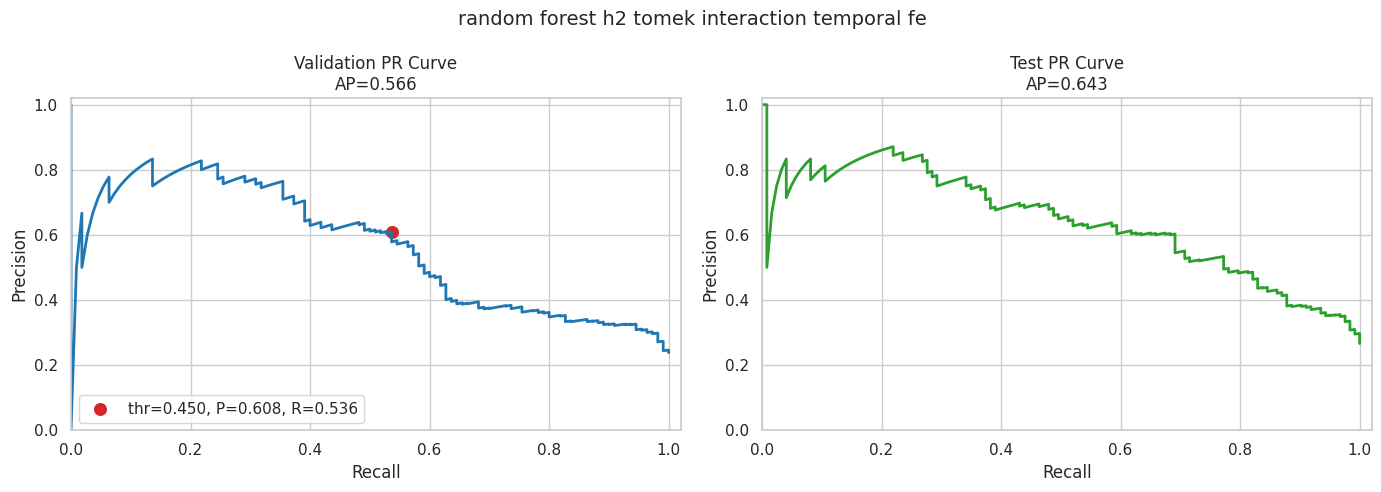

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_interaction_temporal_fe,Random Forest,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.450283,0.608247,0.536364,0.570048,0.565718,0.780294,0.646465,0.520325,0.576577,0.642645,0.826007,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.450283,0.608247,0.536364,0.570048,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,592,None,14,7,0.5,balanced_subsample


#### Classification report on test

,precision,recall,f1-score,support
0,0.837466,0.896755,0.866097,339.000000
1,0.646465,0.520325,0.576577,123.000000
accuracy,0.796537,0.796537,0.796537,0.796537
macro avg,0.741965,0.708540,0.721337,462.000000
weighted avg,0.786615,0.796537,0.789017,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,304,35
Actual 1,59,64


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h2_tomek_interaction_temporal_fe,Random Forest,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.450283,0.608247,0.536364,0.570048,0.565718,0.780294,0.646465,0.520325,0.576577,0.642645,0.826007,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=2,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 3 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

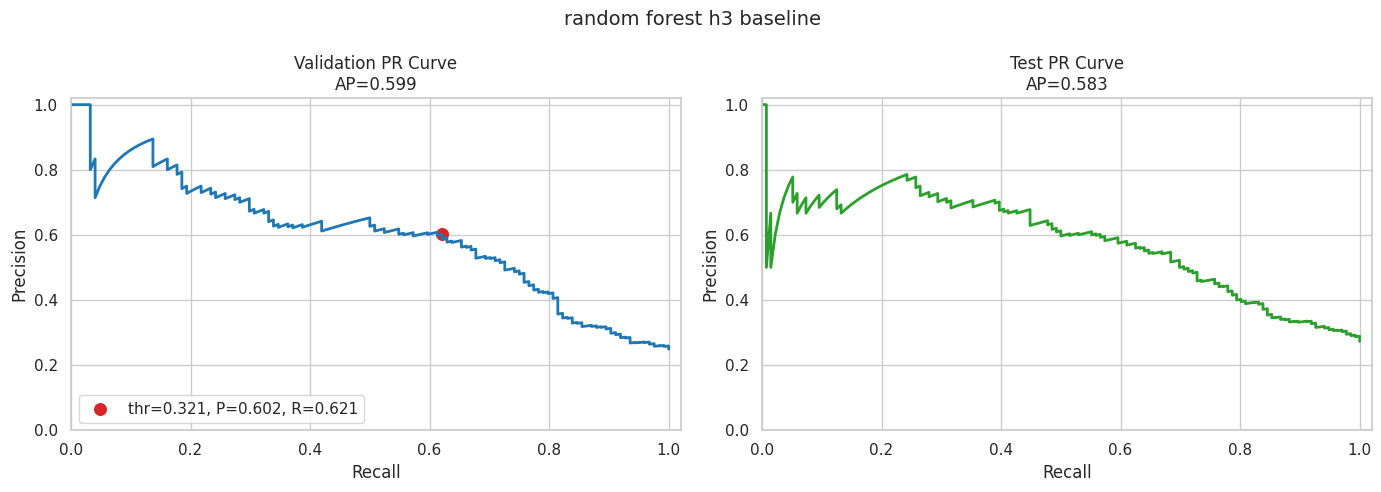

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_baseline,Random Forest,3,baseline,14,1494,498,498,0,0.320752,0.601562,0.620968,0.611111,0.599048,0.785255,0.592308,0.566176,0.578947,0.583207,0.775349,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.320752,0.601562,0.620968,0.611111,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,718,8,11,9,0.5,None


#### Classification report on test

,precision,recall,f1-score,support
0,0.839674,0.853591,0.846575,362.0000
1,0.592308,0.566176,0.578947,136.0000
accuracy,0.775100,0.775100,0.775100,0.7751
macro avg,0.715991,0.709884,0.712761,498.0000
weighted avg,0.772120,0.775100,0.773488,498.0000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,309,53
Actual 1,59,77


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_baseline,Random Forest,3,baseline,14,1494,498,498,0,0.320752,0.601562,0.620968,0.611111,0.599048,0.785255,0.592308,0.566176,0.578947,0.583207,0.775349,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=3,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 3 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

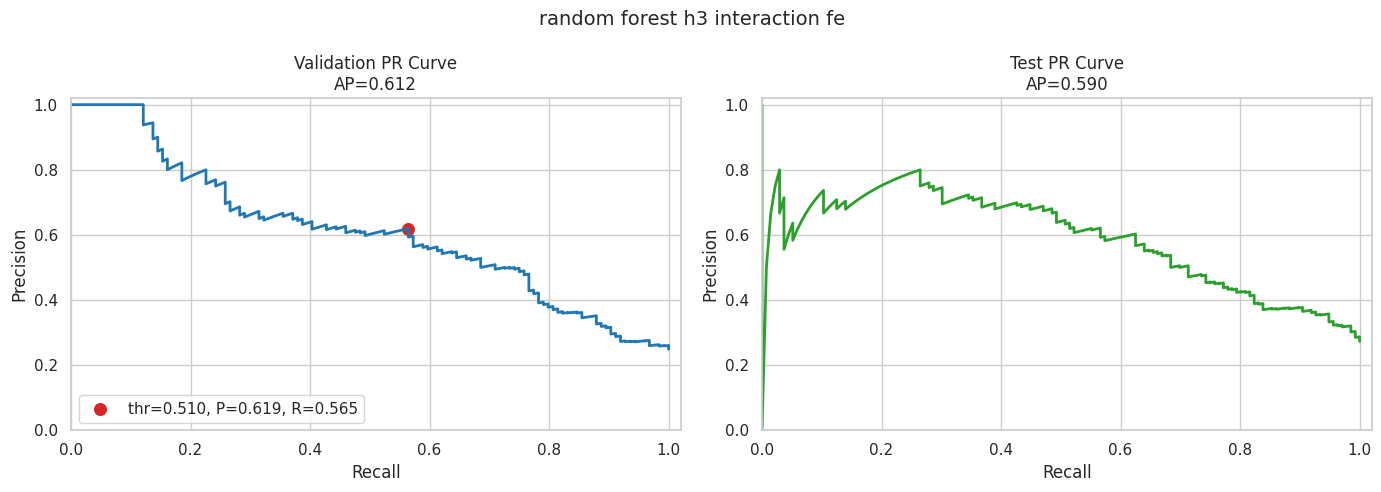

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_interaction_fe,Random Forest,3,interaction_fe,16,1494,498,498,0,0.51027,0.619469,0.564516,0.590717,0.612112,0.783746,0.630631,0.514706,0.566802,0.590141,0.792208,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.51027,0.619469,0.564516,0.590717,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,302,8,18,10,0.8,balanced


#### Classification report on test

,precision,recall,f1-score,support
0,0.829457,0.886740,0.857143,362.000000
1,0.630631,0.514706,0.566802,136.000000
accuracy,0.785141,0.785141,0.785141,0.785141
macro avg,0.730044,0.700723,0.711972,498.000000
weighted avg,0.775159,0.785141,0.777853,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,321,41
Actual 1,66,70


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_interaction_fe,Random Forest,3,interaction_fe,16,1494,498,498,0,0.51027,0.619469,0.564516,0.590717,0.612112,0.783746,0.630631,0.514706,0.566802,0.590141,0.792208,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=3,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 3 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

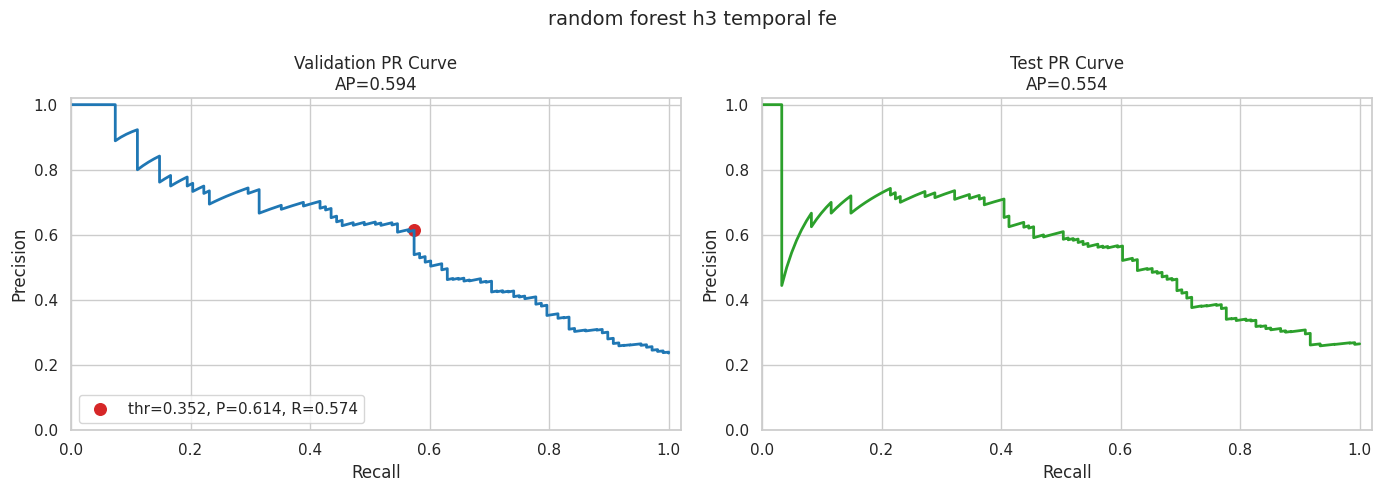

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_temporal_fe,Random Forest,3,temporal_fe,183,1368,456,456,0,0.352233,0.613861,0.574074,0.593301,0.59419,0.774319,0.575221,0.53719,0.555556,0.554479,0.7346,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.352233,0.613861,0.574074,0.593301,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,203,8,2,10,0.5,None


#### Classification report on test

,precision,recall,f1-score,support
0,0.836735,0.856716,0.846608,335.00000
1,0.575221,0.537190,0.555556,121.00000
accuracy,0.771930,0.771930,0.771930,0.77193
macro avg,0.705978,0.696953,0.701082,456.00000
weighted avg,0.767342,0.771930,0.769377,456.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,287,48
Actual 1,56,65


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_temporal_fe,Random Forest,3,temporal_fe,183,1368,456,456,0,0.352233,0.613861,0.574074,0.593301,0.59419,0.774319,0.575221,0.53719,0.555556,0.554479,0.7346,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=3,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 3 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

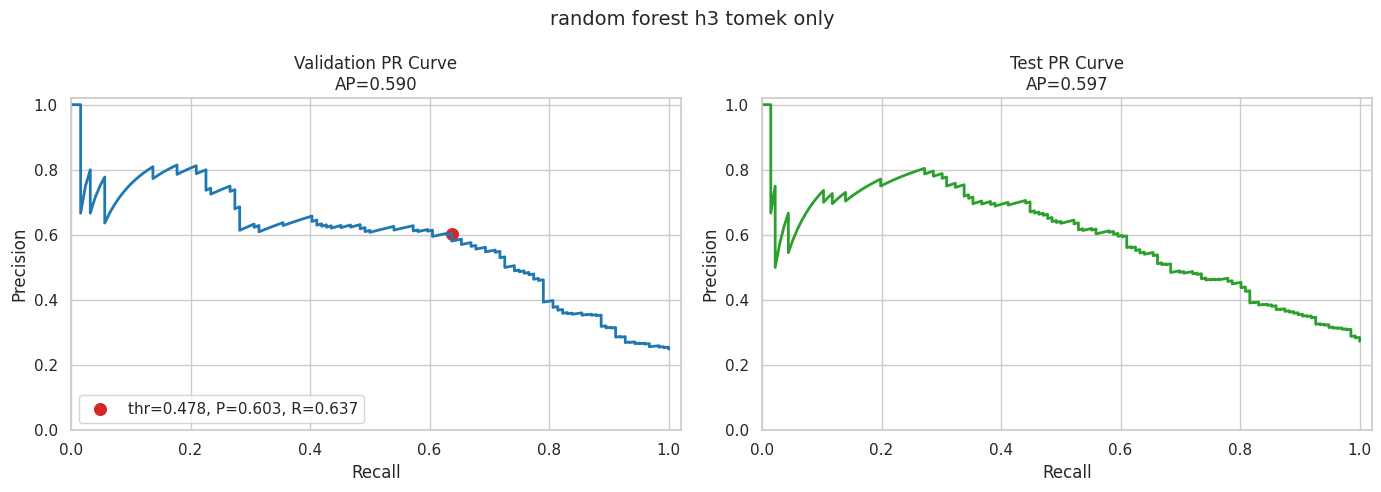

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_only,Random Forest,3,tomek_only,14,1494,498,498,101,0.477535,0.603053,0.637097,0.619608,0.589784,0.790129,0.604478,0.595588,0.6,0.597368,0.787699,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.477535,0.603053,0.637097,0.619608,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,807,10,2,10,0.5,balanced_subsample


#### Classification report on test

,precision,recall,f1-score,support
0,0.848901,0.853591,0.851240,362.000000
1,0.604478,0.595588,0.600000,136.000000
accuracy,0.783133,0.783133,0.783133,0.783133
macro avg,0.726689,0.724590,0.725620,498.000000
weighted avg,0.782151,0.783133,0.782628,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,309,53
Actual 1,55,81


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_only,Random Forest,3,tomek_only,14,1494,498,498,101,0.477535,0.603053,0.637097,0.619608,0.589784,0.790129,0.604478,0.595588,0.6,0.597368,0.787699,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=3,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 3 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

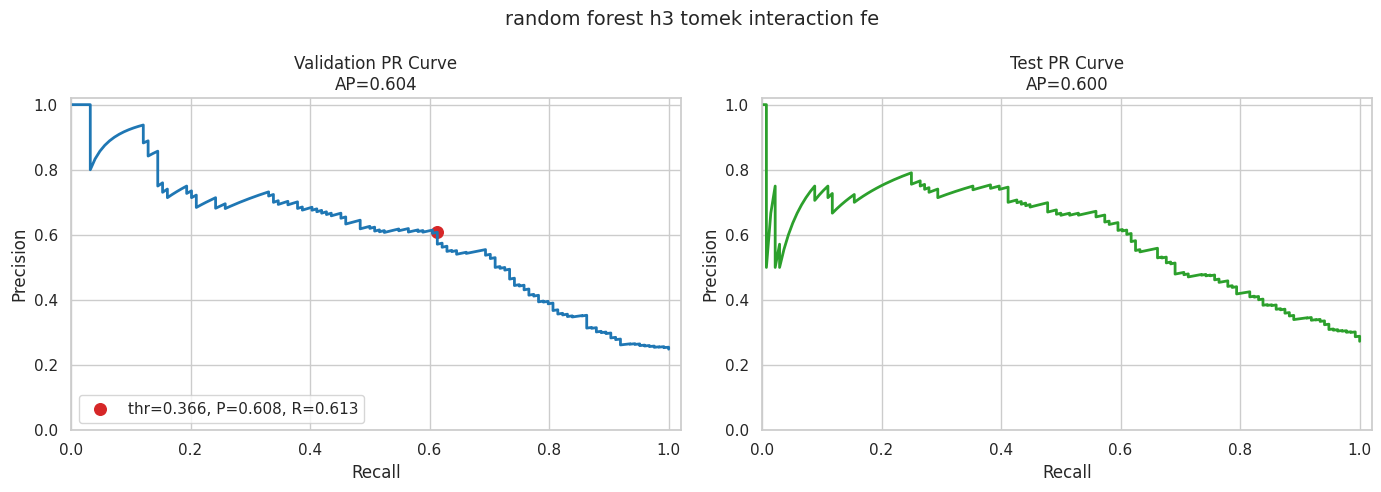

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_interaction_fe,Random Forest,3,tomek_interaction_fe,16,1494,498,498,95,0.36633,0.608,0.612903,0.610442,0.603659,0.779218,0.634921,0.588235,0.610687,0.600237,0.789933,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.36633,0.608,0.612903,0.610442,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,330,18,17,10,0.8,None


#### Classification report on test

,precision,recall,f1-score,support
0,0.849462,0.872928,0.861035,362.000000
1,0.634921,0.588235,0.610687,136.000000
accuracy,0.795181,0.795181,0.795181,0.795181
macro avg,0.742192,0.730582,0.735861,498.000000
weighted avg,0.790873,0.795181,0.792667,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,316,46
Actual 1,56,80


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_interaction_fe,Random Forest,3,tomek_interaction_fe,16,1494,498,498,95,0.36633,0.608,0.612903,0.610442,0.603659,0.779218,0.634921,0.588235,0.610687,0.600237,0.789933,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=3,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 3 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

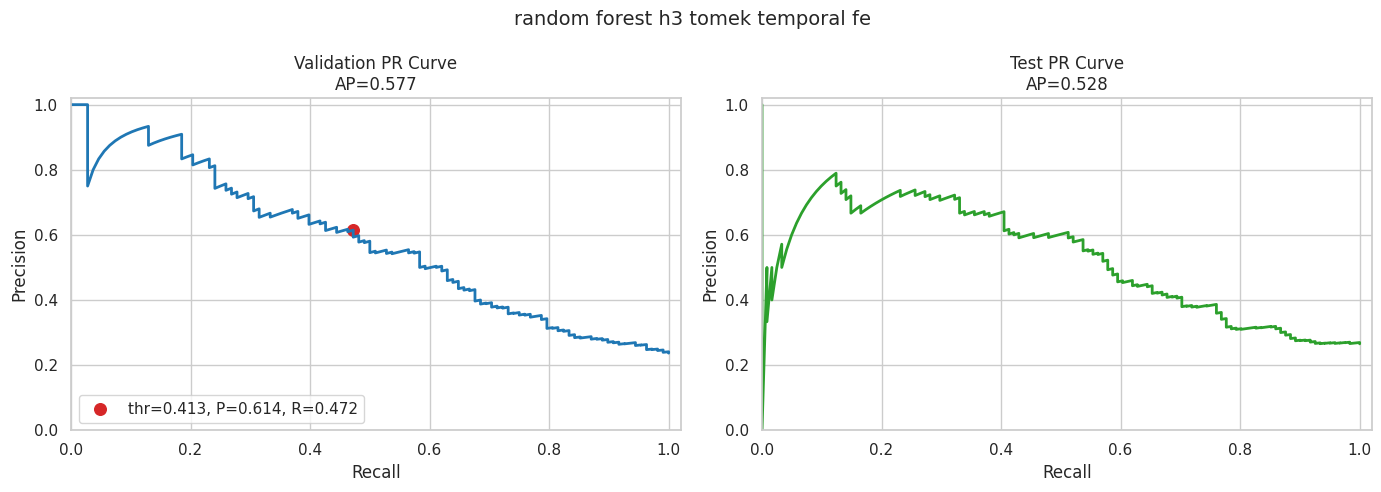

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_temporal_fe,Random Forest,3,tomek_temporal_fe,183,1368,456,456,74,0.412761,0.614458,0.472222,0.534031,0.576737,0.751623,0.597701,0.429752,0.5,0.528215,0.71738,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.412761,0.614458,0.472222,0.534031,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,890,8,18,6,0.8,None


#### Classification report on test

,precision,recall,f1-score,support
0,0.813008,0.895522,0.852273,335.00000
1,0.597701,0.429752,0.500000,121.00000
accuracy,0.771930,0.771930,0.771930,0.77193
macro avg,0.705355,0.662637,0.676136,456.00000
weighted avg,0.755876,0.771930,0.758797,456.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,300,35
Actual 1,69,52


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_temporal_fe,Random Forest,3,tomek_temporal_fe,183,1368,456,456,74,0.412761,0.614458,0.472222,0.534031,0.576737,0.751623,0.597701,0.429752,0.5,0.528215,0.71738,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=3,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## Random Forest | Horizon 3 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

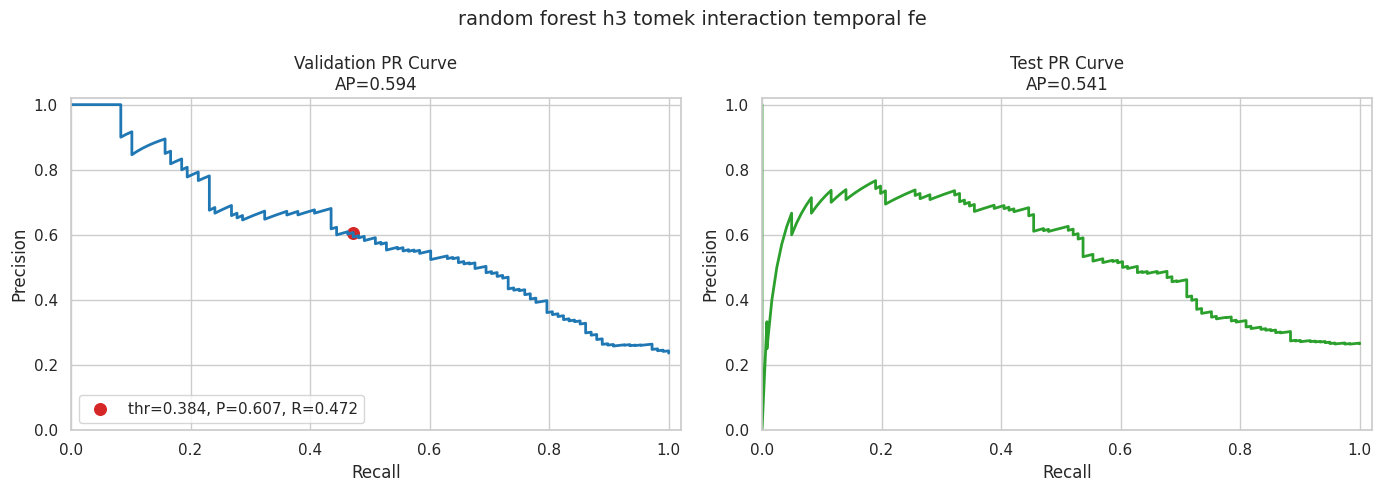

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_interaction_temporal_fe,Random Forest,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.383637,0.607143,0.472222,0.53125,0.593996,0.775862,0.62,0.512397,0.561086,0.540838,0.727717,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.383637,0.607143,0.472222,0.53125,True,False


#### Best hyperparameters

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,723,8,18,10,0.5,None


#### Classification report on test

,precision,recall,f1-score,support
0,0.834270,0.886567,0.859624,335.000000
1,0.620000,0.512397,0.561086,121.000000
accuracy,0.787281,0.787281,0.787281,0.787281
macro avg,0.727135,0.699482,0.710355,456.000000
weighted avg,0.777413,0.787281,0.780406,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,297,38
Actual 1,59,62


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,random_forest_h3_tomek_interaction_temporal_fe,Random Forest,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.383637,0.607143,0.472222,0.53125,0.593996,0.775862,0.62,0.512397,0.561086,0.540838,0.727717,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Random Forest",
    horizon=3,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 2 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

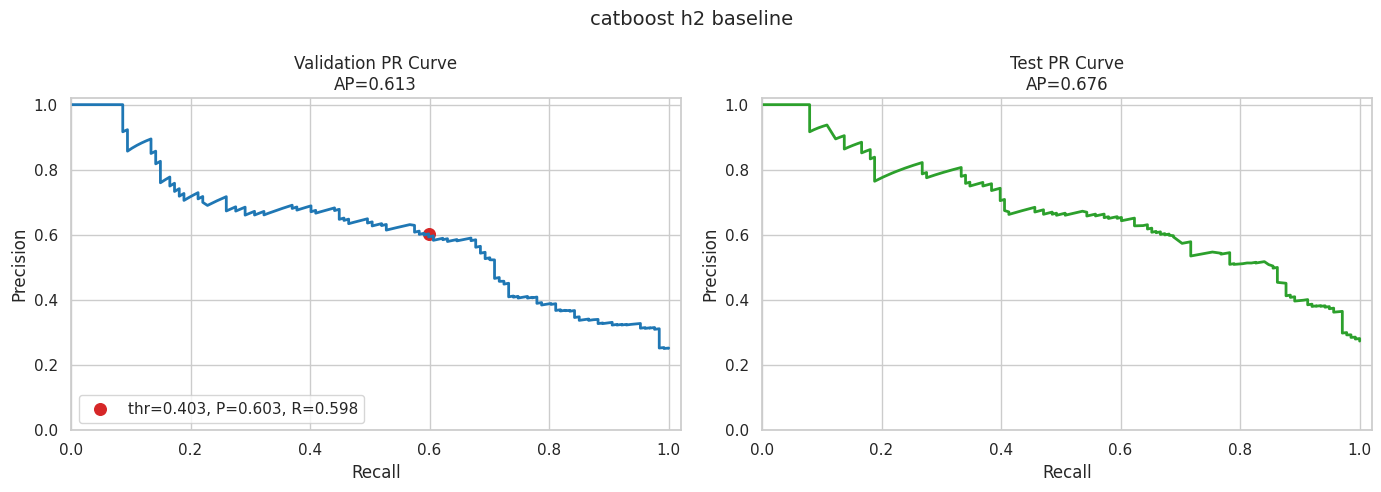

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_baseline,CatBoost,2,baseline,14,1512,504,504,0,0.403486,0.603175,0.598425,0.600791,0.612682,0.794022,0.643411,0.601449,0.621723,0.675931,0.831482,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.403486,0.603175,0.598425,0.600791,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,368,0.050823,4,16.241743,0.372753,4.934435,212,1.412938


#### Classification report on test

,precision,recall,f1-score,support
0,0.853333,0.874317,0.863698,366.000000
1,0.643411,0.601449,0.621723,138.000000
accuracy,0.799603,0.799603,0.799603,0.799603
macro avg,0.748372,0.737883,0.742710,504.000000
weighted avg,0.795855,0.799603,0.797443,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,320,46
Actual 1,55,83


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_baseline,CatBoost,2,baseline,14,1512,504,504,0,0.403486,0.603175,0.598425,0.600791,0.612682,0.794022,0.643411,0.601449,0.621723,0.675931,0.831482,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=2,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 2 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

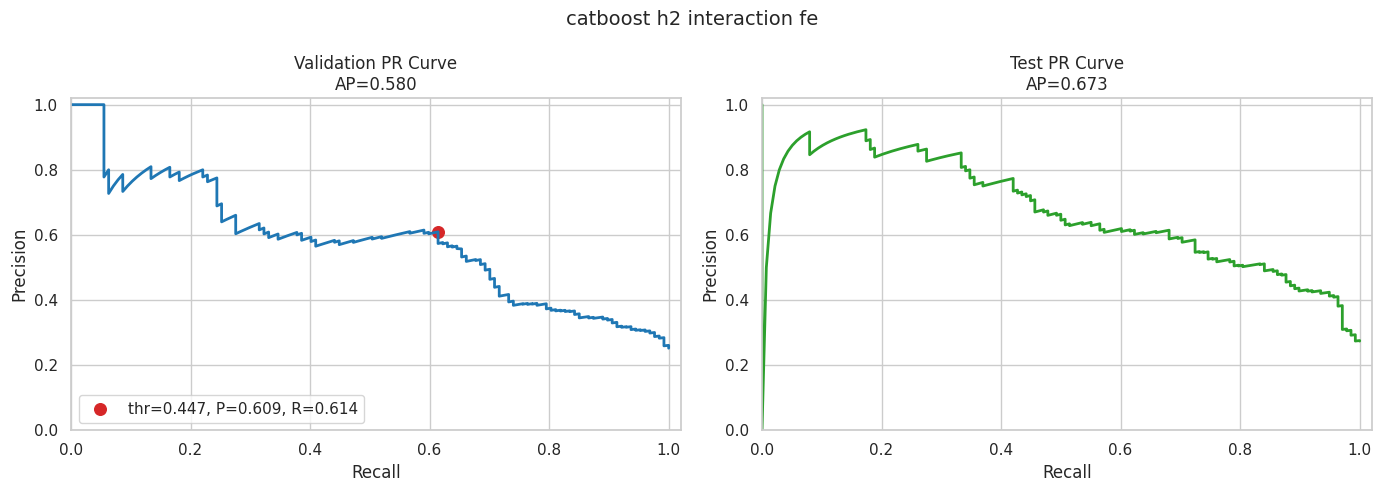

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_interaction_fe,CatBoost,2,interaction_fe,16,1512,504,504,0,0.446801,0.609375,0.614173,0.611765,0.580099,0.781898,0.607692,0.572464,0.589552,0.672583,0.839194,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.446801,0.609375,0.614173,0.611765,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,382,0.048164,7,6.533354,3.059264,0.697469,120,1.891361


#### Classification report on test

,precision,recall,f1-score,support
0,0.842246,0.860656,0.851351,366.000000
1,0.607692,0.572464,0.589552,138.000000
accuracy,0.781746,0.781746,0.781746,0.781746
macro avg,0.724969,0.716560,0.720452,504.000000
weighted avg,0.778023,0.781746,0.779668,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,315,51
Actual 1,59,79


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_interaction_fe,CatBoost,2,interaction_fe,16,1512,504,504,0,0.446801,0.609375,0.614173,0.611765,0.580099,0.781898,0.607692,0.572464,0.589552,0.672583,0.839194,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=2,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 2 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

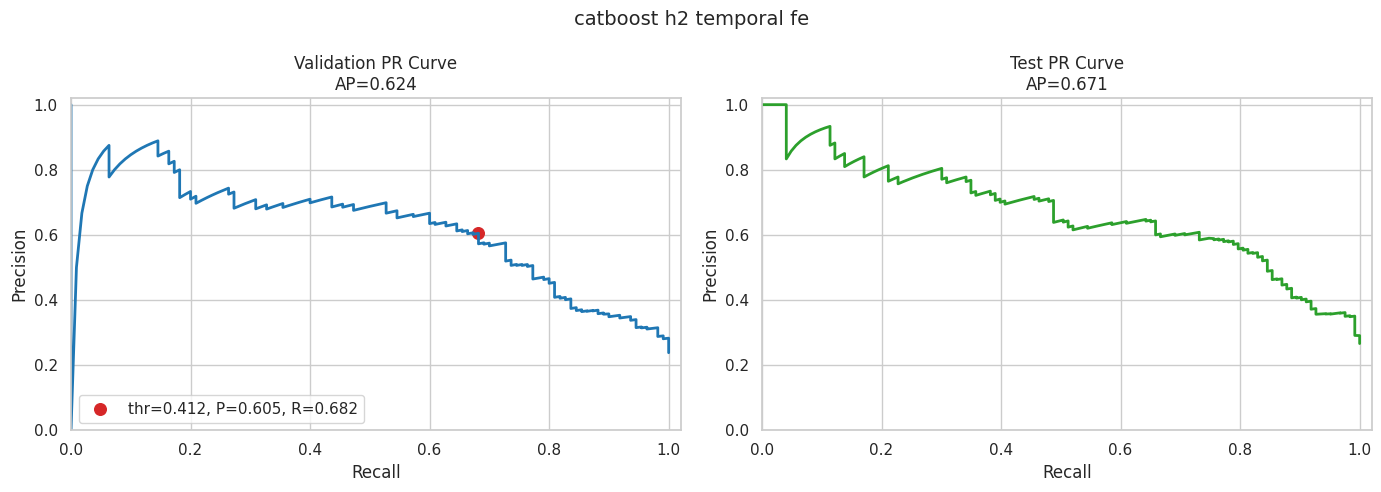

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_temporal_fe,CatBoost,2,temporal_fe,183,1386,462,462,0,0.411541,0.604839,0.681818,0.641026,0.623717,0.834827,0.602941,0.666667,0.633205,0.671366,0.844581,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.411541,0.604839,0.681818,0.641026,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,347,0.067092,5,13.2488,0.065702,3.573292,222,1.58343


#### Classification report on test

,precision,recall,f1-score,support
0,0.874233,0.840708,0.857143,339.000000
1,0.602941,0.666667,0.633205,123.000000
accuracy,0.794372,0.794372,0.794372,0.794372
macro avg,0.738587,0.753687,0.745174,462.000000
weighted avg,0.802006,0.794372,0.797523,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,285,54
Actual 1,41,82


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_temporal_fe,CatBoost,2,temporal_fe,183,1386,462,462,0,0.411541,0.604839,0.681818,0.641026,0.623717,0.834827,0.602941,0.666667,0.633205,0.671366,0.844581,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=2,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 2 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

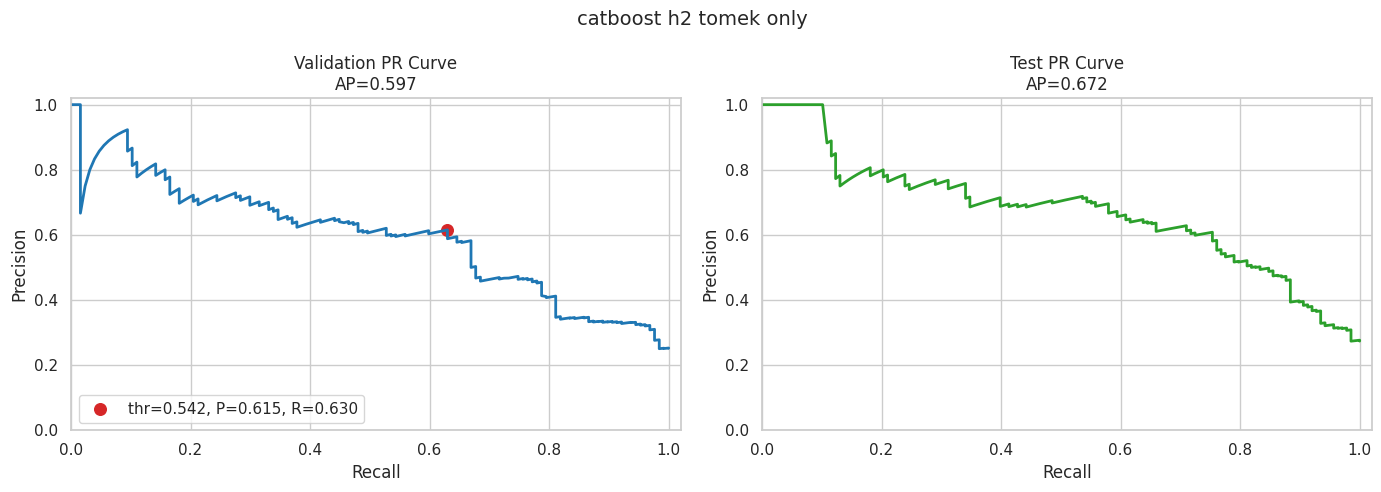

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_only,CatBoost,2,tomek_only,14,1512,504,504,88,0.541578,0.615385,0.629921,0.622568,0.596646,0.793459,0.640288,0.644928,0.642599,0.671855,0.829205,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.541578,0.615385,0.629921,0.622568,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,769,0.010205,6,1.326537,0.117574,4.977971,254,3.014603


#### Classification report on test

,precision,recall,f1-score,support
0,0.865753,0.863388,0.864569,366.000000
1,0.640288,0.644928,0.642599,138.000000
accuracy,0.803571,0.803571,0.803571,0.803571
macro avg,0.753021,0.754158,0.753584,504.000000
weighted avg,0.804019,0.803571,0.803792,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,316,50
Actual 1,49,89


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_only,CatBoost,2,tomek_only,14,1512,504,504,88,0.541578,0.615385,0.629921,0.622568,0.596646,0.793459,0.640288,0.644928,0.642599,0.671855,0.829205,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=2,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 2 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

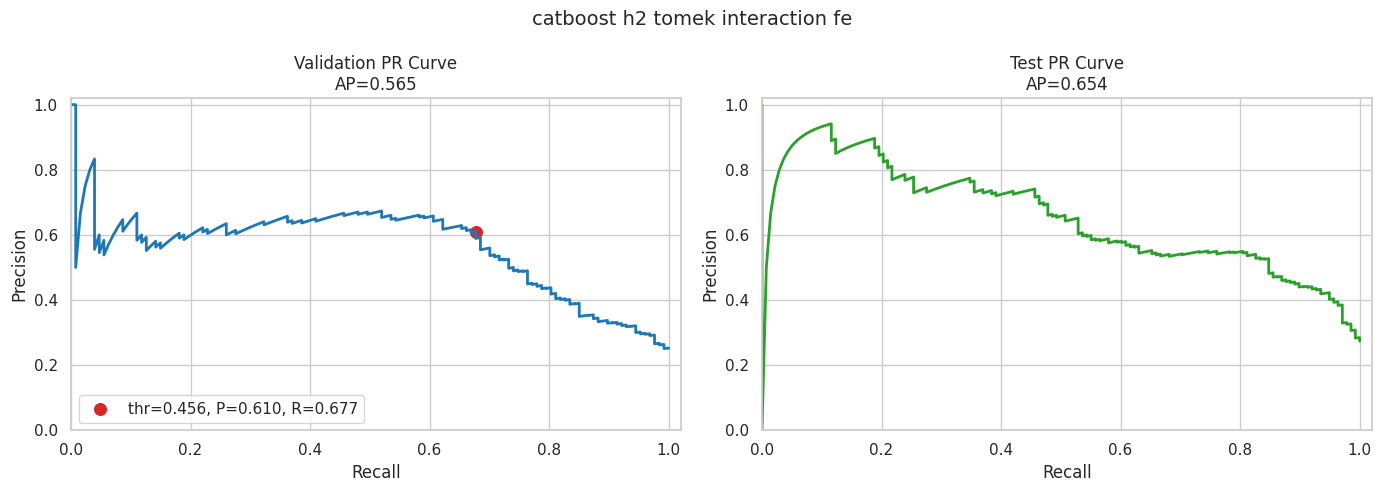

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_interaction_fe,CatBoost,2,tomek_interaction_fe,16,1512,504,504,82,0.455517,0.609929,0.677165,0.641791,0.564524,0.800643,0.575342,0.608696,0.591549,0.65448,0.835709,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.455517,0.609929,0.677165,0.641791,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,335,0.067768,8,9.453658,0.065702,3.806796,253,1.631689


#### Classification report on test

,precision,recall,f1-score,support
0,0.849162,0.830601,0.839779,366.000000
1,0.575342,0.608696,0.591549,138.000000
accuracy,0.769841,0.769841,0.769841,0.769841
macro avg,0.712252,0.719648,0.715664,504.000000
weighted avg,0.774188,0.769841,0.771811,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,304,62
Actual 1,54,84


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_interaction_fe,CatBoost,2,tomek_interaction_fe,16,1512,504,504,82,0.455517,0.609929,0.677165,0.641791,0.564524,0.800643,0.575342,0.608696,0.591549,0.65448,0.835709,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=2,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 2 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

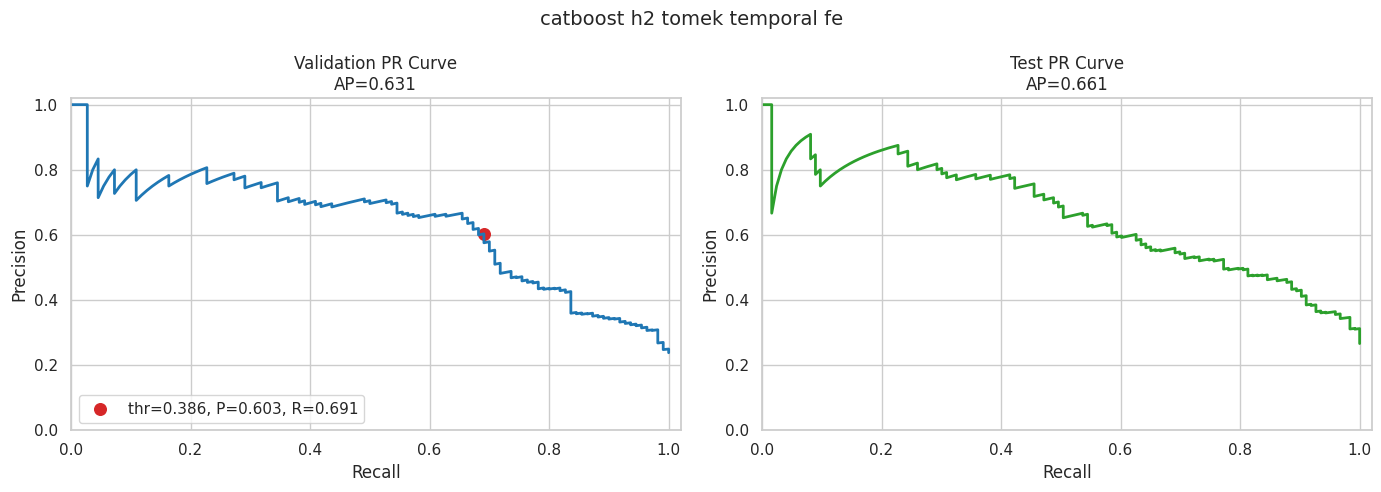

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_temporal_fe,CatBoost,2,tomek_temporal_fe,183,1386,462,462,77,0.385588,0.603175,0.690909,0.644068,0.63143,0.829468,0.610169,0.585366,0.59751,0.660764,0.834928,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.385588,0.603175,0.690909,0.644068,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,433,0.026869,7,7.37684,0.472543,3.930946,64,1.576391


#### Classification report on test

,precision,recall,f1-score,support
0,0.851744,0.864307,0.857980,339.000000
1,0.610169,0.585366,0.597510,123.000000
accuracy,0.790043,0.790043,0.790043,0.790043
macro avg,0.730957,0.724836,0.727745,462.000000
weighted avg,0.787429,0.790043,0.788634,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,293,46
Actual 1,51,72


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_temporal_fe,CatBoost,2,tomek_temporal_fe,183,1386,462,462,77,0.385588,0.603175,0.690909,0.644068,0.63143,0.829468,0.610169,0.585366,0.59751,0.660764,0.834928,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=2,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 2 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

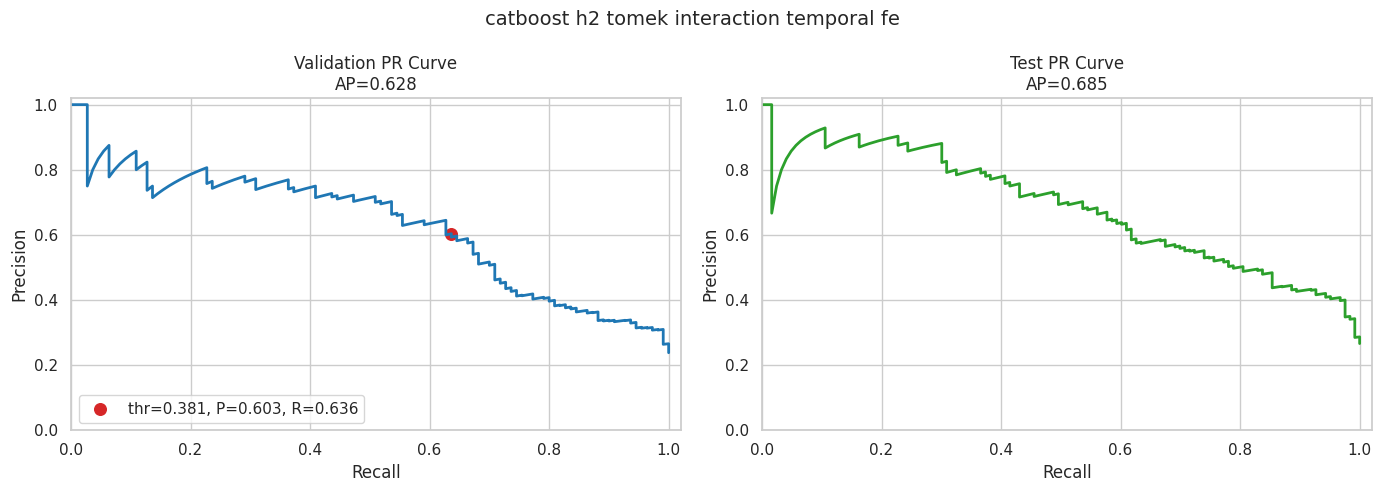

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_interaction_temporal_fe,CatBoost,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.380578,0.603448,0.636364,0.619469,0.628036,0.821978,0.646018,0.593496,0.618644,0.685021,0.847687,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.380578,0.603448,0.636364,0.619469,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,474,0.105084,5,10.770454,2.962073,0.232252,180,1.326499


#### Classification report on test

,precision,recall,f1-score,support
0,0.856734,0.882006,0.869186,339.000000
1,0.646018,0.593496,0.618644,123.000000
accuracy,0.805195,0.805195,0.805195,0.805195
macro avg,0.751376,0.737751,0.743915,462.000000
weighted avg,0.800634,0.805195,0.802483,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,299,40
Actual 1,50,73


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h2_tomek_interaction_temporal_fe,CatBoost,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.380578,0.603448,0.636364,0.619469,0.628036,0.821978,0.646018,0.593496,0.618644,0.685021,0.847687,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=2,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 3 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

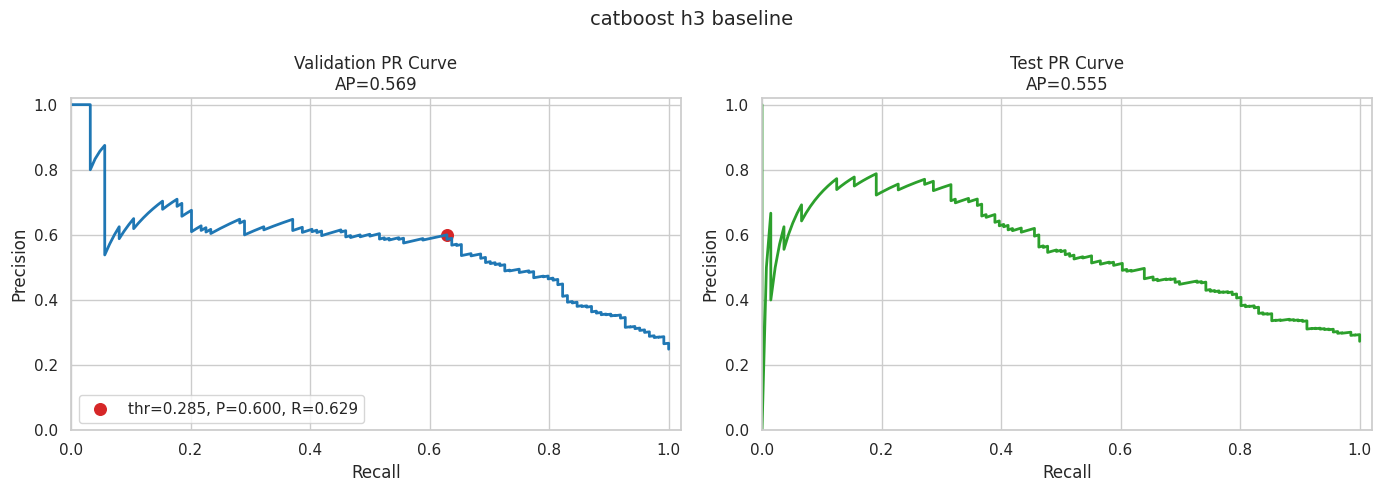

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_baseline,CatBoost,3,baseline,14,1494,498,498,0,0.285106,0.6,0.629032,0.614173,0.569009,0.805287,0.539062,0.507353,0.522727,0.555446,0.755403,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.285106,0.6,0.629032,0.614173,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,634,0.02807,7,13.708684,1.553447,2.798079,170,1.017573


#### Classification report on test

,precision,recall,f1-score,support
0,0.818919,0.837017,0.827869,362.000000
1,0.539062,0.507353,0.522727,136.000000
accuracy,0.746988,0.746988,0.746988,0.746988
macro avg,0.678991,0.672185,0.675298,498.000000
weighted avg,0.742492,0.746988,0.744537,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,303,59
Actual 1,67,69


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_baseline,CatBoost,3,baseline,14,1494,498,498,0,0.285106,0.6,0.629032,0.614173,0.569009,0.805287,0.539062,0.507353,0.522727,0.555446,0.755403,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=3,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 3 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

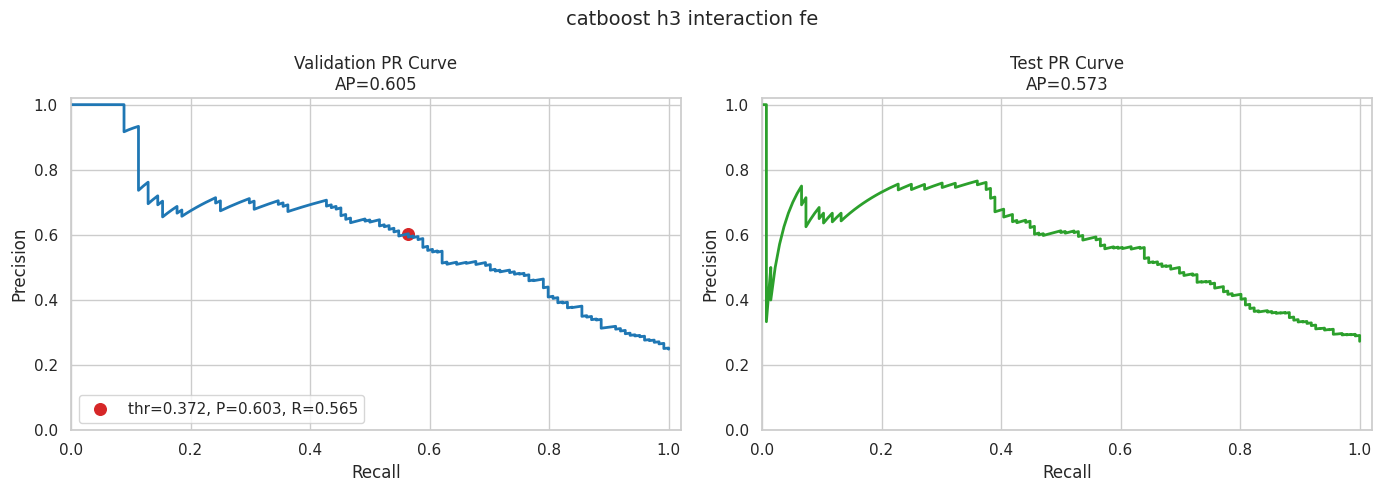

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_interaction_fe,CatBoost,3,interaction_fe,16,1494,498,498,0,0.371832,0.603448,0.564516,0.583333,0.604798,0.794075,0.612069,0.522059,0.563492,0.572546,0.770647,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.371832,0.603448,0.564516,0.583333,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,368,0.050823,4,16.241743,0.372753,4.934435,212,1.411302


#### Classification report on test

,precision,recall,f1-score,support
0,0.829843,0.875691,0.852151,362.000000
1,0.612069,0.522059,0.563492,136.000000
accuracy,0.779116,0.779116,0.779116,0.779116
macro avg,0.720956,0.698875,0.707821,498.000000
weighted avg,0.770371,0.779116,0.773320,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,317,45
Actual 1,65,71


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_interaction_fe,CatBoost,3,interaction_fe,16,1494,498,498,0,0.371832,0.603448,0.564516,0.583333,0.604798,0.794075,0.612069,0.522059,0.563492,0.572546,0.770647,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=3,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 3 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

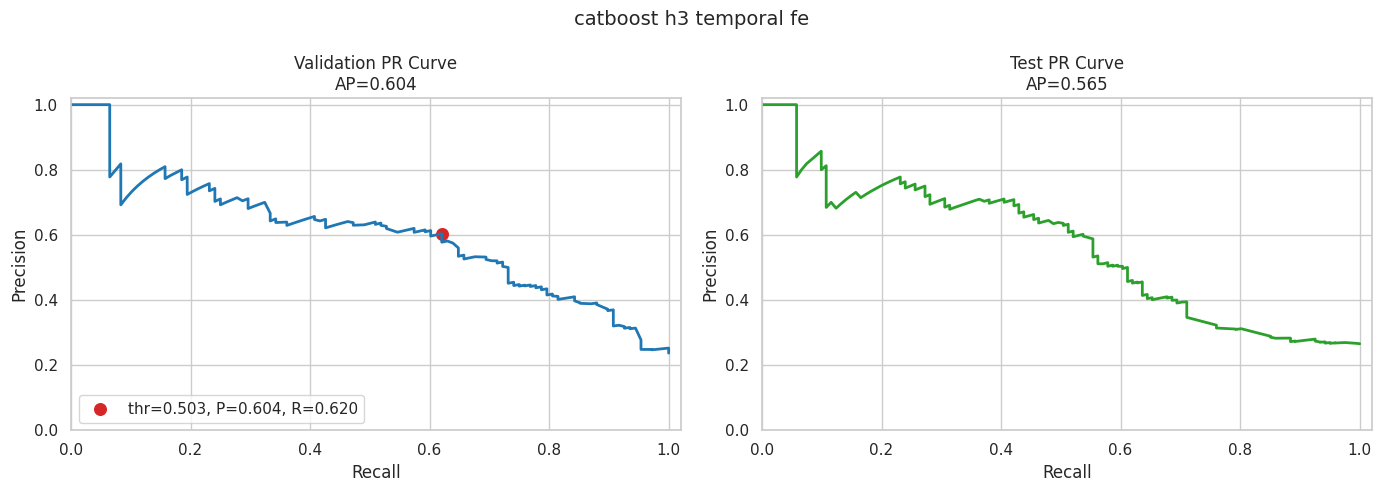

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_temporal_fe,CatBoost,3,temporal_fe,183,1368,456,456,0,0.503344,0.603604,0.62037,0.611872,0.604319,0.811888,0.59633,0.53719,0.565217,0.564748,0.710176,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.503344,0.603604,0.62037,0.611872,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,627,0.028339,5,13.405665,0.856019,2.282717,217,3.166137


#### Classification report on test

,precision,recall,f1-score,support
0,0.838617,0.868657,0.853372,335.000000
1,0.596330,0.537190,0.565217,121.000000
accuracy,0.780702,0.780702,0.780702,0.780702
macro avg,0.717473,0.702923,0.709295,456.000000
weighted avg,0.774326,0.780702,0.776910,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,291,44
Actual 1,56,65


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_temporal_fe,CatBoost,3,temporal_fe,183,1368,456,456,0,0.503344,0.603604,0.62037,0.611872,0.604319,0.811888,0.59633,0.53719,0.565217,0.564748,0.710176,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=3,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 3 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

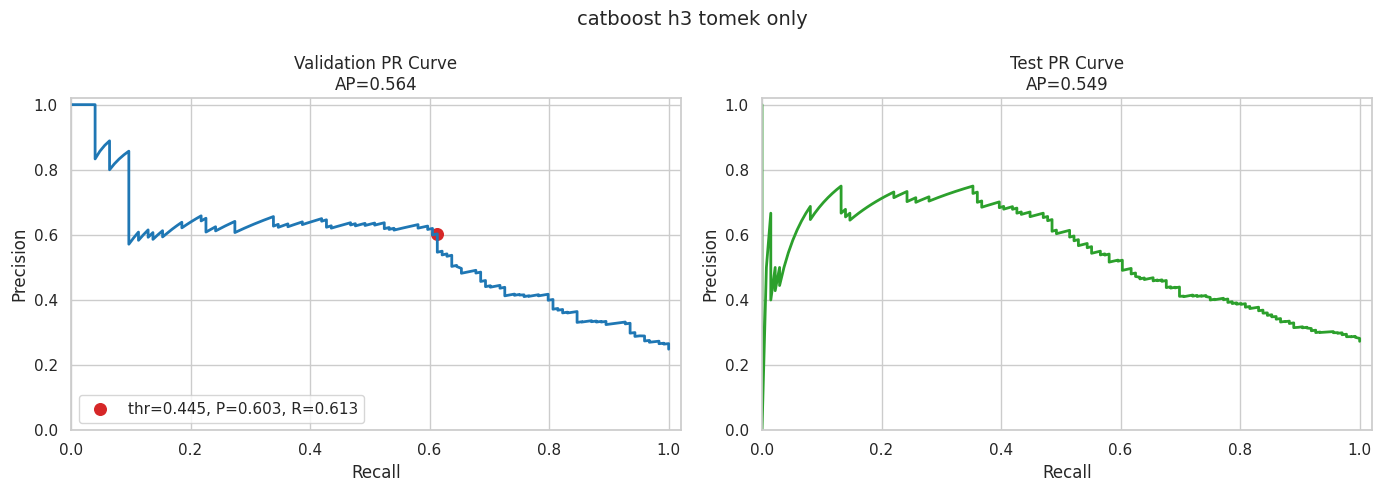

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_only,CatBoost,3,tomek_only,14,1494,498,498,101,0.444547,0.603175,0.612903,0.608,0.563985,0.781687,0.559701,0.551471,0.555556,0.54884,0.749858,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.444547,0.603175,0.612903,0.608,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,725,0.033799,8,10.214708,0.633484,2.913683,148,1.159145


#### Classification report on test

,precision,recall,f1-score,support
0,0.832418,0.837017,0.834711,362.000000
1,0.559701,0.551471,0.555556,136.000000
accuracy,0.759036,0.759036,0.759036,0.759036
macro avg,0.696060,0.694244,0.695133,498.000000
weighted avg,0.757941,0.759036,0.758476,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,303,59
Actual 1,61,75


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_only,CatBoost,3,tomek_only,14,1494,498,498,101,0.444547,0.603175,0.612903,0.608,0.563985,0.781687,0.559701,0.551471,0.555556,0.54884,0.749858,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=3,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 3 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

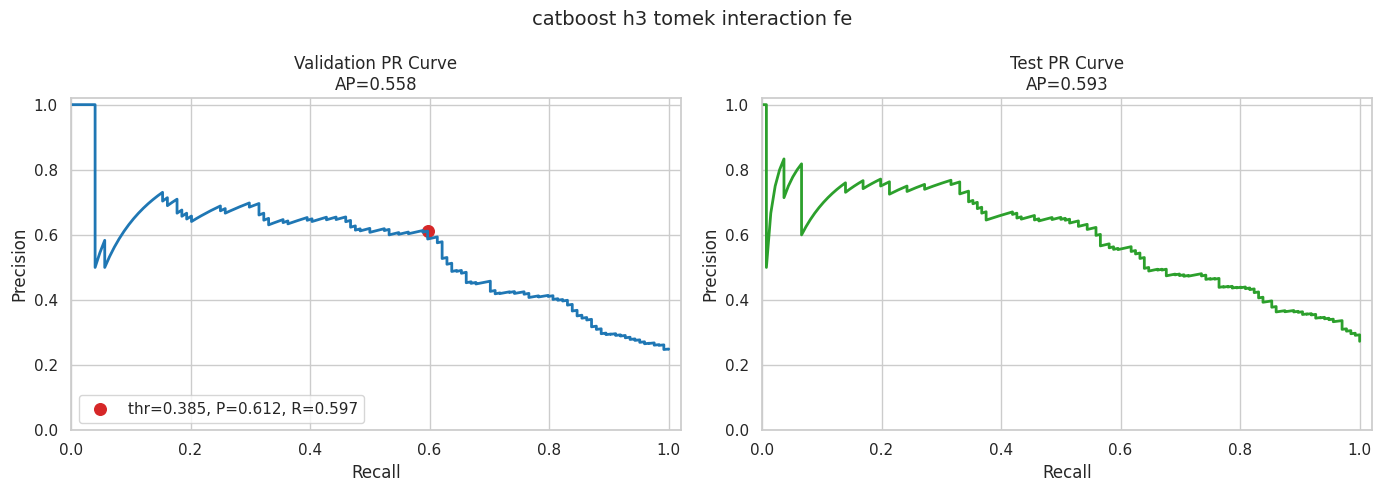

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_interaction_fe,CatBoost,3,tomek_interaction_fe,16,1494,498,498,95,0.384826,0.61157,0.596774,0.604082,0.558277,0.774194,0.637168,0.529412,0.578313,0.593142,0.787679,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.384826,0.61157,0.596774,0.604082,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,561,0.083411,4,19.428287,4.162213,1.061696,98,1.351838


#### Classification report on test

,precision,recall,f1-score,support
0,0.833766,0.886740,0.859438,362.000000
1,0.637168,0.529412,0.578313,136.000000
accuracy,0.789157,0.789157,0.789157,0.789157
macro avg,0.735467,0.708076,0.718876,498.000000
weighted avg,0.780077,0.789157,0.782665,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,321,41
Actual 1,64,72


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_interaction_fe,CatBoost,3,tomek_interaction_fe,16,1494,498,498,95,0.384826,0.61157,0.596774,0.604082,0.558277,0.774194,0.637168,0.529412,0.578313,0.593142,0.787679,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=3,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 3 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

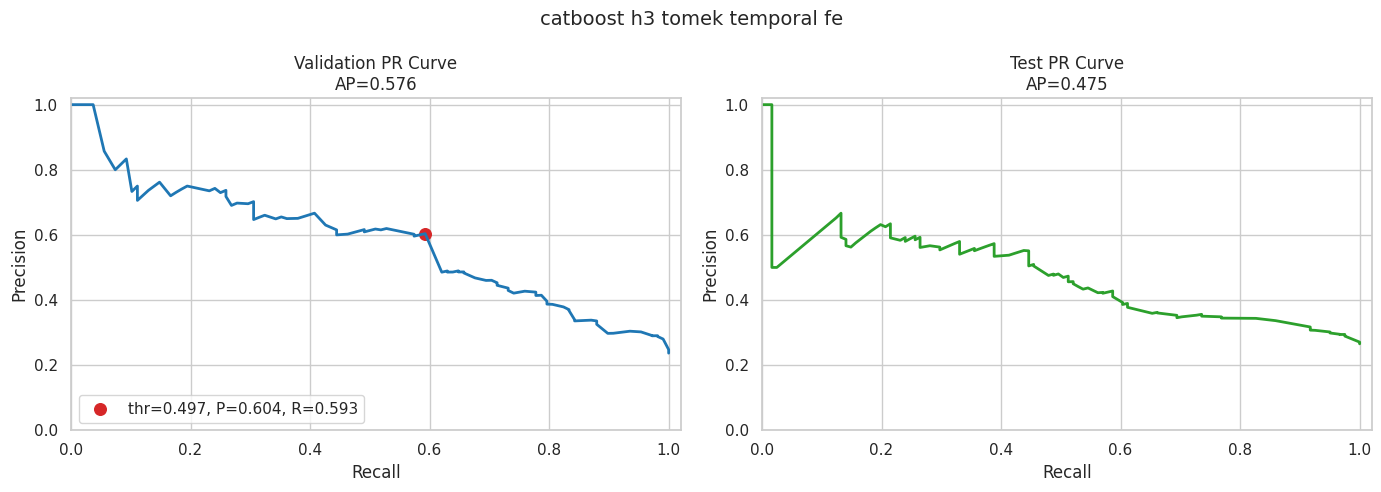

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_temporal_fe,CatBoost,3,tomek_temporal_fe,183,1368,456,456,74,0.49658,0.603774,0.592593,0.598131,0.575932,0.795857,0.509259,0.454545,0.480349,0.474508,0.704058,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.49658,0.603774,0.592593,0.598131,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,422,0.028083,6,8.31439,0.824923,2.234412,101,1.610055


#### Classification report on test

,precision,recall,f1-score,support
0,0.810345,0.841791,0.825769,335.000000
1,0.509259,0.454545,0.480349,121.000000
accuracy,0.739035,0.739035,0.739035,0.739035
macro avg,0.659802,0.648168,0.653059,456.000000
weighted avg,0.730452,0.739035,0.734111,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,282,53
Actual 1,66,55


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_temporal_fe,CatBoost,3,tomek_temporal_fe,183,1368,456,456,74,0.49658,0.603774,0.592593,0.598131,0.575932,0.795857,0.509259,0.454545,0.480349,0.474508,0.704058,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=3,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## CatBoost | Horizon 3 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

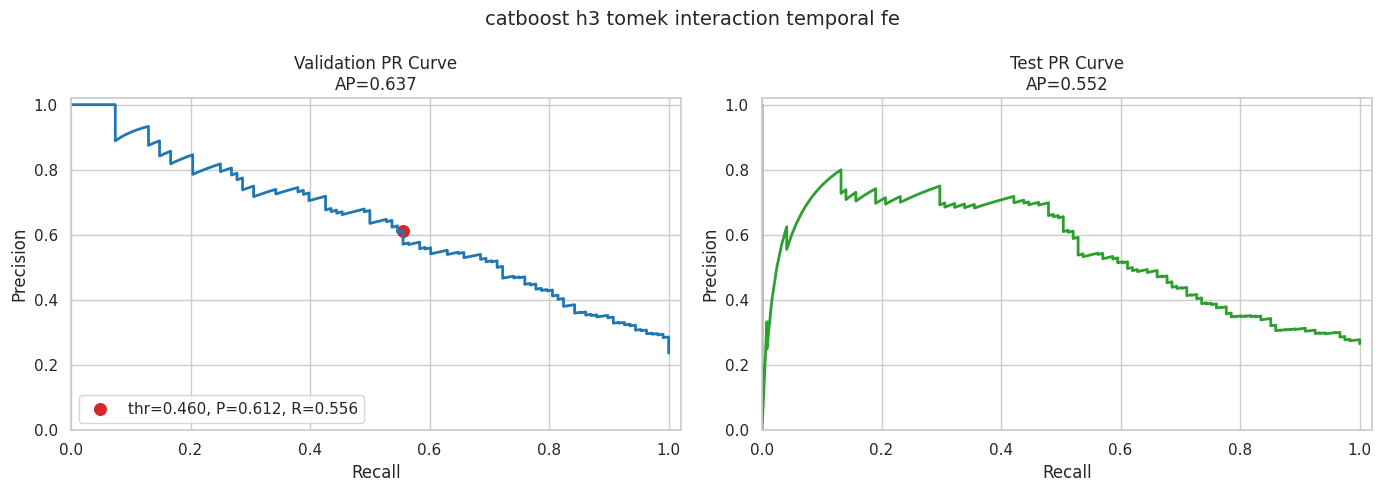

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_interaction_temporal_fe,CatBoost,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.459647,0.612245,0.555556,0.582524,0.637115,0.821174,0.59434,0.520661,0.555066,0.551837,0.750635,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.459647,0.612245,0.555556,0.582524,True,False


#### Best hyperparameters

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,scale_pos_weight
0,354,0.028851,6,8.31439,0.236692,3.32309,255,1.517724


#### Classification report on test

,precision,recall,f1-score,support
0,0.834286,0.871642,0.852555,335.000000
1,0.594340,0.520661,0.555066,121.000000
accuracy,0.778509,0.778509,0.778509,0.778509
macro avg,0.714313,0.696151,0.703810,456.000000
weighted avg,0.770616,0.778509,0.773616,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,292,43
Actual 1,58,63


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,catboost_h3_tomek_interaction_temporal_fe,CatBoost,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.459647,0.612245,0.555556,0.582524,0.637115,0.821174,0.59434,0.520661,0.555066,0.551837,0.750635,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="CatBoost",
    horizon=3,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 2 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

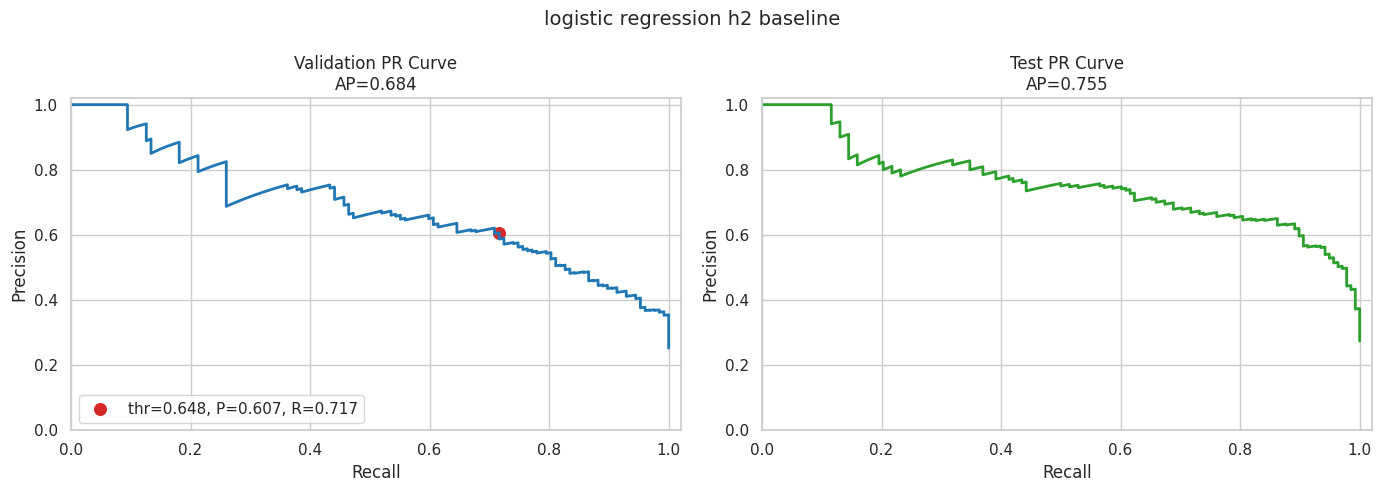

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_baseline,Logistic Regression,2,baseline,14,1512,504,504,0,0.647901,0.606667,0.716535,0.65704,0.683711,0.863385,0.673469,0.717391,0.694737,0.754763,0.904075,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.647901,0.606667,0.716535,0.65704,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,2.803387,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.890756,0.868852,0.879668,366.000000
1,0.673469,0.717391,0.694737,138.000000
accuracy,0.827381,0.827381,0.827381,0.827381
macro avg,0.782113,0.793122,0.787202,504.000000
weighted avg,0.831261,0.827381,0.829032,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,318,48
Actual 1,39,99


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_baseline,Logistic Regression,2,baseline,14,1512,504,504,0,0.647901,0.606667,0.716535,0.65704,0.683711,0.863385,0.673469,0.717391,0.694737,0.754763,0.904075,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=2,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 2 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

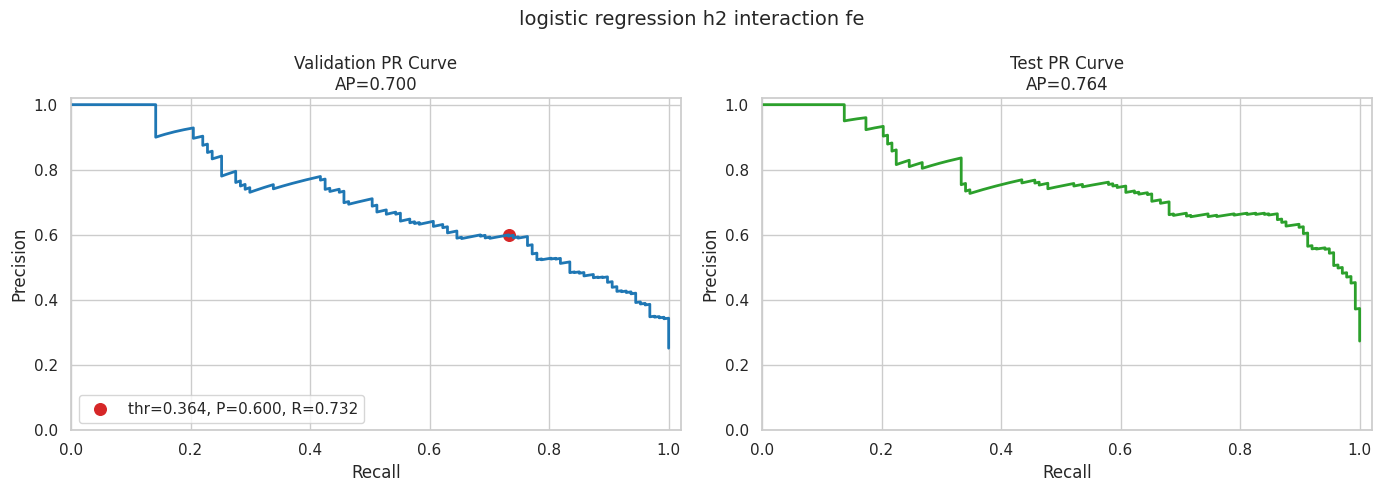

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_interaction_fe,Logistic Regression,2,interaction_fe,16,1512,504,504,0,0.364405,0.6,0.732283,0.659574,0.699598,0.865494,0.660131,0.731884,0.694158,0.764139,0.905975,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.364405,0.6,0.732283,0.659574,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l2,4.570563,None,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.894587,0.857923,0.875872,366.000000
1,0.660131,0.731884,0.694158,138.000000
accuracy,0.823413,0.823413,0.823413,0.823413
macro avg,0.777359,0.794904,0.785015,504.000000
weighted avg,0.830391,0.823413,0.826117,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,314,52
Actual 1,37,101


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_interaction_fe,Logistic Regression,2,interaction_fe,16,1512,504,504,0,0.364405,0.6,0.732283,0.659574,0.699598,0.865494,0.660131,0.731884,0.694158,0.764139,0.905975,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=2,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 2 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

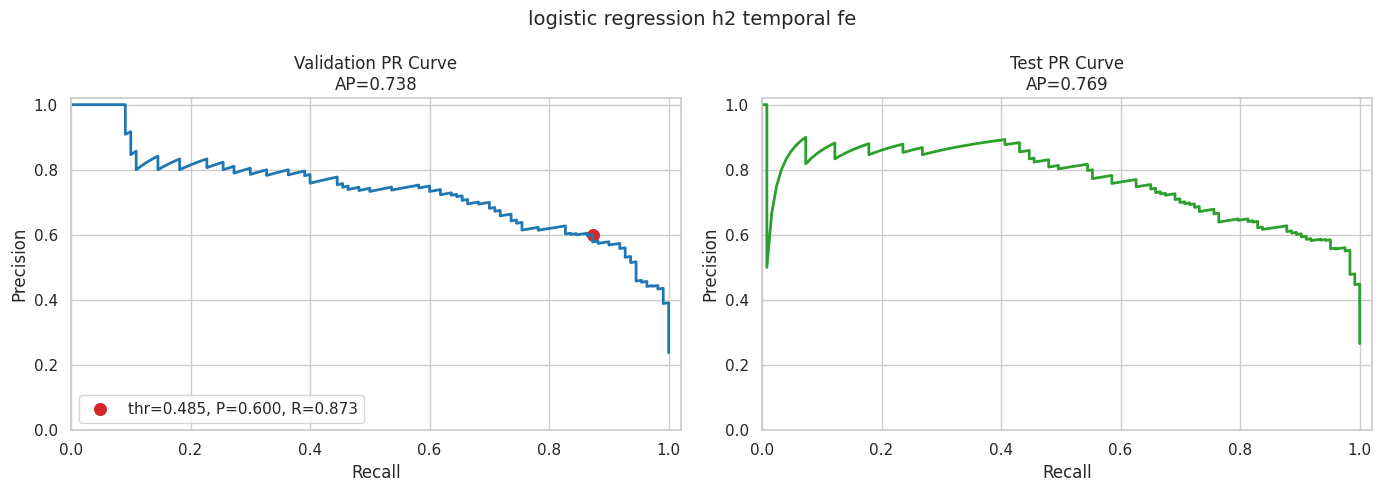

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_temporal_fe,Logistic Regression,2,temporal_fe,183,1386,462,462,0,0.485033,0.6,0.872727,0.711111,0.737888,0.912474,0.644295,0.780488,0.705882,0.768834,0.918963,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.485033,0.6,0.872727,0.711111,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.134384,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.913738,0.843658,0.877301,339.00000
1,0.644295,0.780488,0.705882,123.00000
accuracy,0.826840,0.826840,0.826840,0.82684
macro avg,0.779017,0.812073,0.791591,462.00000
weighted avg,0.842003,0.826840,0.831663,462.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,286,53
Actual 1,27,96


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_temporal_fe,Logistic Regression,2,temporal_fe,183,1386,462,462,0,0.485033,0.6,0.872727,0.711111,0.737888,0.912474,0.644295,0.780488,0.705882,0.768834,0.918963,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=2,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 2 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

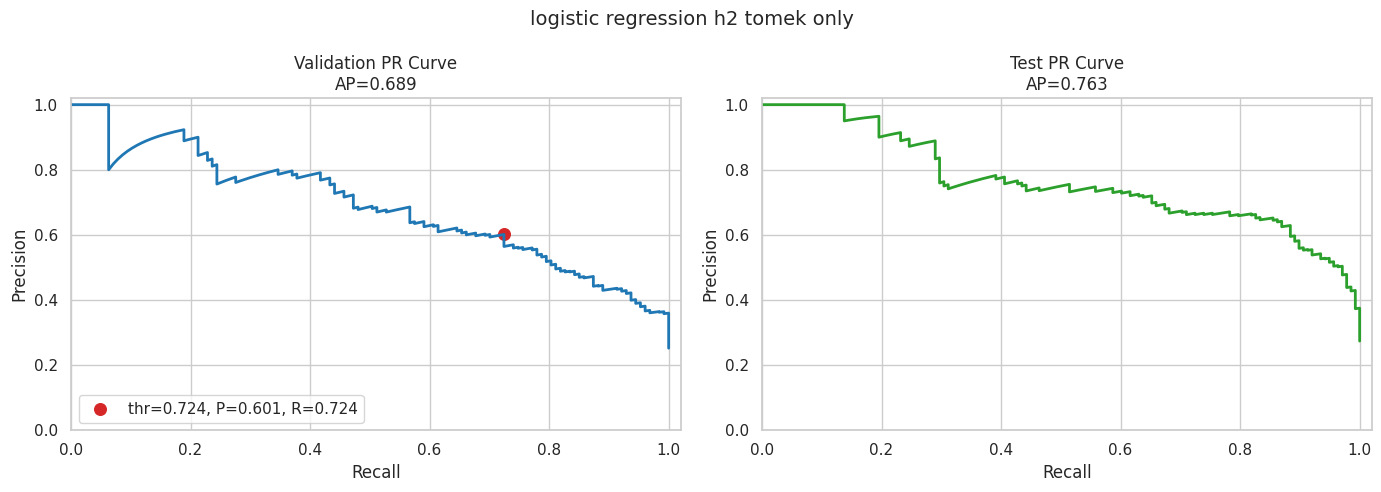

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_only,Logistic Regression,2,tomek_only,14,1512,504,504,88,0.723735,0.601307,0.724409,0.657143,0.688739,0.86328,0.666667,0.73913,0.701031,0.762983,0.901936,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.723735,0.601307,0.724409,0.657143,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.516988,balanced,False


#### Classification report on test

,precision,recall,f1-score,support
0,0.897436,0.860656,0.878661,366.000000
1,0.666667,0.739130,0.701031,138.000000
accuracy,0.827381,0.827381,0.827381,0.827381
macro avg,0.782051,0.799893,0.789846,504.000000
weighted avg,0.834249,0.827381,0.830024,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,315,51
Actual 1,36,102


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_only,Logistic Regression,2,tomek_only,14,1512,504,504,88,0.723735,0.601307,0.724409,0.657143,0.688739,0.86328,0.666667,0.73913,0.701031,0.762983,0.901936,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=2,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 2 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

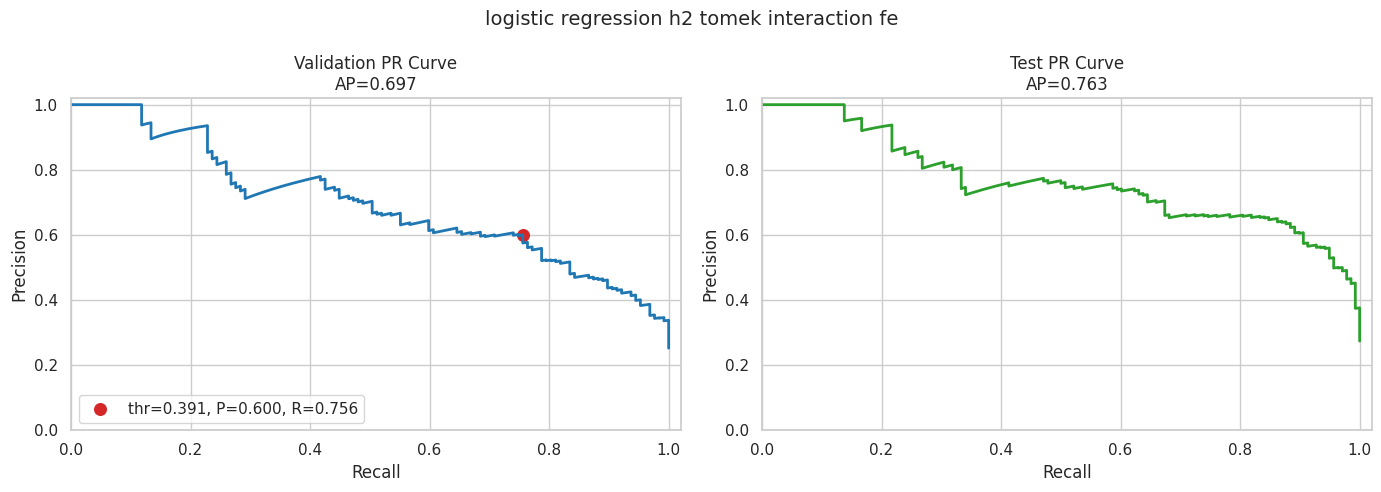

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_interaction_fe,Logistic Regression,2,tomek_interaction_fe,16,1512,504,504,82,0.391476,0.6,0.755906,0.66899,0.696995,0.864325,0.658065,0.73913,0.696246,0.763057,0.90455,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.391476,0.6,0.755906,0.66899,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l2,4.570563,None,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.896848,0.855191,0.875524,366.000000
1,0.658065,0.739130,0.696246,138.000000
accuracy,0.823413,0.823413,0.823413,0.823413
macro avg,0.777456,0.797161,0.785885,504.000000
weighted avg,0.831467,0.823413,0.826436,504.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,313,53
Actual 1,36,102


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_interaction_fe,Logistic Regression,2,tomek_interaction_fe,16,1512,504,504,82,0.391476,0.6,0.755906,0.66899,0.696995,0.864325,0.658065,0.73913,0.696246,0.763057,0.90455,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=2,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 2 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

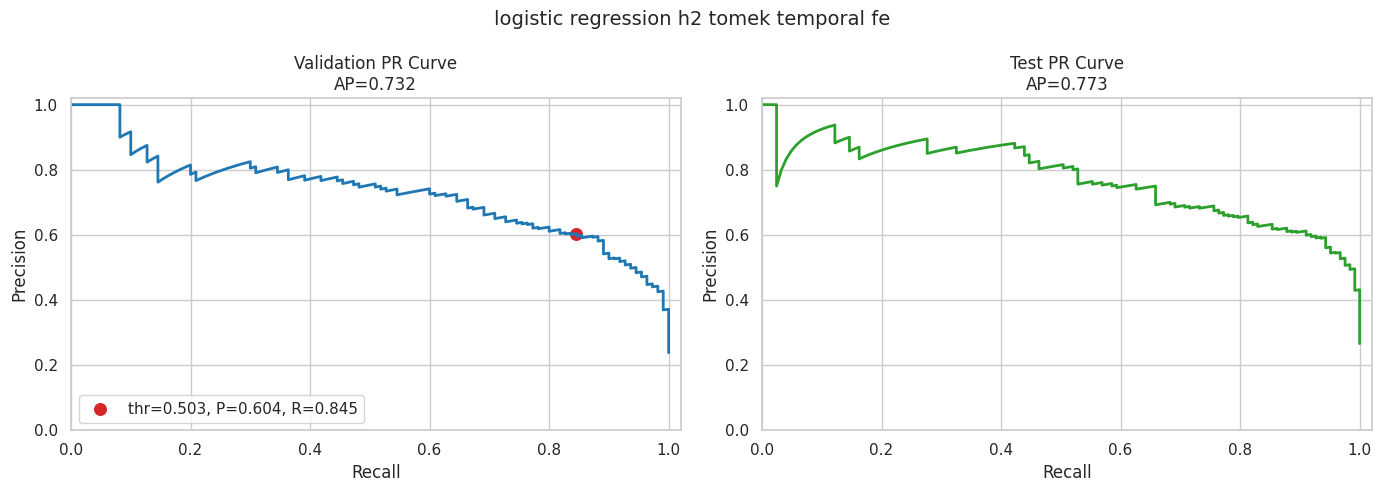

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_temporal_fe,Logistic Regression,2,tomek_temporal_fe,183,1386,462,462,77,0.502502,0.603896,0.845455,0.704545,0.732316,0.909737,0.659864,0.788618,0.718519,0.772927,0.917164,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.502502,0.603896,0.845455,0.704545,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.148519,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.917460,0.852507,0.883792,339.000000
1,0.659864,0.788618,0.718519,123.000000
accuracy,0.835498,0.835498,0.835498,0.835498
macro avg,0.788662,0.820563,0.801155,462.000000
weighted avg,0.848879,0.835498,0.839791,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,289,50
Actual 1,26,97


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_temporal_fe,Logistic Regression,2,tomek_temporal_fe,183,1386,462,462,77,0.502502,0.603896,0.845455,0.704545,0.732316,0.909737,0.659864,0.788618,0.718519,0.772927,0.917164,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=2,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])

## Logistic Regression | Horizon 2 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

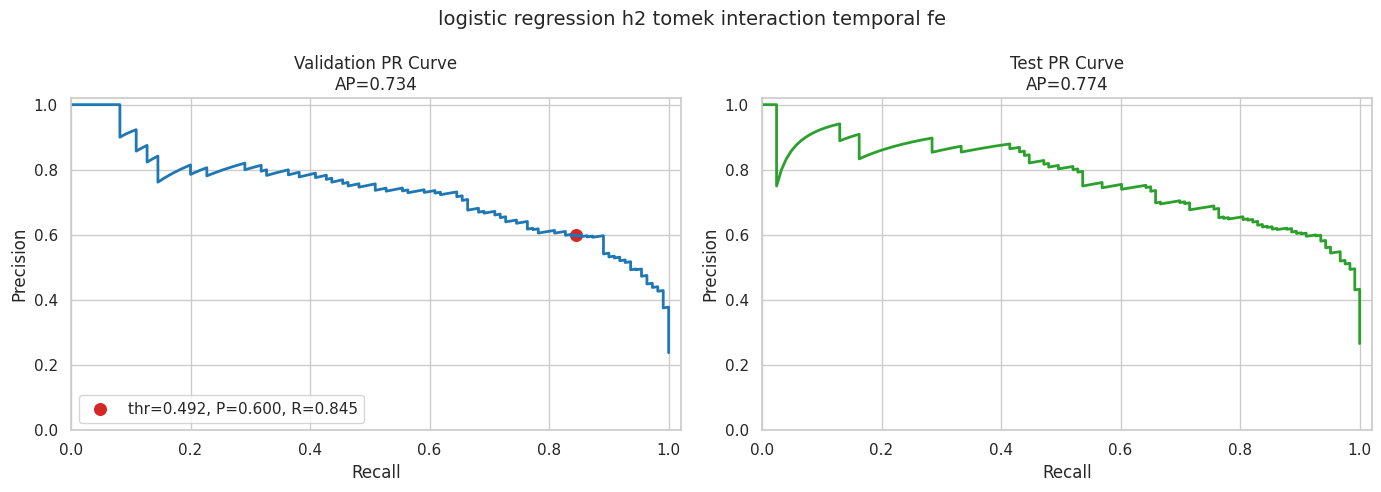

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_interaction_tempo...,Logistic Regression,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.491741,0.6,0.845455,0.701887,0.733999,0.910279,0.653333,0.796748,0.717949,0.774428,0.917236,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.491741,0.6,0.845455,0.701887,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.148519,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.919872,0.846608,0.881720,339.000000
1,0.653333,0.796748,0.717949,123.000000
accuracy,0.833333,0.833333,0.833333,0.833333
macro avg,0.786603,0.821678,0.799835,462.000000
weighted avg,0.848910,0.833333,0.838119,462.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,287,52
Actual 1,25,98


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_interaction_tempo...,Logistic Regression,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.491741,0.6,0.845455,0.701887,0.733999,0.910279,0.653333,0.796748,0.717949,0.774428,0.917236,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=2,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 3 | baseline

Base predictors only.


### Preparing data

### Model training with Optuna

### Evaluation outputs

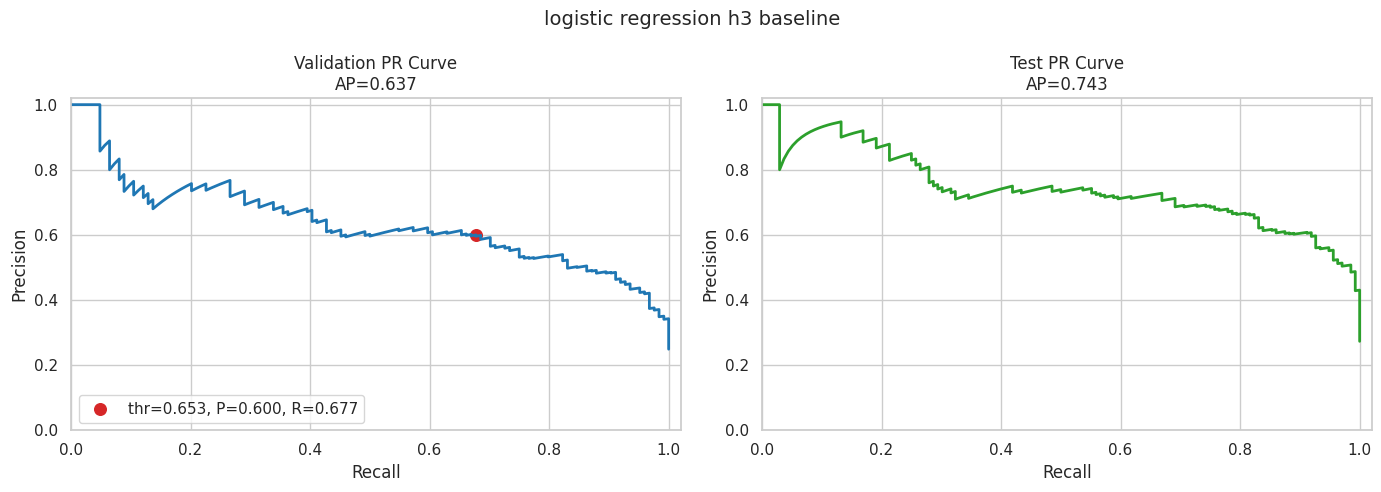

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_baseline,Logistic Regression,3,baseline,14,1494,498,498,0,0.653334,0.6,0.677419,0.636364,0.63745,0.860876,0.701493,0.691176,0.696296,0.742955,0.905305,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.653334,0.6,0.677419,0.636364,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.209934,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.884615,0.889503,0.887052,362.000000
1,0.701493,0.691176,0.696296,136.000000
accuracy,0.835341,0.835341,0.835341,0.835341
macro avg,0.793054,0.790340,0.791674,498.000000
weighted avg,0.834606,0.835341,0.834958,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,322,40
Actual 1,42,94


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_baseline,Logistic Regression,3,baseline,14,1494,498,498,0,0.653334,0.6,0.677419,0.636364,0.63745,0.860876,0.701493,0.691176,0.696296,0.742955,0.905305,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=3,
    variant="baseline",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 3 | interaction_fe

Base predictors plus the two manual interaction features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

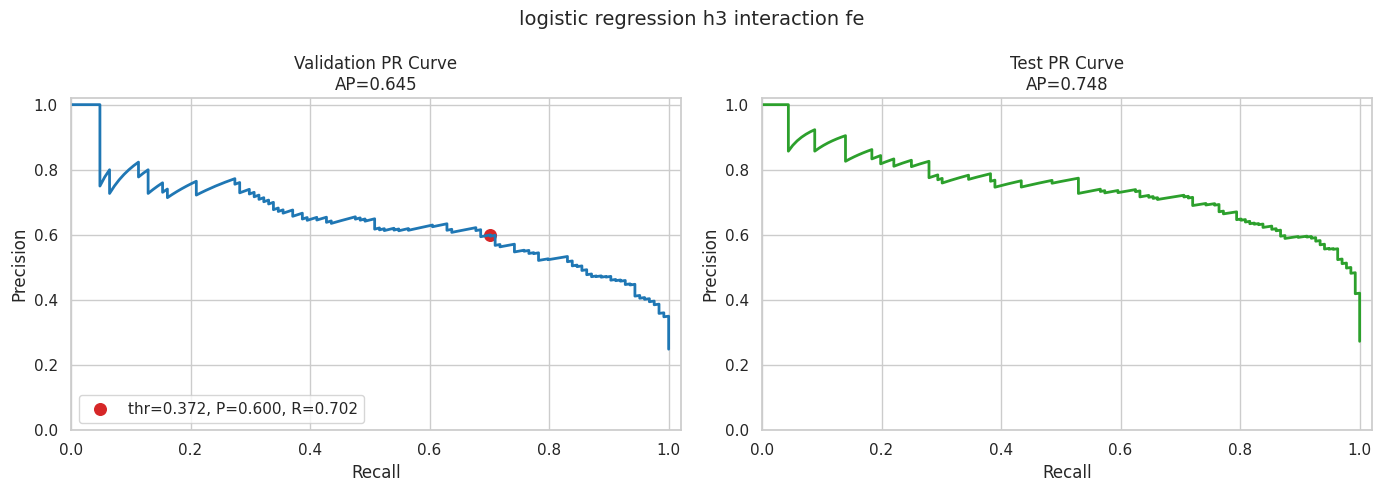

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_interaction_fe,Logistic Regression,3,interaction_fe,16,1494,498,498,0,0.371788,0.6,0.701613,0.64684,0.645343,0.863874,0.690141,0.720588,0.705036,0.747604,0.907459,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.371788,0.6,0.701613,0.64684,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l2,1.418926,None,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.893258,0.878453,0.885794,362.000000
1,0.690141,0.720588,0.705036,136.000000
accuracy,0.835341,0.835341,0.835341,0.835341
macro avg,0.791700,0.799521,0.795415,498.000000
weighted avg,0.837789,0.835341,0.836430,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,318,44
Actual 1,38,98


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_interaction_fe,Logistic Regression,3,interaction_fe,16,1494,498,498,0,0.371788,0.6,0.701613,0.64684,0.645343,0.863874,0.690141,0.720588,0.705036,0.747604,0.907459,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=3,
    variant="interaction_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 3 | temporal_fe

Base predictors plus within-year lag, rolling, and trend features.


### Preparing data

### Model training with Optuna

### Evaluation outputs

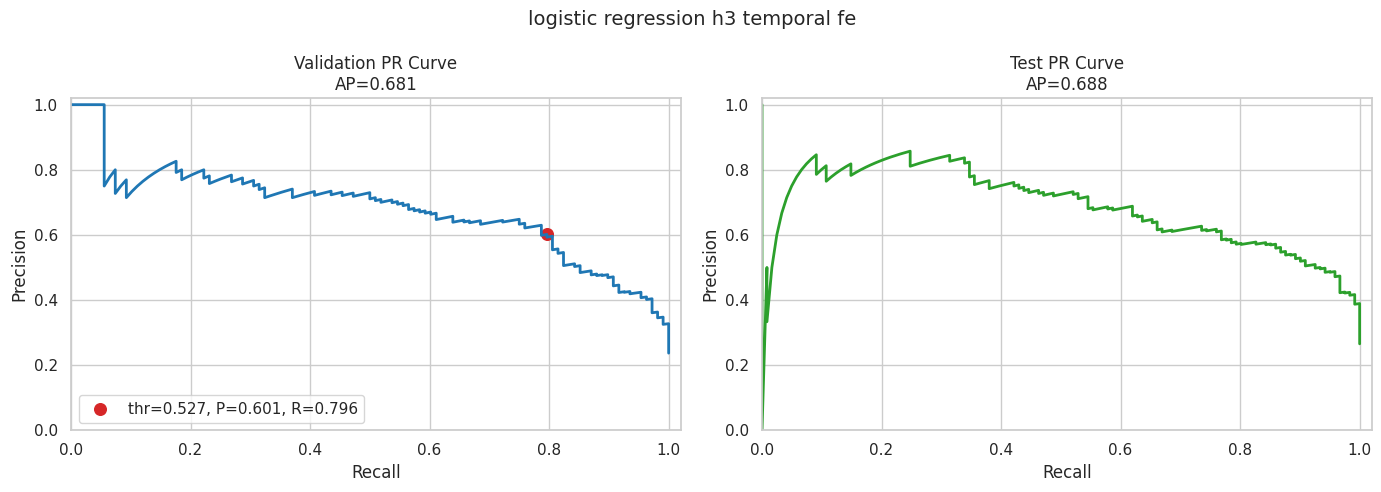

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_temporal_fe,Logistic Regression,3,temporal_fe,183,1368,456,456,0,0.527437,0.601399,0.796296,0.685259,0.68149,0.883967,0.644628,0.644628,0.644628,0.688062,0.883804,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.527437,0.601399,0.796296,0.685259,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.081658,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.871642,0.871642,0.871642,335.000000
1,0.644628,0.644628,0.644628,121.000000
accuracy,0.811404,0.811404,0.811404,0.811404
macro avg,0.758135,0.758135,0.758135,456.000000
weighted avg,0.811404,0.811404,0.811404,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,292,43
Actual 1,43,78


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_temporal_fe,Logistic Regression,3,temporal_fe,183,1368,456,456,0,0.527437,0.601399,0.796296,0.685259,0.68149,0.883967,0.644628,0.644628,0.644628,0.688062,0.883804,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=3,
    variant="temporal_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 3 | tomek_only

Base predictors with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

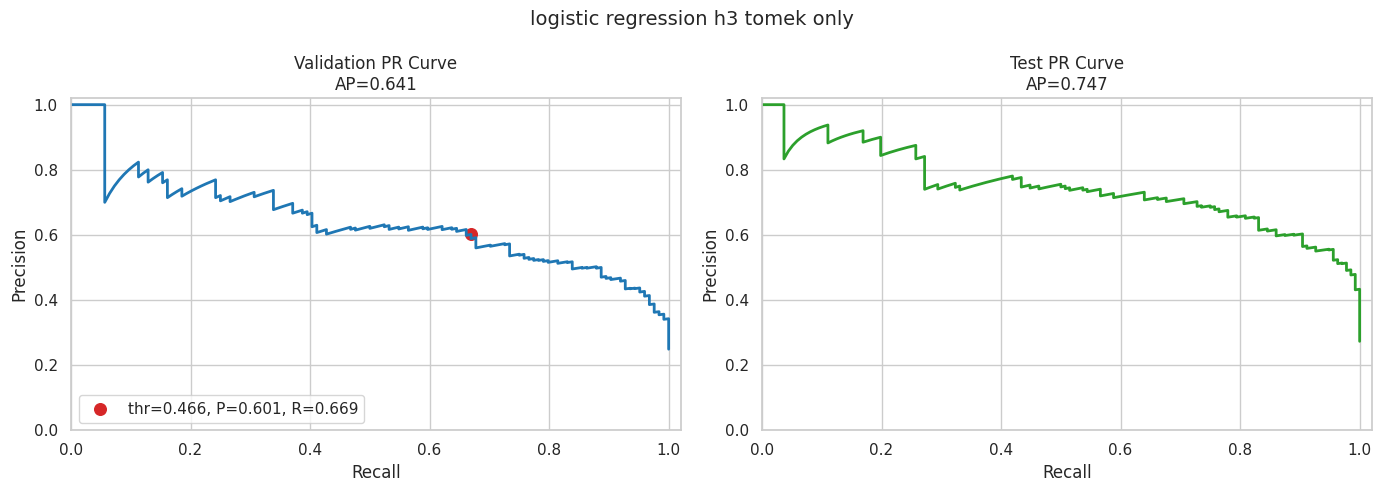

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_only,Logistic Regression,3,tomek_only,14,1494,498,498,101,0.465773,0.601449,0.669355,0.633588,0.641464,0.860963,0.714286,0.661765,0.687023,0.747368,0.905123,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.465773,0.601449,0.669355,0.633588,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l2,2.803387,None,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.876344,0.900552,0.888283,362.000000
1,0.714286,0.661765,0.687023,136.000000
accuracy,0.835341,0.835341,0.835341,0.835341
macro avg,0.795315,0.781159,0.787653,498.000000
weighted avg,0.832087,0.835341,0.833321,498.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,326,36
Actual 1,46,90


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_only,Logistic Regression,3,tomek_only,14,1494,498,498,101,0.465773,0.601449,0.669355,0.633588,0.641464,0.860963,0.714286,0.661765,0.687023,0.747368,0.905123,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=3,
    variant="tomek_only",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 3 | tomek_interaction_fe

Interaction features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

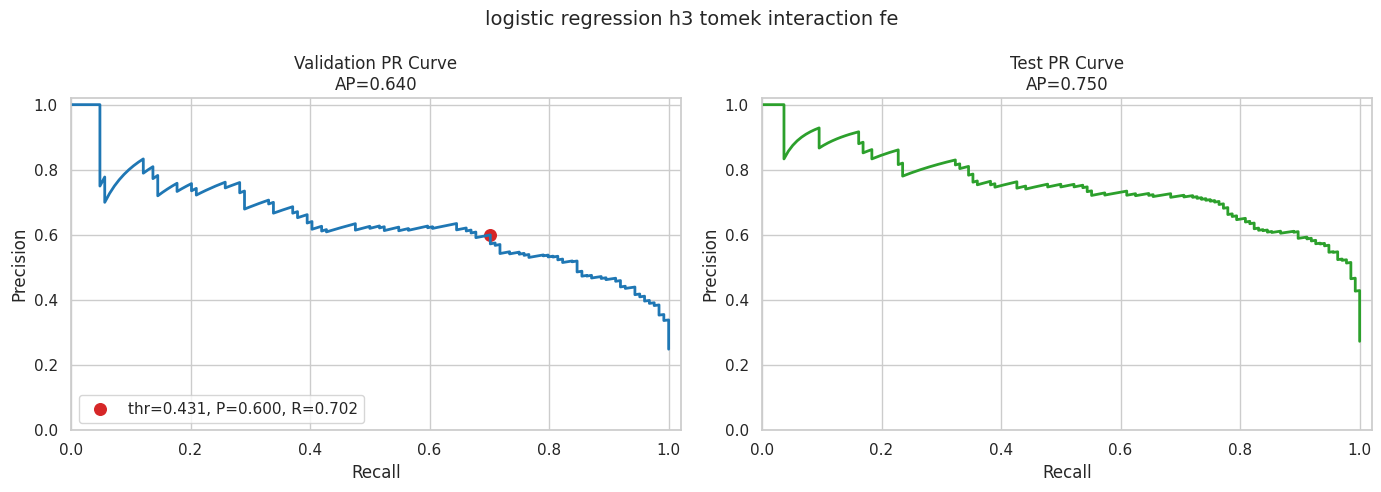

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_interaction_fe,Logistic Regression,3,tomek_interaction_fe,16,1494,498,498,95,0.430623,0.6,0.701613,0.64684,0.640244,0.860574,0.714286,0.735294,0.724638,0.750327,0.907966,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.430623,0.6,0.701613,0.64684,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l2,2.803387,None,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.899441,0.889503,0.894444,362.00000
1,0.714286,0.735294,0.724638,136.00000
accuracy,0.847390,0.847390,0.847390,0.84739
macro avg,0.806864,0.812398,0.809541,498.00000
weighted avg,0.848877,0.847390,0.848072,498.00000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,322,40
Actual 1,36,100


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_interaction_fe,Logistic Regression,3,tomek_interaction_fe,16,1494,498,498,95,0.430623,0.6,0.701613,0.64684,0.640244,0.860574,0.714286,0.735294,0.724638,0.750327,0.907966,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=3,
    variant="tomek_interaction_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 3 | tomek_temporal_fe

Temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

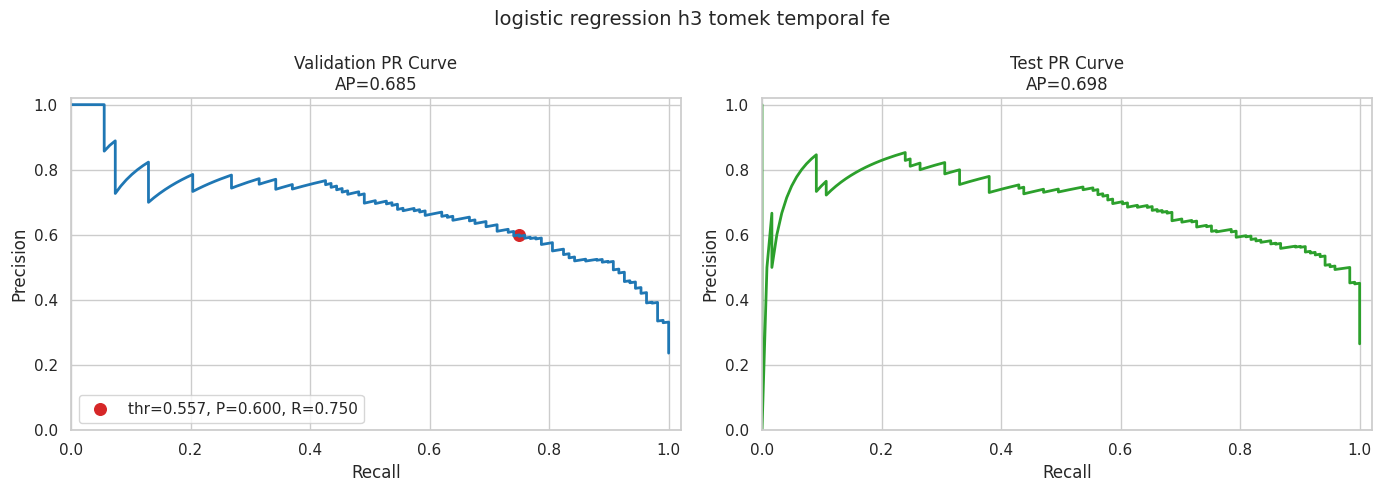

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_temporal_fe,Logistic Regression,3,tomek_temporal_fe,183,1368,456,456,74,0.557426,0.6,0.75,0.666667,0.685277,0.888649,0.685185,0.61157,0.646288,0.69798,0.895547,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.557426,0.6,0.75,0.666667,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.110082,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.864943,0.898507,0.881406,335.000000
1,0.685185,0.611570,0.646288,121.000000
accuracy,0.822368,0.822368,0.822368,0.822368
macro avg,0.775064,0.755039,0.763847,456.000000
weighted avg,0.817244,0.822368,0.819017,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,301,34
Actual 1,47,74


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_temporal_fe,Logistic Regression,3,tomek_temporal_fe,183,1368,456,456,74,0.557426,0.6,0.75,0.666667,0.685277,0.888649,0.685185,0.61157,0.646288,0.69798,0.895547,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=3,
    variant="tomek_temporal_fe",
)
pd.DataFrame([experiment_result])


## Logistic Regression | Horizon 3 | tomek_interaction_temporal_fe

Interaction and temporal features with Tomek Links on the training split.


### Preparing data

### Model training with Optuna

### Evaluation outputs

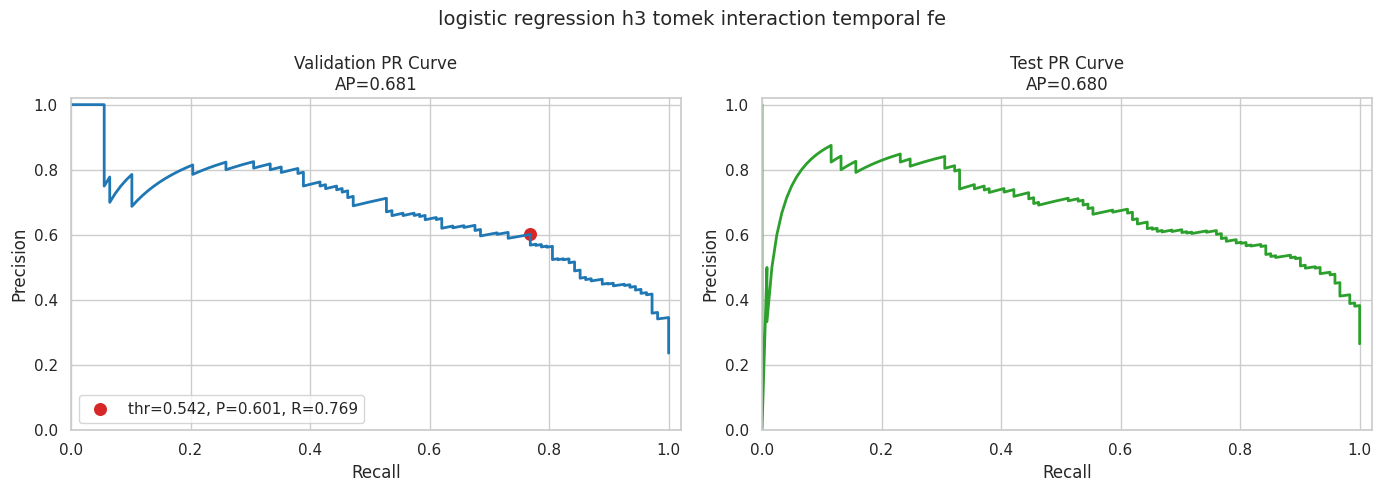

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_interaction_tempo...,Logistic Regression,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.541989,0.601449,0.768519,0.674797,0.680602,0.881173,0.633333,0.628099,0.630705,0.680125,0.878229,True


#### Validation threshold summary

,threshold,precision,recall,f1,precision_floor_met,fallback_used
0,0.541989,0.601449,0.768519,0.674797,True,False


#### Best hyperparameters

,penalty,C,class_weight,fit_intercept
0,l1,0.081658,balanced,True


#### Classification report on test

,precision,recall,f1-score,support
0,0.866071,0.868657,0.867362,335.000000
1,0.633333,0.628099,0.630705,121.000000
accuracy,0.804825,0.804825,0.804825,0.804825
macro avg,0.749702,0.748378,0.749034,456.000000
weighted avg,0.804314,0.804825,0.804565,456.000000


#### Confusion matrix on test

,Pred 0,Pred 1
Actual 0,291,44
Actual 1,45,76


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h3_tomek_interaction_tempo...,Logistic Regression,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.541989,0.601449,0.768519,0.674797,0.680602,0.881173,0.633333,0.628099,0.630705,0.680125,0.878229,True


In [ ]:
experiment_result = run_single_experiment(
    model_name="Logistic Regression",
    horizon=3,
    variant="tomek_interaction_temporal_fe",
)
pd.DataFrame([experiment_result])


## Global Comparison

After all experiment sections have run, this cell aggregates their outputs, writes the global summary CSV, and surfaces the most recall-oriented candidates.


In [ ]:
if not EXPERIMENT_RESULTS:
    raise RuntimeError("No experiments have been executed yet.")

global_summary_df = pd.DataFrame(EXPERIMENT_RESULTS.values()).sort_values(
    ["horizon", "test_recall_1", "test_pr_auc"],
    ascending=[True, False, False],
).reset_index(drop=True)

global_summary_path = OUTPUT_DIR / "summary_all_experiments.csv"
global_summary_df.to_csv(global_summary_path, index=False)

display(Markdown("### All experiments sorted by horizon and test recall"))
display(global_summary_df)

filtered_precision_df = global_summary_df.loc[global_summary_df["test_precision_1"] >= MIN_PRECISION].copy()
display(Markdown("### Experiments with test precision at or above 0.60"))
display(filtered_precision_df)

top3_per_horizon = (
    global_summary_df.sort_values(["horizon", "test_recall_1", "test_pr_auc"], ascending=[True, False, False])
    .groupby("horizon", as_index=False)
    .head(3)
    .reset_index(drop=True)
)
display(Markdown("### Top 3 experiments per horizon"))
display(top3_per_horizon)

print(f"Saved combined summary to: {global_summary_path}")


### All experiments sorted by horizon and test recall

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_interaction_tempo...,Logistic Regression,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.491741,0.600000,0.845455,0.701887,0.733999,0.910279,0.653333,0.796748,0.717949,0.774428,0.917236,True
1,logistic_regression_h2_tomek_temporal_fe,Logistic Regression,2,tomek_temporal_fe,183,1386,462,462,77,0.502502,0.603896,0.845455,0.704545,0.732316,0.909737,0.659864,0.788618,0.718519,0.772927,0.917164,True
2,logistic_regression_h2_temporal_fe,Logistic Regression,2,temporal_fe,183,1386,462,462,0,0.485033,0.600000,0.872727,0.711111,0.737888,0.912474,0.644295,0.780488,0.705882,0.768834,0.918963,True
3,logistic_regression_h2_tomek_interaction_fe,Logistic Regression,2,tomek_interaction_fe,16,1512,504,504,82,0.391476,0.600000,0.755906,0.668990,0.696995,0.864325,0.658065,0.739130,0.696246,0.763057,0.904550,True
4,logistic_regression_h2_tomek_only,Logistic Regression,2,tomek_only,14,1512,504,504,88,0.723735,0.601307,0.724409,0.657143,0.688739,0.863280,0.666667,0.739130,0.701031,0.762983,0.901936,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,xgboost_h3_tomek_temporal_fe,XGBoost,3,tomek_temporal_fe,183,1368,456,456,74,0.361831,0.607843,0.574074,0.590476,0.606432,0.783073,0.543860,0.512397,0.527660,0.526101,0.746713,True
66,catboost_h3_baseline,CatBoost,3,baseline,14,1494,498,498,0,0.285106,0.600000,0.629032,0.614173,0.569009,0.805287,0.539062,0.507353,0.522727,0.555446,0.755403,True
67,lightgbm_h3_tomek_interaction_temporal_fe,LightGBM,3,tomek_interaction_temporal_fe,185,1368,456,456,74,0.411640,0.606383,0.527778,0.564356,0.625498,0.805316,0.564356,0.471074,0.513514,0.539513,0.741964,True
68,catboost_h3_tomek_temporal_fe,CatBoost,3,tomek_temporal_fe,183,1368,456,456,74,0.496580,0.603774,0.592593,0.598131,0.575932,0.795857,0.509259,0.454545,0.480349,0.474508,0.704058,True


### Experiments with test precision at or above 0.60

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_interaction_tempo...,Logistic Regression,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.491741,0.600000,0.845455,0.701887,0.733999,0.910279,0.653333,0.796748,0.717949,0.774428,0.917236,True
1,logistic_regression_h2_tomek_temporal_fe,Logistic Regression,2,tomek_temporal_fe,183,1386,462,462,77,0.502502,0.603896,0.845455,0.704545,0.732316,0.909737,0.659864,0.788618,0.718519,0.772927,0.917164,True
2,logistic_regression_h2_temporal_fe,Logistic Regression,2,temporal_fe,183,1386,462,462,0,0.485033,0.600000,0.872727,0.711111,0.737888,0.912474,0.644295,0.780488,0.705882,0.768834,0.918963,True
3,logistic_regression_h2_tomek_interaction_fe,Logistic Regression,2,tomek_interaction_fe,16,1512,504,504,82,0.391476,0.600000,0.755906,0.668990,0.696995,0.864325,0.658065,0.739130,0.696246,0.763057,0.904550,True
4,logistic_regression_h2_tomek_only,Logistic Regression,2,tomek_only,14,1512,504,504,88,0.723735,0.601307,0.724409,0.657143,0.688739,0.863280,0.666667,0.739130,0.701031,0.762983,0.901936,True
5,logistic_regression_h2_interaction_fe,Logistic Regression,2,interaction_fe,16,1512,504,504,0,0.364405,0.600000,0.732283,0.659574,0.699598,0.865494,0.660131,0.731884,0.694158,0.764139,0.905975,True
6,logistic_regression_h2_baseline,Logistic Regression,2,baseline,14,1512,504,504,0,0.647901,0.606667,0.716535,0.657040,0.683711,0.863385,0.673469,0.717391,0.694737,0.754763,0.904075,True
7,lightgbm_h2_tomek_interaction_temporal_fe,LightGBM,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.426100,0.600000,0.572727,0.586047,0.634154,0.827454,0.713043,0.666667,0.689076,0.702977,0.849366,True
8,xgboost_h2_tomek_temporal_fe,XGBoost,2,tomek_temporal_fe,183,1386,462,462,77,0.459193,0.605263,0.627273,0.616071,0.570516,0.795919,0.630769,0.666667,0.648221,0.680239,0.841140,True
9,catboost_h2_temporal_fe,CatBoost,2,temporal_fe,183,1386,462,462,0,0.411541,0.604839,0.681818,0.641026,0.623717,0.834827,0.602941,0.666667,0.633205,0.671366,0.844581,True


### Top 3 experiments per horizon

,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
0,logistic_regression_h2_tomek_interaction_tempo...,Logistic Regression,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.491741,0.600000,0.845455,0.701887,0.733999,0.910279,0.653333,0.796748,0.717949,0.774428,0.917236,True
1,logistic_regression_h2_tomek_temporal_fe,Logistic Regression,2,tomek_temporal_fe,183,1386,462,462,77,0.502502,0.603896,0.845455,0.704545,0.732316,0.909737,0.659864,0.788618,0.718519,0.772927,0.917164,True
2,logistic_regression_h2_temporal_fe,Logistic Regression,2,temporal_fe,183,1386,462,462,0,0.485033,0.600000,0.872727,0.711111,0.737888,0.912474,0.644295,0.780488,0.705882,0.768834,0.918963,True
3,logistic_regression_h3_tomek_interaction_fe,Logistic Regression,3,tomek_interaction_fe,16,1494,498,498,95,0.430623,0.600000,0.701613,0.646840,0.640244,0.860574,0.714286,0.735294,0.724638,0.750327,0.907966,True
4,logistic_regression_h3_interaction_fe,Logistic Regression,3,interaction_fe,16,1494,498,498,0,0.371788,0.600000,0.701613,0.646840,0.645343,0.863874,0.690141,0.720588,0.705036,0.747604,0.907459,True
5,logistic_regression_h3_baseline,Logistic Regression,3,baseline,14,1494,498,498,0,0.653334,0.600000,0.677419,0.636364,0.637450,0.860876,0.701493,0.691176,0.696296,0.742955,0.905305,True


Saved combined summary to: illness_forecasting_outputs/summary_all_experiments.csv


## Conclusions


In [ ]:
if not EXPERIMENT_RESULTS:
    raise RuntimeError("No experiments have been executed yet.")

final_summary = pd.DataFrame(EXPERIMENT_RESULTS.values()).copy()
final_summary = final_summary.sort_values(["horizon", "test_recall_1", "test_pr_auc"], ascending=[True, False, False])

for horizon in HORIZONS:
    horizon_df = final_summary.loc[final_summary["horizon"] == horizon].copy()
    feasible_df = horizon_df.loc[horizon_df["test_precision_1"] >= MIN_PRECISION].copy()

    if not feasible_df.empty:
        best_row = feasible_df.sort_values(["test_recall_1", "test_pr_auc"], ascending=[False, False]).iloc[0]
        decision_note = "Selected from experiments satisfying the precision floor on test."
    else:
        best_row = horizon_df.iloc[0]
        decision_note = "No experiment satisfied the precision floor on test, so the highest-recall result is shown."

    display(Markdown(f"### Horizon {horizon} recommendation"))
    print(decision_note)
    display(pd.DataFrame([best_row]))


### Horizon 2 recommendation

Selected from experiments satisfying the precision floor on test.


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
62,logistic_regression_h2_tomek_interaction_tempo...,Logistic Regression,2,tomek_interaction_temporal_fe,185,1386,462,462,75,0.491741,0.6,0.845455,0.701887,0.733999,0.910279,0.653333,0.796748,0.717949,0.774428,0.917236,True


### Horizon 3 recommendation

Selected from experiments satisfying the precision floor on test.


,experiment_id,model,horizon,variant,n_features,train_rows,val_rows,test_rows,tomek_removed,threshold,val_precision_1,val_recall_1,val_f1_1,val_pr_auc,val_roc_auc,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_roc_auc,precision_floor_met_val
67,logistic_regression_h3_tomek_interaction_fe,Logistic Regression,3,tomek_interaction_fe,16,1494,498,498,95,0.430623,0.6,0.701613,0.64684,0.640244,0.860574,0.714286,0.735294,0.724638,0.750327,0.907966,True
